In [1]:
import matplotlib as mpl
mpl.rcParams["animation.ffmpeg_path"] = 'D:\\VLM-maps\\.packages\\imageio_ffmpeg\\binaries\\ffmpeg-win-x86_64-v7.1.exe'

In [2]:
# Dependencies installed locally before execution.
pass

In [3]:
import os
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

# Your dataset
DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

print("Dataset:", DATASET)
print("RGB exists:", os.path.exists(RGB_DIR))
print("Depth exists:", os.path.exists(DEPTH_DIR))
print("Poses exists:", os.path.exists(POSES_FILE))

print("\nRGB files:", len(os.listdir(RGB_DIR)))
print("Depth files:", len(os.listdir(DEPTH_DIR)))

poses = np.loadtxt(POSES_FILE)
print("Pose shape:", poses.shape)
print("First pose:", poses[0])

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
Dataset: D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene
RGB exists: True
Depth exists: True
Poses exists: True

RGB files: 2091
Depth files: 2091
Pose shape: (2091, 7)
First pose: [ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
  0.77898699]


In [4]:
import open3d as o3d

print("Open3D version:", o3d.__version__)

Open3D version: 0.20.0


In [5]:
DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB shape: (960, 720, 3)
Depth shape: (256, 192)
Depth dtype: float32
Depth range: 0.0 to 255.0


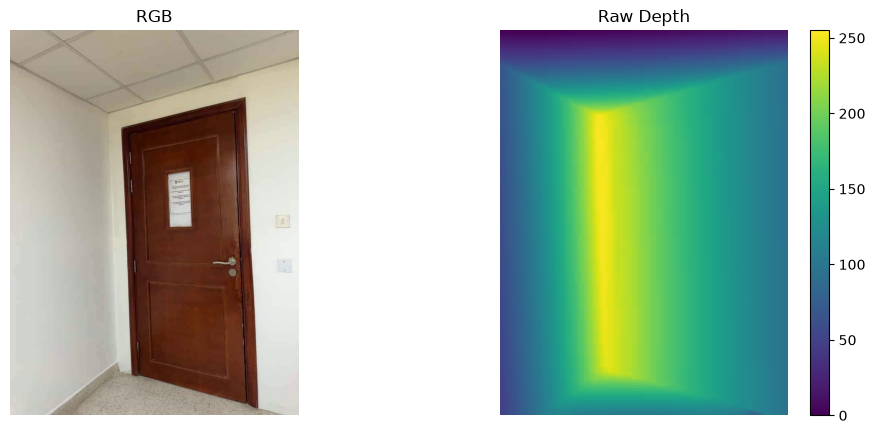

In [6]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Dataset
DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")

# First frame
rgb_files = sorted([
    f for f in os.listdir(RGB_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

depth_files = sorted([
    f for f in os.listdir(DEPTH_DIR)
    if f.lower().endswith(".npy")
])

rgb = np.array(Image.open(os.path.join(RGB_DIR, rgb_files[0])))
depth = np.load(os.path.join(DEPTH_DIR, depth_files[0]))

print("RGB shape:", rgb.shape)
print("Depth shape:", depth.shape)
print("Depth dtype:", depth.dtype)
print("Depth range:", np.nanmin(depth), "to", np.nanmax(depth))

# Visualize them
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rgb)
plt.title("RGB")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(depth)
plt.title("Raw Depth")
plt.colorbar()
plt.axis("off")

plt.show()

In [7]:
import numpy as np
import open3d as o3d
from PIL import Image
import os

# ============================================================
# DATASET
# ============================================================

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")

# ============================================================
# LOAD FRAME
# ============================================================

rgb_files = sorted([
    f for f in os.listdir(RGB_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

depth_files = sorted([
    f for f in os.listdir(DEPTH_DIR)
    if f.lower().endswith(".npy")
])

idx = 0

rgb = np.array(
    Image.open(os.path.join(RGB_DIR, rgb_files[idx]))
).astype(np.uint8)

depth = np.load(
    os.path.join(DEPTH_DIR, depth_files[idx])
).astype(np.float32)

print("RGB:", rgb.shape)
print("Depth:", depth.shape)

# ============================================================
# CAMERA INTRINSICS
# Original RGB calibration
# ============================================================

fx_rgb = 750.0
fy_rgb = 750.0
cx_rgb = 360.0
cy_rgb = 478.92

# ============================================================
# DEPTH RESOLUTION
# ============================================================

depth_h, depth_w = depth.shape
rgb_h, rgb_w = rgb.shape[:2]

# Scale RGB intrinsics to depth resolution
sx = depth_w / rgb_w
sy = depth_h / rgb_h

fx = fx_rgb * sx
fy = fy_rgb * sy
cx = cx_rgb * sx
cy = cy_rgb * sy

print("\nDepth intrinsics:")
print("fx =", fx)
print("fy =", fy)
print("cx =", cx)
print("cy =", cy)

# ============================================================
# RESIZE RGB TO DEPTH RESOLUTION
# ============================================================

rgb_depth = np.array(
    Image.fromarray(rgb).resize(
        (depth_w, depth_h),
        Image.Resampling.BILINEAR
    )
)

# RGB -> Open3D expects RGB values in [0,1]
colors = rgb_depth.astype(np.float32) / 255.0

# ============================================================
# VALID DEPTH
# ============================================================

valid = np.isfinite(depth) & (depth > 0)

# Normalize depth ONLY for visualization/reconstruction test
# This does NOT claim that the values are metric metres.
z = depth.copy()

# Remove extreme invalid values
z_min = np.percentile(z[valid], 1)
z_max = np.percentile(z[valid], 99)

valid &= (z >= z_min) & (z <= z_max)

print("\nValid depth pixels:", valid.sum())
print("Depth percentile range:", z_min, "to", z_max)

# ============================================================
# BACK-PROJECTION
# ============================================================

v, u = np.where(valid)

Z = z[v, u]

X = (u - cx) * Z / fx
Y = (v - cy) * Z / fy

points = np.stack([X, Y, Z], axis=1)
point_colors = colors[v, u]

print("\n3D points:", points.shape)

# ============================================================
# CREATE OPEN3D CLOUD
# ============================================================

pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(points)
pcd.colors = o3d.utility.Vector3dVector(point_colors)

# Downsample
pcd = pcd.voxel_down_sample(voxel_size=1.0)

print("Points after downsampling:", len(pcd.points))

# ============================================================
# SAVE
# ============================================================

OUTPUT = "D:/VLM-maps/outputs/frame_000_pointcloud.ply"

o3d.io.write_point_cloud(
    OUTPUT,
    pcd
)

print("\nSaved:", OUTPUT)

RGB: (960, 720, 3)
Depth: (256, 192)

Depth intrinsics:
fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

Valid depth pixels: 48152
Depth percentile range: 11.0 to 250.0

3D points: (48152, 3)
Points after downsampling: 33081

Saved: D:/VLM-maps/outputs/frame_000_pointcloud.ply


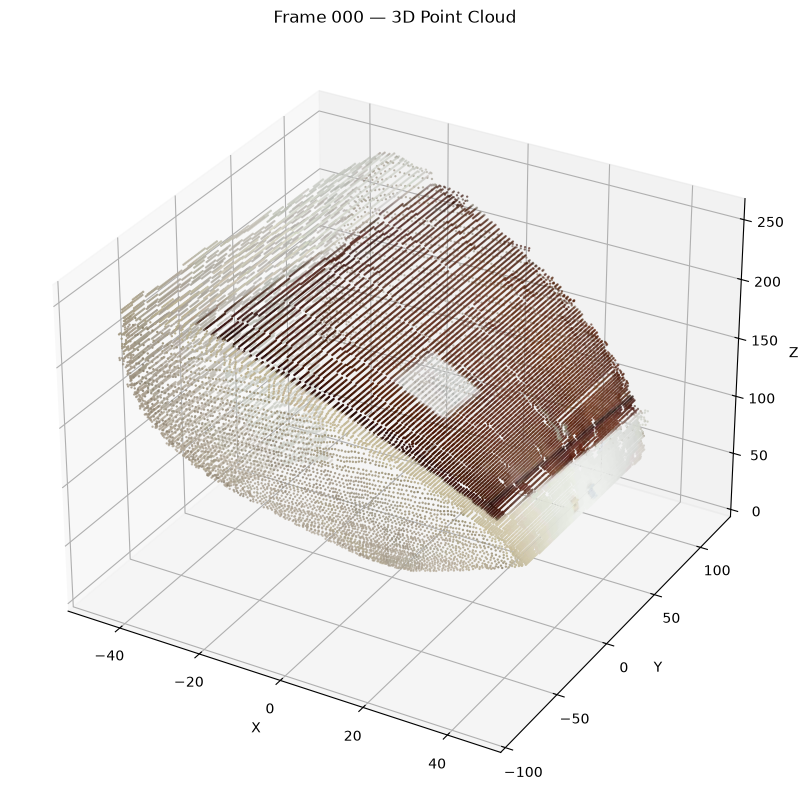

In [8]:
import open3d as o3d
import matplotlib.pyplot as plt
import numpy as np

pcd = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/frame_000_pointcloud.ply"
)

points = np.asarray(pcd.points)
colors = np.asarray(pcd.colors)

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    c=colors,
    s=0.5
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Frame 000 — 3D Point Cloud")

plt.show()

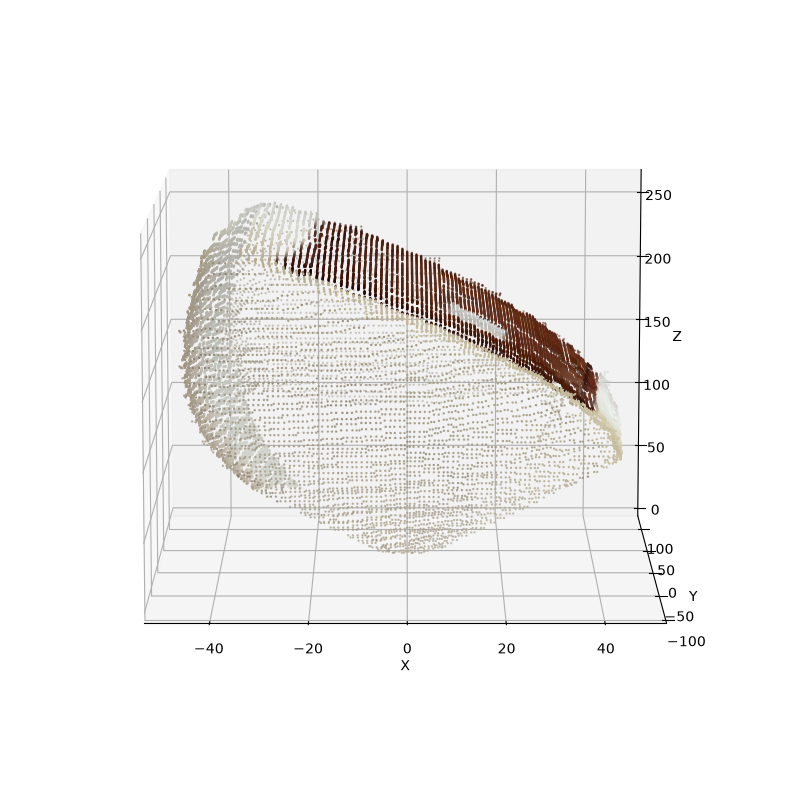

In [9]:
fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    c=colors,
    s=0.5
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

# Change these to inspect different views
ax.view_init(elev=10, azim=-90)

plt.show()

In [10]:
import os
import numpy as np
import open3d as o3d
from PIL import Image

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")

rgb_files = sorted([
    f for f in os.listdir(RGB_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
])

depth_files = sorted([
    f for f in os.listdir(DEPTH_DIR)
    if f.lower().endswith(".npy")
])

# Middle 10 frames
frame_indices = list(range(1040, 1050))

# Original RGB calibration
fx_rgb = 750.0
fy_rgb = 750.0
cx_rgb = 360.0
cy_rgb = 478.92

all_pcds = []

for idx in frame_indices:

    rgb = np.array(
        Image.open(os.path.join(RGB_DIR, rgb_files[idx]))
    ).astype(np.uint8)

    depth = np.load(
        os.path.join(DEPTH_DIR, depth_files[idx])
    ).astype(np.float32)

    depth_h, depth_w = depth.shape
    rgb_h, rgb_w = rgb.shape[:2]

    # Scale intrinsics to depth resolution
    sx = depth_w / rgb_w
    sy = depth_h / rgb_h

    fx = fx_rgb * sx
    fy = fy_rgb * sy
    cx = cx_rgb * sx
    cy = cy_rgb * sy

    # Resize RGB to depth resolution
    rgb_depth = np.array(
        Image.fromarray(rgb).resize(
            (depth_w, depth_h),
            Image.Resampling.BILINEAR
        )
    )

    colors = rgb_depth.astype(np.float32) / 255.0

    # Valid depth
    valid = np.isfinite(depth) & (depth > 0)

    if valid.sum() == 0:
        continue

    z_min = np.percentile(depth[valid], 1)
    z_max = np.percentile(depth[valid], 99)

    valid &= (depth >= z_min) & (depth <= z_max)

    v, u = np.where(valid)

    Z = depth[v, u]

    X = (u - cx) * Z / fx
    Y = (v - cy) * Z / fy

    points = np.stack([X, Y, Z], axis=1)
    point_colors = colors[v, u]

    pcd = o3d.geometry.PointCloud()
    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(point_colors)

    # Light downsampling
    pcd = pcd.voxel_down_sample(voxel_size=1.0)

    all_pcds.append(pcd)

    print(
        f"Frame {idx}: "
        f"{len(points):,} raw → "
        f"{len(pcd.points):,} points"
    )

print("\nGenerated:", len(all_pcds), "point clouds")

Frame 1040: 48,345 raw → 31,132 points
Frame 1041: 48,220 raw → 31,327 points
Frame 1042: 48,312 raw → 31,068 points
Frame 1043: 48,238 raw → 31,264 points
Frame 1044: 48,247 raw → 30,083 points


Frame 1045: 48,249 raw → 30,384 points
Frame 1046: 48,272 raw → 30,662 points
Frame 1047: 48,227 raw → 30,860 points
Frame 1048: 48,271 raw → 31,144 points
Frame 1049: 48,293 raw → 30,983 points

Generated: 10 point clouds


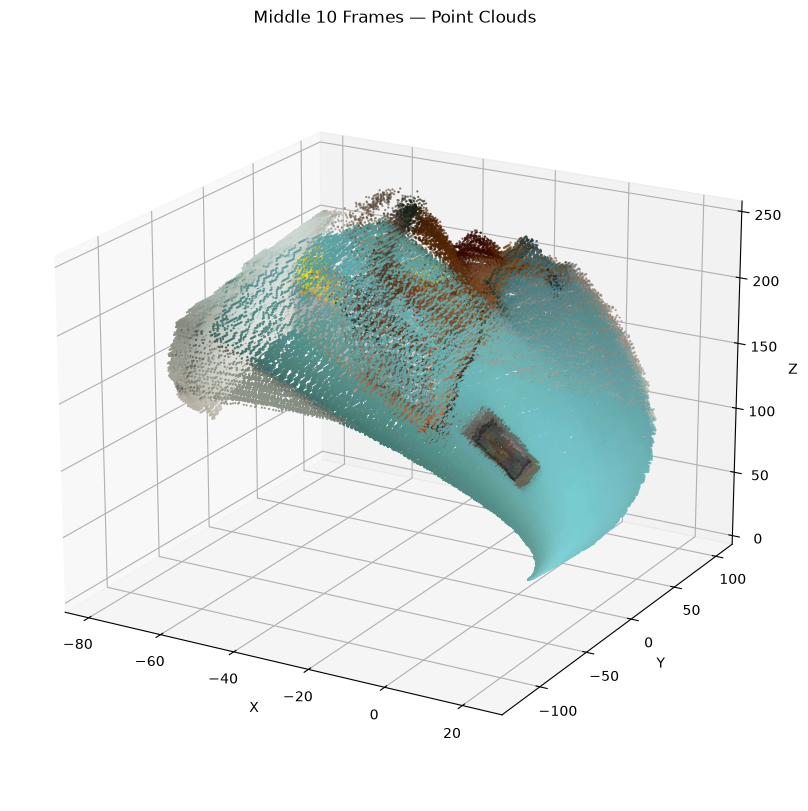

In [11]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(12, 10))
ax = fig.add_subplot(111, projection="3d")

for i, pcd in enumerate(all_pcds):
    points = np.asarray(pcd.points)
    colors = np.asarray(pcd.colors)

    ax.scatter(
        points[:, 0],
        points[:, 1],
        points[:, 2],
        c=colors,
        s=0.4
    )

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Middle 10 Frames — Point Clouds")

# Better viewing angle
ax.view_init(elev=20, azim=-60)

plt.show()

In [12]:
import os
import numpy as np
import open3d as o3d
from PIL import Image

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

rgb_dir = os.path.join(DATASET, "rgb")
depth_dir = os.path.join(DATASET, "depth")

# 30 frames spread across the whole sequence
frame_indices = np.linspace(0, 2090, 30, dtype=int)

# Depth-resolution intrinsics
fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

all_points = []
all_colors = []

for idx in frame_indices:

    rgb_path = os.path.join(rgb_dir, f"{idx:06d}.png")
    depth_path = os.path.join(depth_dir, f"{idx:06d}.npy")

    rgb = np.array(Image.open(rgb_path))
    depth = np.load(depth_path)

    # Resize RGB to depth resolution
    rgb_small = np.array(
        Image.fromarray(rgb).resize(
            (depth.shape[1], depth.shape[0])
        )
    )

    h, w = depth.shape

    u, v = np.meshgrid(
        np.arange(w),
        np.arange(h)
    )

    valid = np.isfinite(depth) & (depth > 0)

    Z = depth[valid]

    # Remove extreme depth values
    low, high = np.percentile(Z, [1, 99])
    valid &= (depth >= low) & (depth <= high)

    u_valid = u[valid]
    v_valid = v[valid]
    Z = depth[valid]

    # Back-project into 3D
    X = (u_valid - cx) * Z / fx
    Y = (v_valid - cy) * Z / fy

    points = np.column_stack((X, Y, Z))

    colors = rgb_small[valid] / 255.0

    all_points.append(points)
    all_colors.append(colors)

    print(
        f"Frame {idx:04d}: "
        f"{len(points):,} points"
    )

# Combine all frames
all_points = np.vstack(all_points)
all_colors = np.vstack(all_colors)

print("\n==============================")
print("Frames processed:", len(frame_indices))
print("Total points:", f"{len(all_points):,}")
print("==============================")

# Create point cloud
pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(all_points)
pcd.colors = o3d.utility.Vector3dVector(all_colors)

# Downsample
pcd = pcd.voxel_down_sample(voxel_size=1.0)

print("Points after downsampling:", f"{len(pcd.points):,}")

# Save
output_path = "D:/VLM-maps/outputs/30_frame_pointcloud.ply"
o3d.io.write_point_cloud(output_path, pcd)

print("Saved:", output_path)

Frame 0000: 48,152 points
Frame 0072: 48,236 points
Frame 0144: 48,244 points
Frame 0216: 48,225 points
Frame 0288: 48,270 points
Frame 0360: 48,215 points
Frame 0432: 48,350 points
Frame 0504: 48,390 points
Frame 0576: 48,206 points
Frame 0648: 48,231 points
Frame 0720: 48,332 points
Frame 0792: 48,306 points
Frame 0864: 48,357 points
Frame 0936: 48,240 points
Frame 1008: 48,248 points
Frame 1081: 48,325 points


Frame 1153: 48,238 points
Frame 1225: 48,233 points
Frame 1297: 48,183 points
Frame 1369: 48,307 points
Frame 1441: 48,263 points
Frame 1513: 48,204 points
Frame 1585: 48,221 points
Frame 1657: 48,221 points
Frame 1729: 48,225 points
Frame 1801: 48,207 points
Frame 1873: 48,202 points
Frame 1945: 48,302 points
Frame 2017: 48,387 points
Frame 2090: 48,484 points

Frames processed: 30
Total points: 1,448,004


Points after downsampling: 875,631
Saved: D:/VLM-maps/outputs/30_frame_pointcloud.ply


In [13]:
import os
import numpy as np
import open3d as o3d
from PIL import Image
from scipy.spatial.transform import Rotation

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

rgb_dir = os.path.join(DATASET, "rgb")
depth_dir = os.path.join(DATASET, "depth")
poses_path = os.path.join(DATASET, "poses.txt")

# Same 30 frames
frame_indices = np.linspace(0, 2090, 30, dtype=int)

# Depth-resolution camera intrinsics
fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

# IMPORTANT:
# Provisional conversion from your 0-255 depth representation to meters.
# We can calibrate this later.
DEPTH_SCALE = 0.02

poses = np.loadtxt(poses_path)

all_world_points = []
all_colors = []

for idx in frame_indices:

    # -------------------------
    # Load RGB + depth
    # -------------------------
    rgb_path = os.path.join(rgb_dir, f"{idx:06d}.png")
    depth_path = os.path.join(depth_dir, f"{idx:06d}.npy")

    rgb = np.array(Image.open(rgb_path))
    depth = np.load(depth_path)

    # Resize RGB to depth resolution
    rgb_small = np.array(
        Image.fromarray(rgb).resize(
            (depth.shape[1], depth.shape[0])
        )
    )

    h, w = depth.shape

    u, v = np.meshgrid(
        np.arange(w),
        np.arange(h)
    )

    # -------------------------
    # Valid depth
    # -------------------------
    valid = (
        np.isfinite(depth) &
        (depth > 0)
    )

    values = depth[valid]

    low, high = np.percentile(values, [1, 99])

    valid &= (
        (depth >= low) &
        (depth <= high)
    )

    u_valid = u[valid]
    v_valid = v[valid]

    # Convert depth to provisional meters
    Z = depth[valid] * DEPTH_SCALE

    # -------------------------
    # Camera-coordinate 3D
    # -------------------------
    X = (u_valid - cx) * Z / fx
    Y = (v_valid - cy) * Z / fy

    camera_points = np.column_stack([
        X, Y, Z
    ])

    colors = rgb_small[valid] / 255.0

    # -------------------------
    # Get pose
    # -------------------------
    pose = poses[idx]

    # Assumed format:
    # [tx, ty, tz, qx, qy, qz, qw]

    t = pose[:3]
    q = pose[3:7]

    # Quaternion -> rotation matrix
    R = Rotation.from_quat(q).as_matrix()

    # -------------------------
    # Camera -> World
    # -------------------------
    world_points = (
        camera_points @ R.T
    ) + t

    all_world_points.append(world_points)
    all_colors.append(colors)

    print(
        f"Frame {idx:04d}: "
        f"{len(camera_points):,} points "
        f"-> world coordinates"
    )

# -------------------------
# Combine all frames
# -------------------------
all_world_points = np.vstack(all_world_points)
all_colors = np.vstack(all_colors)

print("\n==============================")
print("FUSION COMPLETE")
print("==============================")
print("Frames:", len(frame_indices))
print("Raw fused points:", f"{len(all_world_points):,}")

# -------------------------
# Create Open3D cloud
# -------------------------
pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(
    all_world_points
)

pcd.colors = o3d.utility.Vector3dVector(
    all_colors
)

# 2 cm voxel downsampling
pcd = pcd.voxel_down_sample(
    voxel_size=0.02
)

print(
    "After downsampling:",
    f"{len(pcd.points):,}"
)

# -------------------------
# Save
# -------------------------
output_path = "D:/VLM-maps/outputs/fused_30_frames.ply"

o3d.io.write_point_cloud(
    output_path,
    pcd
)

print("Saved:", output_path)

Frame 0000: 48,152 points -> world coordinates
Frame 0072: 48,236 points -> world coordinates
Frame 0144: 48,244 points -> world coordinates
Frame 0216: 48,225 points -> world coordinates
Frame 0288: 48,270 points -> world coordinates
Frame 0360: 48,215 points -> world coordinates
Frame 0432: 48,350 points -> world coordinates
Frame 0504: 48,390 points -> world coordinates
Frame 0576: 48,206 points -> world coordinates
Frame 0648: 48,231 points -> world coordinates
Frame 0720: 48,332 points -> world coordinates
Frame 0792: 48,306 points -> world coordinates
Frame 0864: 48,357 points -> world coordinates
Frame 0936: 48,240 points -> world coordinates
Frame 1008: 48,248 points -> world coordinates
Frame 1081: 48,325 points -> world coordinates


Frame 1153: 48,238 points -> world coordinates
Frame 1225: 48,233 points -> world coordinates
Frame 1297: 48,183 points -> world coordinates
Frame 1369: 48,307 points -> world coordinates
Frame 1441: 48,263 points -> world coordinates
Frame 1513: 48,204 points -> world coordinates
Frame 1585: 48,221 points -> world coordinates
Frame 1657: 48,221 points -> world coordinates
Frame 1729: 48,225 points -> world coordinates
Frame 1801: 48,207 points -> world coordinates
Frame 1873: 48,202 points -> world coordinates
Frame 1945: 48,302 points -> world coordinates
Frame 2017: 48,387 points -> world coordinates
Frame 2090: 48,484 points -> world coordinates

FUSION COMPLETE
Frames: 30
Raw fused points: 1,448,004


After downsampling: 1,037,188
Saved: D:/VLM-maps/outputs/fused_30_frames.ply


In [14]:
import os

print("WORKING DIRECTORY:")
print(os.getcwd())

print("\nFILES IN D:/VLM-maps/outputs:")
for root, dirs, files in os.walk("D:/VLM-maps/outputs"):
    for f in files:
        print(os.path.join(root, f))

WORKING DIRECTORY:
D:\VLM-maps

FILES IN D:/VLM-maps/outputs:
D:/VLM-maps/outputs\30_frame_pointcloud.ply
D:/VLM-maps/outputs\frame_000_pointcloud.ply
D:/VLM-maps/outputs\fused_30_frames.ply
D:/VLM-maps/outputs\fusion_forward_test.ply
D:/VLM-maps/outputs\fusion_inverse_test.ply
D:/VLM-maps/outputs\test_forward_002.ply
D:/VLM-maps/outputs\test_inverse_002.ply


In [15]:
import os

ply = "D:/VLM-maps/outputs/fused_30_frames.ply"

print("Exists:", os.path.exists(ply))

if os.path.exists(ply):
    print("Size:", os.path.getsize(ply) / (1024**2), "MB")

Exists: True
Size: 26.706968307495117 MB


In [16]:
import open3d as o3d

pcd = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/fused_30_frames.ply"
)

print(pcd)

PointCloud with 1037188 points.


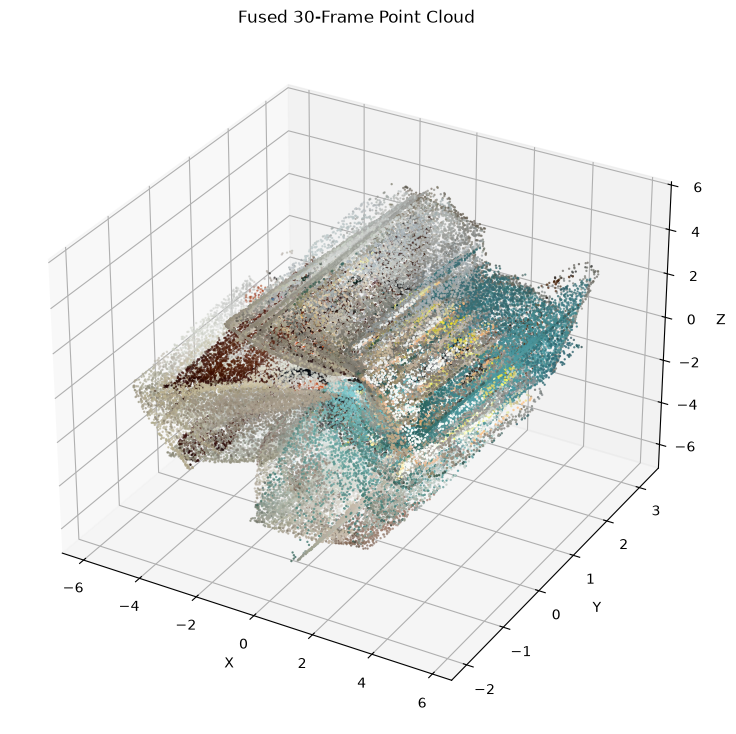

In [17]:
import matplotlib.pyplot as plt
import numpy as np

points = np.asarray(pcd.points)
colors = np.asarray(pcd.colors)

n = min(100000, len(points))
idx = np.random.choice(len(points), n, replace=False)

fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(
    points[idx, 0],
    points[idx, 1],
    points[idx, 2],
    c=colors[idx],
    s=0.5
)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Fused 30-Frame Point Cloud")

plt.show()

In [18]:
import numpy as np
import open3d as o3d
from scipy.spatial.transform import Rotation

# --------------------------------------------------
# Paths
# --------------------------------------------------
POSE_PATH = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/poses.txt"
PLY_PATH = "D:/VLM-maps/outputs/fused_30_frames.ply"

# Same 30 frames used for fusion
frame_indices = np.linspace(0, 2090, 30, dtype=int)

# --------------------------------------------------
# Load poses
# --------------------------------------------------
poses = np.loadtxt(POSE_PATH)

print("Pose shape:", poses.shape)
print("Pose format first row:")
print(poses[0])

selected = poses[frame_indices]

# Translation assuming [tx, ty, tz, qx, qy, qz, qw]
camera_positions = selected[:, :3]

print("\nCamera trajectory:")
print("X:", camera_positions[:,0].min(), "to", camera_positions[:,0].max())
print("Y:", camera_positions[:,1].min(), "to", camera_positions[:,1].max())
print("Z:", camera_positions[:,2].min(), "to", camera_positions[:,2].max())

trajectory_min = camera_positions.min(axis=0)
trajectory_max = camera_positions.max(axis=0)

print("\nTrajectory bounding-box size:")
print(trajectory_max - trajectory_min)

# --------------------------------------------------
# Load fused point cloud
# --------------------------------------------------
pcd = o3d.io.read_point_cloud(PLY_PATH)
points = np.asarray(pcd.points)

print("\nPoint cloud:")
print("Number of points:", len(points))

pc_min = points.min(axis=0)
pc_max = points.max(axis=0)
pc_center = points.mean(axis=0)

print("Min XYZ:", pc_min)
print("Max XYZ:", pc_max)
print("Center:", pc_center)

print("\nPoint-cloud bounding-box size:")
print(pc_max - pc_min)

# --------------------------------------------------
# Pose quaternion norms
# --------------------------------------------------
q = selected[:, 3:7]
q_norms = np.linalg.norm(q, axis=1)

print("\nQuaternion norms:")
print("min:", q_norms.min())
print("max:", q_norms.max())
print("mean:", q_norms.mean())

# --------------------------------------------------
# Camera travel distance
# --------------------------------------------------
travel = np.linalg.norm(
    camera_positions[-1] - camera_positions[0]
)

print("\nFirst → last camera displacement:", travel, "pose units")

# Pairwise trajectory extent
from scipy.spatial.distance import pdist

if len(camera_positions) > 1:
    distances = pdist(camera_positions)
    print("Maximum camera-to-camera distance:", distances.max())


Pose shape: (2091, 7)
Pose format first row:
[ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
  0.77898699]

Camera trajectory:
X: -1.0122720003128052 to 0.8368967771530151
Y: 0.1254657655954361 to 0.17370648682117462
Z: -1.349399447441101 to 0.09456147253513336

Trajectory bounding-box size:
[1.84916878 0.04824072 1.44396092]

Point cloud:
Number of points: 1037188
Min XYZ: [-5.91927105 -2.08091695 -6.29862496]
Max XYZ: [5.79101832 3.21779392 5.29661841]
Center: [ 0.04222292  0.42583335 -0.18511896]

Point-cloud bounding-box size:
[11.71028937  5.29871087 11.59524337]

Quaternion norms:
min: 0.9999999336790997
max: 1.000000095185346
mean: 0.9999999972968534

First → last camera displacement: 1.2557929054996784 pose units
Maximum camera-to-camera distance: 2.311928338332416


In [19]:
import numpy as np
import open3d as o3d
from scipy.spatial.transform import Rotation
from PIL import Image
import glob
import os

# ============================================================
# SETTINGS
# ============================================================

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(BASE, "rgb")
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

DEPTH_SCALE = 0.02

fx, fy = 200.0, 200.0
cx, cy = 96.0, 127.712

frame_indices = np.linspace(0, 2090, 30, dtype=int)

# ============================================================
# LOAD FILES
# ============================================================

def numeric_sort(files):
    def key(x):
        stem = os.path.splitext(os.path.basename(x))[0]
        nums = ''.join(c for c in stem if c.isdigit())
        return int(nums) if nums else 0
    return sorted(files, key=key)

rgb_files = numeric_sort(
    glob.glob(os.path.join(RGB_DIR, "*"))
)

depth_files = numeric_sort(
    glob.glob(os.path.join(DEPTH_DIR, "*"))
)

poses = np.loadtxt(POSE_PATH)

print("RGB files:", len(rgb_files))
print("Depth files:", len(depth_files))
print("Poses:", len(poses))

# ============================================================
# COLORS FOR 30 FRAMES
# ============================================================

colors = np.linspace(0, 1, len(frame_indices))

# ============================================================
# STORAGE
# ============================================================

forward_points = []
forward_colors = []

inverse_points = []
inverse_colors = []

# ============================================================
# PROCESS SAME 30 FRAMES
# ============================================================

for frame_number, idx in enumerate(frame_indices):

    # ----------------------------
    # Load RGB
    # ----------------------------
    rgb = np.asarray(Image.open(rgb_files[idx]).convert("RGB"))

    # RGB is 960x720, depth is 256x192
    # Resize RGB to depth resolution
    rgb_small = np.asarray(
        Image.fromarray(rgb).resize((192, 256))
    )

    # ----------------------------
    # Load depth
    # ----------------------------
    depth = np.load(depth_files[idx]).astype(np.float32)

    # Convert provisional depth to meters
    z = depth * DEPTH_SCALE

    # ----------------------------
    # Back-project
    # ----------------------------
    h, w = z.shape

    u, v = np.meshgrid(
        np.arange(w),
        np.arange(h)
    )

    valid = (
        np.isfinite(z) &
        (z > 0)
    )

    z_valid = z[valid]
    u_valid = u[valid]
    v_valid = v[valid]

    x_valid = (u_valid - cx) * z_valid / fx
    y_valid = (v_valid - cy) * z_valid / fy

    cam_points = np.column_stack([
        x_valid,
        y_valid,
        z_valid
    ])

    rgb_valid = rgb_small[valid] / 255.0

    # ========================================================
    # POSE
    # ========================================================

    pose = poses[idx]

    t = pose[:3]

    # scipy expects [qx, qy, qz, qw]
    q = pose[3:7]

    R = Rotation.from_quat(q).as_matrix()

    # ========================================================
    # A) FORWARD: CAMERA -> WORLD
    #
    # p_world = R p_camera + t
    # ========================================================

    world_forward = cam_points @ R.T + t

    forward_points.append(world_forward)
    forward_colors.append(rgb_valid)

    # ========================================================
    # B) INVERSE: WORLD -> CAMERA inverted
    #
    # p_world = R.T (p_camera - t)
    #
    # row-vector equivalent:
    # p_world = (p_camera - t) @ R
    # ========================================================

    world_inverse = (cam_points - t) @ R

    inverse_points.append(world_inverse)
    inverse_colors.append(rgb_valid)

    print(
        f"Frame {idx}: {len(cam_points):,} points"
    )

# ============================================================
# COMBINE
# ============================================================

forward_points = np.vstack(forward_points)
forward_colors = np.vstack(forward_colors)

inverse_points = np.vstack(inverse_points)
inverse_colors = np.vstack(inverse_colors)

# ============================================================
# SAVE FORWARD
# ============================================================

pcd_forward = o3d.geometry.PointCloud()
pcd_forward.points = o3d.utility.Vector3dVector(forward_points)
pcd_forward.colors = o3d.utility.Vector3dVector(forward_colors)

pcd_forward = pcd_forward.voxel_down_sample(
    voxel_size=0.015
)

forward_path = "D:/VLM-maps/outputs/fusion_forward_test.ply"

o3d.io.write_point_cloud(
    forward_path,
    pcd_forward
)

# ============================================================
# SAVE INVERSE
# ============================================================

pcd_inverse = o3d.geometry.PointCloud()
pcd_inverse.points = o3d.utility.Vector3dVector(inverse_points)
pcd_inverse.colors = o3d.utility.Vector3dVector(inverse_colors)

pcd_inverse = pcd_inverse.voxel_down_sample(
    voxel_size=0.015
)

inverse_path = "D:/VLM-maps/outputs/fusion_inverse_test.ply"

o3d.io.write_point_cloud(
    inverse_path,
    pcd_inverse
)

# ============================================================
# NUMERICAL COMPARISON
# ============================================================

for name, pts in [
    ("FORWARD", np.asarray(pcd_forward.points)),
    ("INVERSE", np.asarray(pcd_inverse.points))
]:

    print("\n==============================")
    print(name)
    print("==============================")

    print("Points:", len(pts))
    print("Min:", pts.min(axis=0))
    print("Max:", pts.max(axis=0))
    print("Size:", pts.max(axis=0) - pts.min(axis=0))
    print("Center:", pts.mean(axis=0))

print("\nSaved:")
print(forward_path)
print(inverse_path)


RGB files: 2091
Depth files: 2091
Poses: 2091
Frame 0: 49,128 points
Frame 72: 49,136 points
Frame 144: 49,144 points
Frame 216: 49,152 points
Frame 288: 49,152 points
Frame 360: 49,152 points
Frame 432: 49,152 points
Frame 504: 49,152 points
Frame 576: 49,098 points
Frame 648: 49,152 points
Frame 720: 49,144 points


Frame 792: 49,144 points
Frame 864: 49,152 points
Frame 936: 49,152 points
Frame 1008: 49,152 points
Frame 1081: 49,152 points
Frame 1153: 49,152 points
Frame 1225: 49,152 points
Frame 1297: 49,152 points
Frame 1369: 49,152 points
Frame 1441: 49,152 points
Frame 1513: 49,134 points
Frame 1585: 49,055 points
Frame 1657: 49,152 points


Frame 1729: 49,152 points
Frame 1801: 49,150 points
Frame 1873: 49,152 points
Frame 1945: 49,152 points
Frame 2017: 49,152 points
Frame 2090: 49,149 points



FORWARD
Points: 1209798
Min: [-6.03405531 -2.08091695 -6.55085827]
Max: [5.85106853 3.29479498 5.37571792]
Size: [11.88512384  5.37571193 11.9265762 ]
Center: [ 0.05688515  0.423818   -0.19481178]

INVERSE
Points: 1209358


Min: [-5.87332161 -2.79952306 -6.47145076]
Max: [6.01019051 2.9307908  5.58952219]


Size: [11.88351211  5.73031386 12.06097296]
Center: [-0.3114633  -0.09532358 -0.13679046]

Saved:
D:/VLM-maps/outputs/fusion_forward_test.ply
D:/VLM-maps/outputs/fusion_inverse_test.ply


In [20]:
import numpy as np
import open3d as o3d
from scipy.spatial.transform import Rotation
from PIL import Image
import glob
import os

# ============================================================
# SETTINGS
# ============================================================

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(BASE, "rgb")
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

DEPTH_SCALE = 0.02

fx, fy = 200.0, 200.0
cx, cy = 96.0, 127.712

frame_indices = np.linspace(0, 2090, 30, dtype=int)

# ============================================================
# FILES
# ============================================================

def numeric_sort(files):
    def key(x):
        stem = os.path.splitext(os.path.basename(x))[0]
        nums = ''.join(c for c in stem if c.isdigit())
        return int(nums) if nums else 0
    return sorted(files, key=key)

rgb_files = numeric_sort(
    glob.glob(os.path.join(RGB_DIR, "*"))
)

depth_files = numeric_sort(
    glob.glob(os.path.join(DEPTH_DIR, "*.npy"))
)

poses = np.loadtxt(POSE_PATH)

print("RGB files:", len(rgb_files))
print("Depth .npy files:", len(depth_files))
print("Poses:", len(poses))

print("\nFirst RGB:", os.path.basename(rgb_files[0]))
print("First depth:", os.path.basename(depth_files[0]))

# ============================================================
# STORAGE
# ============================================================

forward_points = []
forward_colors = []

inverse_points = []
inverse_colors = []

# ============================================================
# PROCESS SAME 30 FRAMES
# ============================================================

for frame_number, idx in enumerate(frame_indices):

    # --------------------------------------------------------
    # RGB
    # --------------------------------------------------------

    rgb = np.asarray(
        Image.open(rgb_files[idx]).convert("RGB")
    )

    # RGB: 720 x 960
    # Depth: 256 x 192
    rgb_small = np.asarray(
        Image.fromarray(rgb).resize((192, 256))
    )

    # --------------------------------------------------------
    # DEPTH
    # IMPORTANT: depth is .npy, not an image
    # --------------------------------------------------------

    depth = np.load(depth_files[idx]).astype(np.float32)

    if depth.shape != (256, 192):
        print(
            f"WARNING frame {idx}: depth shape = {depth.shape}"
        )

    # provisional conversion
    z = depth * DEPTH_SCALE

    # --------------------------------------------------------
    # BACK-PROJECTION
    # --------------------------------------------------------

    h, w = z.shape

    u, v = np.meshgrid(
        np.arange(w),
        np.arange(h)
    )

    valid = (
        np.isfinite(z) &
        (z > 0)
    )

    z_valid = z[valid]
    u_valid = u[valid]
    v_valid = v[valid]

    x_valid = (u_valid - cx) * z_valid / fx
    y_valid = (v_valid - cy) * z_valid / fy

    cam_points = np.column_stack([
        x_valid,
        y_valid,
        z_valid
    ])

    rgb_valid = rgb_small[valid] / 255.0

    # --------------------------------------------------------
    # POSE
    # assumed:
    # [tx, ty, tz, qx, qy, qz, qw]
    # --------------------------------------------------------

    pose = poses[idx]

    t = pose[:3]
    q = pose[3:7]

    R = Rotation.from_quat(q).as_matrix()

    # --------------------------------------------------------
    # A: CAMERA -> WORLD
    # --------------------------------------------------------

    world_forward = cam_points @ R.T + t

    forward_points.append(world_forward)
    forward_colors.append(rgb_valid)

    # --------------------------------------------------------
    # B: INVERSE POSE
    # --------------------------------------------------------

    world_inverse = (cam_points - t) @ R

    inverse_points.append(world_inverse)
    inverse_colors.append(rgb_valid)

    print(
        f"Frame {idx}: {len(cam_points):,} points"
    )

# ============================================================
# COMBINE
# ============================================================

forward_points = np.vstack(forward_points)
forward_colors = np.vstack(forward_colors)

inverse_points = np.vstack(inverse_points)
inverse_colors = np.vstack(inverse_colors)

# ============================================================
# FORWARD CLOUD
# ============================================================

pcd_forward = o3d.geometry.PointCloud()

pcd_forward.points = o3d.utility.Vector3dVector(
    forward_points
)

pcd_forward.colors = o3d.utility.Vector3dVector(
    forward_colors
)

pcd_forward = pcd_forward.voxel_down_sample(
    voxel_size=0.015
)

forward_path = "D:/VLM-maps/outputs/fusion_forward_test.ply"

o3d.io.write_point_cloud(
    forward_path,
    pcd_forward
)

# ============================================================
# INVERSE CLOUD
# ============================================================

pcd_inverse = o3d.geometry.PointCloud()

pcd_inverse.points = o3d.utility.Vector3dVector(
    inverse_points
)

pcd_inverse.colors = o3d.utility.Vector3dVector(
    inverse_colors
)

pcd_inverse = pcd_inverse.voxel_down_sample(
    voxel_size=0.015
)

inverse_path = "D:/VLM-maps/outputs/fusion_inverse_test.ply"

o3d.io.write_point_cloud(
    inverse_path,
    pcd_inverse
)

# ============================================================
# NUMERICAL COMPARISON
# ============================================================

for name, pts in [
    ("FORWARD", np.asarray(pcd_forward.points)),
    ("INVERSE", np.asarray(pcd_inverse.points))
]:

    print("\n==============================")
    print(name)
    print("==============================")

    print("Points:", len(pts))
    print("Min:", pts.min(axis=0))
    print("Max:", pts.max(axis=0))
    print("Size:", pts.max(axis=0) - pts.min(axis=0))
    print("Center:", pts.mean(axis=0))

print("\nSaved:")
print(forward_path)
print(inverse_path)


RGB files: 2091
Depth .npy files: 2091
Poses: 2091

First RGB: 000000.png
First depth: 000000.npy
Frame 0: 49,128 points
Frame 72: 49,136 points
Frame 144: 49,144 points


Frame 216: 49,152 points
Frame 288: 49,152 points
Frame 360: 49,152 points
Frame 432: 49,152 points
Frame 504: 49,152 points


Frame 576: 49,098 points
Frame 648: 49,152 points
Frame 720: 49,144 points
Frame 792: 49,144 points
Frame 864: 49,152 points
Frame 936: 49,152 points
Frame 1008: 49,152 points
Frame 1081: 49,152 points
Frame 1153: 49,152 points
Frame 1225: 49,152 points


Frame 1297: 49,152 points
Frame 1369: 49,152 points
Frame 1441: 49,152 points
Frame 1513: 49,134 points
Frame 1585: 49,055 points
Frame 1657: 49,152 points
Frame 1729: 49,152 points
Frame 1801: 49,150 points
Frame 1873: 49,152 points
Frame 1945: 49,152 points
Frame 2017: 49,152 points
Frame 2090: 49,149 points



FORWARD
Points: 1209798
Min: [-6.03405531 -2.08091695 -6.55085827]
Max: [5.85106853 3.29479498 5.37571792]
Size: [11.88512384  5.37571193 11.9265762 ]
Center: [ 0.05688515  0.423818   -0.19481178]

INVERSE
Points: 1209358
Min: [-5.87332161 -2.79952306 -6.47145076]
Max: [6.01019051 2.9307908  5.58952219]
Size: [11.88351211  5.73031386 12.06097296]
Center: [-0.3114633  -0.09532358 -0.13679046]

Saved:
D:/VLM-maps/outputs/fusion_forward_test.ply
D:/VLM-maps/outputs/fusion_inverse_test.ply


In [21]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

poses = np.loadtxt(POSE_PATH)

# Examine several depth frames
indices = [0, 500, 1000, 1500, 2090]

print("RAW DEPTH STATISTICS")
print("=" * 60)

for idx in indices:

    depth = np.load(
        os.path.join(DEPTH_DIR, f"{idx:06d}.npy")
    ).astype(np.float32)

    valid = depth[np.isfinite(depth) & (depth > 0)]

    print(f"\nFrame {idx}")
    print("shape:", depth.shape)
    print("dtype:", depth.dtype)
    print("min:", valid.min())
    print("max:", valid.max())
    print("mean:", valid.mean())
    print("median:", np.median(valid))
    print("percentiles:",
          np.percentile(valid, [1, 5, 25, 50, 75, 95, 99]))

# ----------------------------------------------------------
# Pose movement statistics
# ----------------------------------------------------------

translation = poses[:, :3]

step_distances = np.linalg.norm(
    np.diff(translation, axis=0),
    axis=1
)

print("\n\nPOSE TRANSLATION STATISTICS")
print("=" * 60)

print("Translation min:", translation.min(axis=0))
print("Translation max:", translation.max(axis=0))

print("\nConsecutive-frame movement:")
print("min:", step_distances.min())
print("max:", step_distances.max())
print("mean:", step_distances.mean())
print("median:", np.median(step_distances))

print("\nTotal trajectory displacement:")
print(
    np.linalg.norm(
        translation[-1] - translation[0]
    )
)


RAW DEPTH STATISTICS

Frame 0
shape: (256, 192)
dtype: float32
min: 1.0
max: 255.0
mean: 139.31577
median: 135.0
percentiles: [ 11.  40. 102. 135. 182. 235. 250.]

Frame 500
shape: (256, 192)
dtype: float32
min: 3.0
max: 255.0
mean: 120.83905
median: 125.0
percentiles: [  9.  18.  67. 125. 167. 229. 245.]

Frame 1000
shape: (256, 192)
dtype: float32
min: 3.0
max: 255.0
mean: 139.8103
median: 150.0
percentiles: [ 17.51  51.    95.   150.   181.   220.   238.  ]

Frame 1500
shape: (256, 192)
dtype: float32
min: 1.0
max: 255.0
mean: 133.1252
median: 132.0
percentiles: [  8.  33. 102. 132. 172. 224. 242.]

Frame 2090
shape: (256, 192)
dtype: float32
min: 1.0
max: 255.0
mean: 165.12839
median: 187.0
percentiles: [ 15.  39. 114. 187. 217. 248. 252.]


POSE TRANSLATION STATISTICS
Translation min: [-1.02564287  0.11377442 -1.35338497]
Translation max: [0.83824354 0.17513077 0.10371996]

Consecutive-frame movement:
min: 3.3227101109067135e-05
max: 0.013374991471840283
mean: 0.002397303782428813

In [22]:
import numpy as np
import open3d as o3d
from PIL import Image
from scipy.spatial.transform import Rotation
import os

# ============================================================
# PATHS
# ============================================================

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(BASE, "rgb")
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

poses = np.loadtxt(POSE_PATH)

# ============================================================
# CAMERA INTRINSICS AT DEPTH RESOLUTION
# ============================================================

fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

# ============================================================
# SELECT FRAME PAIRS
# ============================================================

pairs = [
    (0, 72),
    (500, 576),
    (1000, 1076),
    (1500, 1576),
    (2017, 2090),
]

# Candidate metric scales
scales = np.linspace(
    0.002,
    0.08,
    40
)

# ============================================================
# LOAD ONE FRAME
# ============================================================

def load_camera_points(idx, scale):

    depth = np.load(
        os.path.join(
            DEPTH_DIR,
            f"{idx:06d}.npy"
        )
    ).astype(np.float32)

    h, w = depth.shape

    z = depth * scale

    u, v = np.meshgrid(
        np.arange(w),
        np.arange(h)
    )

    valid = (
        np.isfinite(z) &
        (z > 0)
    )

    z = z[valid]
    u = u[valid]
    v = v[valid]

    x = (u - cx) * z / fx
    y = (v - cy) * z / fy

    pts = np.column_stack([
        x, y, z
    ])

    # Random subsampling for speed
    if len(pts) > 8000:
        rng = np.random.default_rng(42 + idx)
        ids = rng.choice(
            len(pts),
            8000,
            replace=False
        )
        pts = pts[ids]

    return pts


# ============================================================
# TRANSFORM CAMERA POINTS TO WORLD
# ============================================================

def camera_to_world(points, idx):

    pose = poses[idx]

    t = pose[:3]
    q = pose[3:7]

    R = Rotation.from_quat(q).as_matrix()

    return points @ R.T + t


# ============================================================
# NEAREST-NEIGHBOR ALIGNMENT SCORE
# ============================================================

def pair_score(idx1, idx2, scale):

    p1_cam = load_camera_points(idx1, scale)
    p2_cam = load_camera_points(idx2, scale)

    p1 = camera_to_world(p1_cam, idx1)
    p2 = camera_to_world(p2_cam, idx2)

    # Open3D point clouds
    pc1 = o3d.geometry.PointCloud()
    pc2 = o3d.geometry.PointCloud()

    pc1.points = o3d.utility.Vector3dVector(p1)
    pc2.points = o3d.utility.Vector3dVector(p2)

    # Nearest-neighbor distances
    distances = np.asarray(
        pc1.compute_point_cloud_distance(pc2)
    )

    # Robust score: ignore worst 20%
    distances = np.sort(distances)

    n = int(len(distances) * 0.8)

    return np.median(distances[:n])


# ============================================================
# SEARCH FOR BEST SCALE
# ============================================================

all_results = []

print("Searching depth scale...")
print("=" * 60)

for scale in scales:

    scores = []

    for idx1, idx2 in pairs:

        score = pair_score(
            idx1,
            idx2,
            scale
        )

        scores.append(score)

    mean_score = np.mean(scores)

    all_results.append(
        (scale, mean_score)
    )

    print(
        f"scale={scale:.5f}   "
        f"mean NN distance={mean_score:.5f}"
    )


# ============================================================
# BEST SCALE
# ============================================================

all_results.sort(
    key=lambda x: x[1]
)

print("\n")
print("=" * 60)
print("BEST CANDIDATE SCALES")
print("=" * 60)

for scale, score in all_results[:10]:

    print(
        f"scale={scale:.6f}   "
        f"score={score:.6f}"
    )


Searching depth scale...
scale=0.00200   mean NN distance=0.05793
scale=0.00400   mean NN distance=0.07774
scale=0.00600   mean NN distance=0.09805
scale=0.00800   mean NN distance=0.12049


scale=0.01000   mean NN distance=0.14317


scale=0.01200   mean NN distance=0.16718
scale=0.01400   mean NN distance=0.19163
scale=0.01600   mean NN distance=0.21650
scale=0.01800   mean NN distance=0.24133
scale=0.02000   mean NN distance=0.26654


scale=0.02200   mean NN distance=0.29160
scale=0.02400   mean NN distance=0.31700
scale=0.02600   mean NN distance=0.34233
scale=0.02800   mean NN distance=0.36765
scale=0.03000   mean NN distance=0.39280


scale=0.03200   mean NN distance=0.41764
scale=0.03400   mean NN distance=0.44294
scale=0.03600   mean NN distance=0.46760
scale=0.03800   mean NN distance=0.49282
scale=0.04000   mean NN distance=0.51752


scale=0.04200   mean NN distance=0.54253
scale=0.04400   mean NN distance=0.56740
scale=0.04600   mean NN distance=0.59298
scale=0.04800   mean NN distance=0.61861
scale=0.05000   mean NN distance=0.64359


scale=0.05200   mean NN distance=0.66861
scale=0.05400   mean NN distance=0.69326
scale=0.05600   mean NN distance=0.71838
scale=0.05800   mean NN distance=0.74340
scale=0.06000   mean NN distance=0.76867


scale=0.06200   mean NN distance=0.79375
scale=0.06400   mean NN distance=0.81866
scale=0.06600   mean NN distance=0.84388
scale=0.06800   mean NN distance=0.86870
scale=0.07000   mean NN distance=0.89362


scale=0.07200   mean NN distance=0.91850
scale=0.07400   mean NN distance=0.94338
scale=0.07600   mean NN distance=0.96861
scale=0.07800   mean NN distance=0.99344
scale=0.08000   mean NN distance=1.01865


BEST CANDIDATE SCALES
scale=0.002000   score=0.057931
scale=0.004000   score=0.077736
scale=0.006000   score=0.098046
scale=0.008000   score=0.120487
scale=0.010000   score=0.143167
scale=0.012000   score=0.167176
scale=0.014000   score=0.191628
scale=0.016000   score=0.216500
scale=0.018000   score=0.241330
scale=0.020000   score=0.266541


In [23]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")

indices = [0, 500, 1000, 1500, 2090]

print("=" * 70)
print("DEPTH VALUE / HISTOGRAM DIAGNOSTIC")
print("=" * 70)

for idx in indices:

    d = np.load(
        os.path.join(DEPTH_DIR, f"{idx:06d}.npy")
    ).astype(np.float32)

    vals = d[np.isfinite(d)]

    hist, edges = np.histogram(
        vals,
        bins=np.arange(257) - 0.5
    )

    unique = np.unique(vals)

    print(f"\nFRAME {idx}")
    print("-" * 70)

    print("Unique values:", len(unique))
    print("First 30 unique:", unique[:30])

    print("\nMost frequent values:")

    top = np.argsort(hist)[-15:][::-1]

    for i in top:
        if hist[i] > 0:
            print(
                f"value={i:3d}   count={hist[i]:6d}   "
                f"percent={100*hist[i]/len(vals):6.2f}%"
            )

    print("\nExact 0 count:", np.sum(d == 0))
    print("Exact 255 count:", np.sum(d == 255))

    print(
        "Fraction >=250:",
        np.mean(d >= 250)
    )

    print(
        "Fraction <=5:",
        np.mean(d <= 5)
    )


DEPTH VALUE / HISTOGRAM DIAGNOSTIC

FRAME 0
----------------------------------------------------------------------
Unique values: 220
First 30 unique: [ 0.  1.  2.  3.  4.  5.  6.  8.  9. 10. 11. 12. 13. 15. 16. 17. 18. 19.
 20. 22. 23. 24. 25. 26. 27. 29. 30. 31. 32. 33.]

Most frequent values:
value=107   count=   595   percent=  1.21%
value=104   count=   537   percent=  1.09%
value=111   count=   525   percent=  1.07%
value=109   count=   502   percent=  1.02%
value=123   count=   497   percent=  1.01%
value=100   count=   486   percent=  0.99%
value= 96   count=   481   percent=  0.98%
value=124   count=   478   percent=  0.97%
value=102   count=   466   percent=  0.95%
value=128   count=   464   percent=  0.94%
value=116   count=   457   percent=  0.93%
value=129   count=   453   percent=  0.92%
value=115   count=   451   percent=  0.92%
value=145   count=   450   percent=  0.92%
value=103   count=   447   percent=  0.91%

Exact 0 count: 24
Exact 255 count: 8
Fraction >=250: 0.01

In [24]:
import numpy as np
from scipy.spatial.transform import Rotation

POSE_PATH = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/poses.txt"

poses = np.loadtxt(POSE_PATH)

frame_indices = np.linspace(0, 2090, 30, dtype=int)

print("=" * 70)
print("POSE / CAMERA AXIS DIAGNOSTIC")
print("=" * 70)

for idx in [0, 72, 500, 1000, 1500, 2090]:

    t = poses[idx, :3]
    q = poses[idx, 3:7]

    R = Rotation.from_quat(q).as_matrix()

    print(f"\nFRAME {idx}")
    print("-" * 50)

    print("Translation:", t)
    print("Quaternion:", q)

    print("\nRotation matrix:")
    print(R)

    # Camera axes expressed in world coordinates
    cam_x = R[:, 0]
    cam_y = R[:, 1]
    cam_z = R[:, 2]

    print("\nCamera axes in world coordinates:")
    print("Camera X:", cam_x)
    print("Camera Y:", cam_y)
    print("Camera Z:", cam_z)

    print("Camera Z direction:", cam_z)


POSE / CAMERA AXIS DIAGNOSTIC

FRAME 0
--------------------------------------------------
Translation: [ 0.05893505  0.12546577 -0.89114189]
Quaternion: [ 0.01234622 -0.62671208 -0.01608825  0.77898699]

Rotation matrix:
[[ 2.13946287e-01  9.59002541e-03 -9.76798351e-01]
 [-4.05401378e-02  9.99177478e-01  9.30310199e-04]
 [ 9.76003834e-01  3.94005033e-02  2.14159092e-01]]

Camera axes in world coordinates:
Camera X: [ 0.21394629 -0.04054014  0.97600383]
Camera Y: [0.00959003 0.99917748 0.0394005 ]
Camera Z: [-9.76798351e-01  9.30310199e-04  2.14159092e-01]
Camera Z direction: [-9.76798351e-01  9.30310199e-04  2.14159092e-01]

FRAME 72
--------------------------------------------------
Translation: [ 0.07384905  0.13328061 -0.92251593]
Quaternion: [-0.00209256 -0.60707903 -0.0347207   0.79387993]

Rotation matrix:
[[ 0.26049919  0.05766882 -0.96375022]
 [-0.05258742  0.99758019  0.04547889]
 [ 0.96404084  0.03883392  0.26290149]]

Camera axes in world coordinates:
Camera X: [ 0.26049919

In [25]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")

# Camera intrinsics at depth resolution
fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

depth = np.load(
    os.path.join(DEPTH_DIR, "000000.npy")
).astype(np.float32)

h, w = depth.shape

u, v = np.meshgrid(
    np.arange(w),
    np.arange(h)
)

valid = (
    np.isfinite(depth) &
    (depth > 0) &
    (depth < 255)
)

d = depth[valid]
uu = u[valid]
vv = v[valid]

print("=" * 70)
print("FRAME 0 CAMERA-SPACE DEPTH SCALE TEST")
print("=" * 70)

print("Valid pixels:", len(d))
print("Raw depth median:", np.median(d))
print("Raw depth 25/75%:",
      np.percentile(d, [25, 75]))

for scale in [0.002, 0.005, 0.01, 0.02, 0.03]:

    Z = d * scale
    X = (uu - cx) * Z / fx
    Y = (vv - cy) * Z / fy

    pts = np.column_stack([X, Y, Z])

    print("\nScale:", scale)
    print("  Z range:", Z.min(), "to", Z.max())
    print("  Z median:", np.median(Z))
    print("  X range:", X.min(), "to", X.max())
    print("  Y range:", Y.min(), "to", Y.max())
    print("  XYZ size:", pts.max(axis=0) - pts.min(axis=0))


FRAME 0 CAMERA-SPACE DEPTH SCALE TEST
Valid pixels: 49120
Raw depth median: 135.0
Raw depth 25/75%: [102. 182.]

Scale: 0.002
  Z range: 0.002 to 0.50600004
  Z median: 0.27
  X range: -0.09296000480651856 to 0.09191000320017338
  Y range: -0.18071424290657045 to 0.23687409136533738
  XYZ size: [0.18487001 0.41758833 0.50400004]

Scale: 0.005
  Z range: 0.005 to 1.265
  Z median: 0.675
  X range: -0.23239999532699585 to 0.22977499783039093
  Y range: -0.4517855965805054 to 0.5921851625061035
  XYZ size: [0.46217499 1.04397076 1.25999999]

Scale: 0.01
  Z range: 0.01 to 2.53
  Z median: 1.35
  X range: -0.4647999906539917 to 0.45954999566078186
  Y range: -0.9035711931610108 to 1.184370325012207
  XYZ size: [0.92434999 2.08794152 2.51999997]

Scale: 0.02
  Z range: 0.02 to 5.06
  Z median: 2.7
  X range: -0.9295999813079834 to 0.9190999913215637
  Y range: -1.8071423863220215 to 2.368740650024414
  XYZ size: [1.84869997 4.17588304 5.03999994]

Scale: 0.03
  Z range: 0.03 to 7.5899997
  

In [26]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")

frames = [0, 72]

print("=" * 70)
print("RAW DEPTH CORRELATION DIAGNOSTIC")
print("=" * 70)

depths = []

for idx in frames:

    d = np.load(
        os.path.join(DEPTH_DIR, f"{idx:06d}.npy")
    ).astype(np.float32)

    depths.append(d)

    valid = np.isfinite(d)

    print(f"\nFrame {idx}")
    print("-" * 50)
    print("shape:", d.shape)
    print("dtype:", d.dtype)
    print("min:", d[valid].min())
    print("max:", d[valid].max())
    print("mean:", d[valid].mean())
    print("median:", np.median(d[valid]))

# ----------------------------------------------------------
# Compare depth changes pixel-by-pixel
# ----------------------------------------------------------

d0 = depths[0]
d1 = depths[1]

valid = (
    np.isfinite(d0) &
    np.isfinite(d1) &
    (d0 > 0) &
    (d1 > 0) &
    (d0 < 255) &
    (d1 < 255)
)

a = d0[valid]
b = d1[valid]

print("\n" + "=" * 70)
print("FRAME 0 vs FRAME 72")
print("=" * 70)

print("Common valid pixels:", len(a))

print("\nDepth difference:")
diff = b - a

print("mean:", diff.mean())
print("median:", np.median(diff))
print("std:", diff.std())
print("min:", diff.min())
print("max:", diff.max())

# Correlation
corr = np.corrcoef(a, b)[0, 1]

print("\nPearson correlation:", corr)

# Linear relationship b ≈ m*a + c
m, c = np.polyfit(a, b, 1)

print("\nLinear fit:")
print("frame72 ≈", m, "* frame0 +", c)

# ----------------------------------------------------------
# Check whether values behave like inverse depth
# ----------------------------------------------------------

inv_corr = np.corrcoef(
    1.0 / a,
    1.0 / b
)[0, 1]

print("\nCorrelation of inverse values:", inv_corr)

# ----------------------------------------------------------
# Histograms of differences
# ----------------------------------------------------------

for threshold in [1, 2, 5, 10, 20]:

    fraction = np.mean(np.abs(diff) < threshold)

    print(
        f"Fraction |difference| < {threshold}: "
        f"{fraction:.4f}"
    )


RAW DEPTH CORRELATION DIAGNOSTIC

Frame 0
--------------------------------------------------
shape: (256, 192)
dtype: float32
min: 0.0
max: 255.0
mean: 139.24774
median: 135.0

Frame 72
--------------------------------------------------
shape: (256, 192)
dtype: float32
min: 0.0
max: 255.0
mean: 126.74921
median: 121.0

FRAME 0 vs FRAME 72
Common valid pixels: 49104

Depth difference:
mean: -12.50782
median: -9.0
std: 22.991888
min: -57.0
max: 57.0

Pearson correlation: 0.9255356208080255

Linear fit:
frame72 ≈ 0.9750548865530686 * frame0 + -9.032845029932279

Correlation of inverse values: 0.896255598442772
Fraction |difference| < 1: 0.0246
Fraction |difference| < 2: 0.0697
Fraction |difference| < 5: 0.1684
Fraction |difference| < 10: 0.3193
Fraction |difference| < 20: 0.5428


In [27]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

poses = np.loadtxt(POSE_PATH)

pairs = [
    (0, 72),
    (72, 144),
    (144, 216),
    (500, 572),
    (1000, 1072),
    (1500, 1572),
    (2000, 2072),
]

print("=" * 70)
print("POSE MOTION vs DEPTH MOTION")
print("=" * 70)

for a, b in pairs:

    da = np.load(
        os.path.join(DEPTH_DIR, f"{a:06d}.npy")
    ).astype(np.float32)

    db = np.load(
        os.path.join(DEPTH_DIR, f"{b:06d}.npy")
    ).astype(np.float32)

    valid = (
        np.isfinite(da) &
        np.isfinite(db) &
        (da > 0) &
        (db > 0)
    )

    va = da[valid]
    vb = db[valid]

    corr = np.corrcoef(va, vb)[0, 1]

    depth_change = np.median(
        np.abs(vb - va)
    )

    pose_change = np.linalg.norm(
        poses[b, :3] - poses[a, :3]
    )

    print(
        f"{a:04d} -> {b:04d} | "
        f"pose motion={pose_change:.5f} | "
        f"median depth change={depth_change:.2f} | "
        f"correlation={corr:.4f}"
    )


POSE MOTION vs DEPTH MOTION


0000 -> 0072 | pose motion=0.03561 | median depth change=18.00 | correlation=0.9256
0072 -> 0144 | pose motion=0.13524 | median depth change=14.00 | correlation=0.9404
0144 -> 0216 | pose motion=0.37973 | median depth change=27.00 | correlation=0.8090
0500 -> 0572 | pose motion=0.17457 | median depth change=29.00 | correlation=0.7658
1000 -> 1072 | pose motion=0.09655 | median depth change=38.00 | correlation=0.8258
1500 -> 1572 | pose motion=0.07540 | median depth change=20.00 | correlation=0.7784
2000 -> 2072 | pose motion=0.05813 | median depth change=12.00 | correlation=0.9512


In [28]:
import numpy as np
import os
import open3d as o3d
from PIL import Image
from scipy.spatial.transform import Rotation

# ============================================================
# PATHS
# ============================================================

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(BASE, "rgb")
DEPTH_DIR = os.path.join(BASE, "depth")
POSE_PATH = os.path.join(BASE, "poses.txt")

# ============================================================
# CAMERA
# ============================================================

fx = 200.0
fy = 200.0
cx = 96.0
cy = 127.712

DEPTH_SCALE = 0.02

# Same 30 frames
frame_indices = np.linspace(0, 2090, 30, dtype=int)

# ============================================================
# LOAD
# ============================================================

poses = np.loadtxt(POSE_PATH)

forward_points = []
forward_colors = []

inverse_points = []
inverse_colors = []

print("=" * 70)
print("FORWARD vs INVERSE POSE TEST")
print("=" * 70)

# ============================================================
# PROCESS
# ============================================================

for idx in frame_indices:

    # ----------------------------
    # RGB
    # ----------------------------
    rgb = np.asarray(
        Image.open(
            os.path.join(RGB_DIR, f"{idx:06d}.png")
        ).convert("RGB")
    )

    # Resize RGB to depth resolution
    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (192, 256),
            Image.Resampling.BILINEAR
        )
    )

    # ----------------------------
    # DEPTH
    # ----------------------------
    depth = np.load(
        os.path.join(
            DEPTH_DIR,
            f"{idx:06d}.npy"
        )
    ).astype(np.float32)

    valid = (
        np.isfinite(depth) &
        (depth > 0)
    )

    v, u = np.where(valid)

    z = depth[valid] * DEPTH_SCALE

    x = (u - cx) * z / fx
    y = (v - cy) * z / fy

    camera_points = np.column_stack([
        x, y, z
    ])

    colors = rgb_small[valid] / 255.0

    # ----------------------------
    # POSE
    # ----------------------------

    pose = poses[idx]

    t = pose[:3]
    q = pose[3:7]

    R = Rotation.from_quat(q).as_matrix()

    # ========================================================
    # A) FORWARD
    #
    # camera -> world
    #
    # p_world = R p_camera + t
    # ========================================================

    world_forward = (
        camera_points @ R.T
    ) + t

    forward_points.append(world_forward)
    forward_colors.append(colors)

    # ========================================================
    # B) INVERSE
    #
    # world -> camera
    #
    # p_world = R.T (p_camera - t)
    #
    # row-vector equivalent:
    # p_world = (p_camera - t) @ R
    # ========================================================

    world_inverse = (
        camera_points - t
    ) @ R

    inverse_points.append(world_inverse)
    inverse_colors.append(colors)

# ============================================================
# COMBINE
# ============================================================

forward_points = np.vstack(forward_points)
forward_colors = np.vstack(forward_colors)

inverse_points = np.vstack(inverse_points)
inverse_colors = np.vstack(inverse_colors)

# ============================================================
# SAVE FUNCTION
# ============================================================

def save_cloud(points, colors, path):

    pcd = o3d.geometry.PointCloud()

    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(colors)

    pcd = pcd.voxel_down_sample(
        voxel_size=0.02
    )

    o3d.io.write_point_cloud(
        path,
        pcd
    )

    return np.asarray(pcd.points)

# ============================================================
# SAVE
# ============================================================

forward_path = "D:/VLM-maps/outputs/test_forward_002.ply"
inverse_path = "D:/VLM-maps/outputs/test_inverse_002.ply"

pf = save_cloud(
    forward_points,
    forward_colors,
    forward_path
)

pi = save_cloud(
    inverse_points,
    inverse_colors,
    inverse_path
)

# ============================================================
# NUMERICAL RESULTS
# ============================================================

for name, pts in [
    ("FORWARD", pf),
    ("INVERSE", pi)
]:

    print("\n" + "=" * 70)
    print(name)
    print("=" * 70)

    print("Points:", len(pts))

    print("Min XYZ:")
    print(pts.min(axis=0))

    print("Max XYZ:")
    print(pts.max(axis=0))

    print("Bounding box:")
    print(pts.max(axis=0) - pts.min(axis=0))

    print("Center:")
    print(pts.mean(axis=0))

print("\nSaved:")
print(forward_path)
print(inverse_path)



FORWARD vs INVERSE POSE TEST



FORWARD
Points: 1051370
Min XYZ:
[-6.03405531 -2.08091695 -6.55085827]
Max XYZ:
[5.85106853 3.29479498 5.37571792]
Bounding box:


[11.88512384  5.37571193 11.9265762 ]
Center:
[ 0.04405293  0.43576457 -0.18414949]

INVERSE
Points: 1049037
Min XYZ:
[-5.87332161 -2.79952306 -6.47145076]
Max XYZ:
[6.01019051 2.9307908  5.58952219]
Bounding box:


[11.88351211  5.73031386 12.06097296]
Center:
[-0.29407672 -0.08946463 -0.13506813]

Saved:
D:/VLM-maps/outputs/test_forward_002.ply
D:/VLM-maps/outputs/test_inverse_002.ply


In [1]:
import open3d as o3d

forward = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_forward_002.ply"
)

inverse = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_inverse_002.ply"
)

print("Opening FORWARD...")
print(
    [forward]
)

print("Opening INVERSE...")
print(
    [inverse]
)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Opening FORWARD...
[PointCloud with 1051370 points.]
Opening INVERSE...
[PointCloud with 1049037 points.]


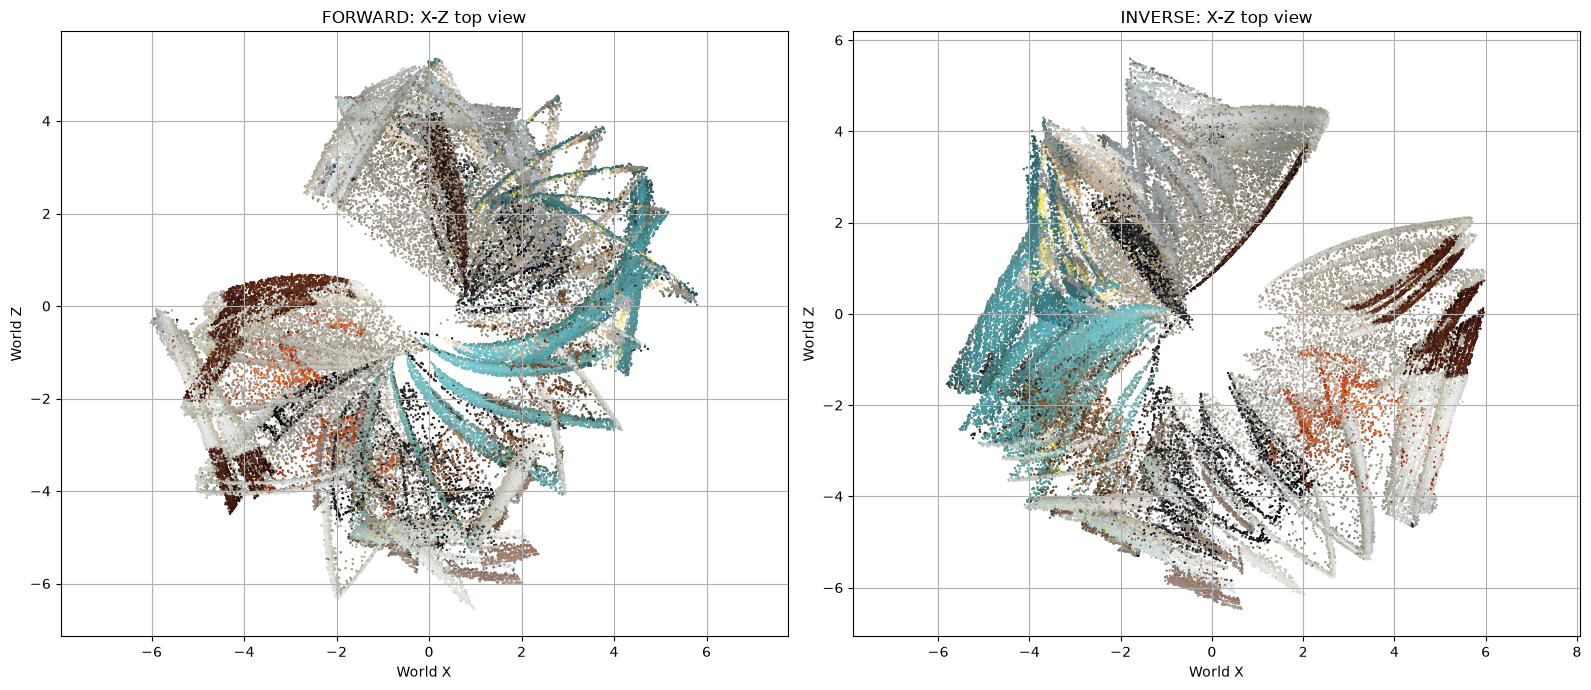

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d

forward = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_forward_002.ply"
)

inverse = o3d.io.read_point_cloud(
    "D:/VLM-maps/outputs/test_inverse_002.ply"
)

pf = np.asarray(forward.points)
cf = np.asarray(forward.colors)

pi = np.asarray(inverse.points)
ci = np.asarray(inverse.colors)

# Randomly sample for faster plotting
N = 100000

rf = np.random.choice(len(pf), min(N, len(pf)), replace=False)
ri = np.random.choice(len(pi), min(N, len(pi)), replace=False)

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

# --------------------------------------------------
# FORWARD
# --------------------------------------------------

axes[0].scatter(
    pf[rf, 0],
    pf[rf, 2],
    c=cf[rf],
    s=0.5
)

axes[0].set_title("FORWARD: X-Z top view")
axes[0].set_xlabel("World X")
axes[0].set_ylabel("World Z")
axes[0].axis("equal")
axes[0].grid(True)

# --------------------------------------------------
# INVERSE
# --------------------------------------------------

axes[1].scatter(
    pi[ri, 0],
    pi[ri, 2],
    c=ci[ri],
    s=0.5
)

axes[1].set_title("INVERSE: X-Z top view")
axes[1].set_xlabel("World X")
axes[1].set_ylabel("World Z")
axes[1].axis("equal")
axes[1].grid(True)

plt.tight_layout()
plt.show()


In [31]:
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

print("Files around dataset:")
for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, "").count(os.sep)

    if level > 2:
        continue

    print("\n", root)

    for f in files[:30]:
        print("  ", f)


Files around dataset:

 D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene
   poses.txt

 D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene\depth
   000000.npy
   000001.npy
   000002.npy
   000003.npy
   000004.npy
   000005.npy
   000006.npy
   000007.npy
   000008.npy
   000009.npy
   000010.npy
   000011.npy
   000012.npy
   000013.npy
   000014.npy
   000015.npy
   000016.npy
   000017.npy
   000018.npy
   000019.npy
   000020.npy
   000021.npy
   000022.npy
   000023.npy
   000024.npy
   000025.npy
   000026.npy
   000027.npy
   000028.npy
   000029.npy

 D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene\rgb
   000000.png
   000001.png
   000002.png
   000003.png
   000004.png
   000005.png
   000006.png
   000007.png
   000008.png
   000009.png
   000010.png
   000011.png
   000012.png
   000013.png
   000014.png
   000015.png
   000016.png
   000017.png
   000018.png
   000019.png
   000020.png
   000021.png
   000022.png
   000023.png
   000024.png
  

In [32]:
import os

ROOT = "D:/VLM-maps/dataset/content"

print("=" * 70)
print("SEARCHING DATASET FILES")
print("=" * 70)

keywords = [
    "depth",
    "depth_scale",
    "depthscale",
    "pose",
    "intrinsic",
    "camera",
    "custom_scene"
]

for root, dirs, files in os.walk(ROOT):

    # Don't dump huge numbers of image/depth files
    useful_files = [
        f for f in files
        if not f.lower().endswith((
            ".png", ".jpg", ".jpeg", ".npy", ".ply"
        ))
    ]

    for f in useful_files:
        path = os.path.join(root, f)

        print(path)


SEARCHING DATASET FILES
D:/VLM-maps/dataset/content\vlmaps_dataset\my_custom_scene\poses.txt


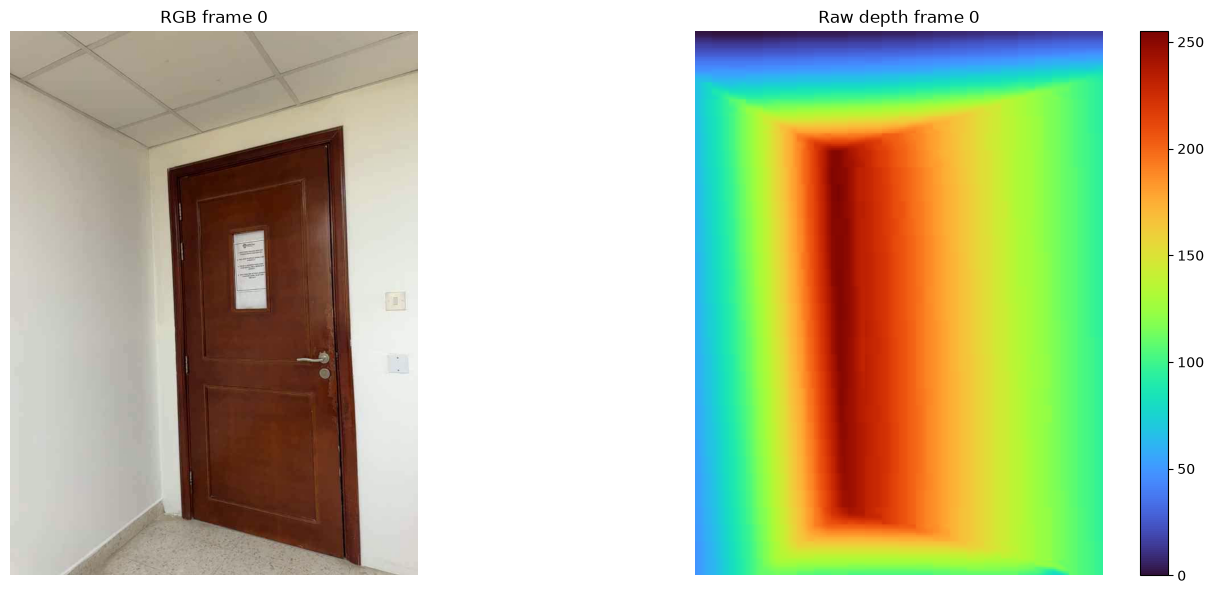

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

idx = 0

rgb = np.asarray(
    Image.open(
        f"{BASE}/rgb/{idx:06d}.png"
    ).convert("RGB")
)

depth = np.load(
    f"{BASE}/depth/{idx:06d}.npy"
).astype(np.float32)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))

ax[0].imshow(rgb)
ax[0].set_title("RGB frame 0")
ax[0].axis("off")

im = ax[1].imshow(
    depth,
    cmap="turbo",
    vmin=0,
    vmax=255
)

ax[1].set_title("Raw depth frame 0")
ax[1].axis("off")

plt.colorbar(im, ax=ax[1], fraction=0.046)

plt.tight_layout()
plt.show()


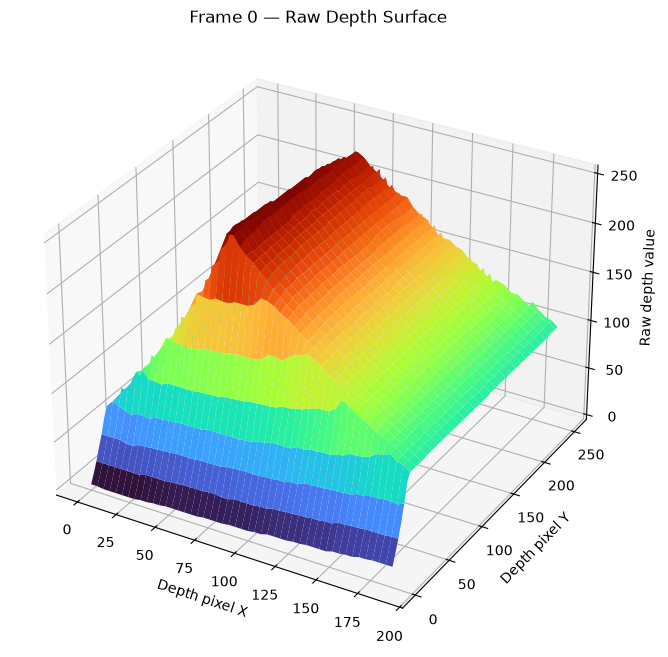

In [34]:
import numpy as np
import matplotlib.pyplot as plt

depth = np.load(
    "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/depth/000000.npy"
).astype(np.float32)

# Show depth as a 3D surface
h, w = depth.shape

u = np.arange(w)
v = np.arange(h)

U, V = np.meshgrid(u, v)

fig = plt.figure(figsize=(12, 8))

ax = fig.add_subplot(111, projection="3d")

# Downsample just for visualization
step = 4

ax.plot_surface(
    U[::step, ::step],
    V[::step, ::step],
    depth[::step, ::step],
    cmap="turbo",
    linewidth=0
)

ax.set_xlabel("Depth pixel X")
ax.set_ylabel("Depth pixel Y")
ax.set_zlabel("Raw depth value")

ax.set_title("Frame 0 — Raw Depth Surface")

plt.show()


In [35]:
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset"

print("Searching for files that might describe depth / camera parameters...\n")

keywords = [
    "depth",
    "camera",
    "intrinsic",
    "intrinsics",
    "pose",
    "calib",
    "metadata",
    "config",
    "readme",
    "json",
    "yaml",
    "yml",
]

for root, dirs, files in os.walk(BASE):
    for f in files:
        name = f.lower()

        # Skip the thousands of RGB/depth frames
        if name.endswith((".png", ".npy")):
            continue

        if any(k in name for k in keywords):
            print(os.path.join(root, f))


Searching for files that might describe depth / camera parameters...

D:/VLM-maps/dataset/content/vlmaps_dataset\my_custom_scene\poses.txt


In [36]:
import numpy as np
import os

DEPTH_DIR = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/depth"

d = np.load(
    os.path.join(DEPTH_DIR, "000000.npy")
).astype(np.float32)

print("shape:", d.shape)
print("dtype:", d.dtype)

print("\nRaw statistics:")
print("min:", d.min())
print("max:", d.max())
print("mean:", d.mean())
print("median:", np.median(d))

print("\nUnique-value information:")
u = np.unique(d)

print("number of unique values:", len(u))
print("first 50:", u[:50])

# Check whether values are essentially integers
fraction_integer = np.mean(np.isclose(d, np.round(d)))

print("\nFraction exactly integer-valued:", fraction_integer)

# Check common normalizations
print("\nPossible interpretations of median depth:")
median = np.median(d)

print("raw:", median)
print("raw / 255:", median / 255)
print("raw / 100:", median / 100)
print("raw / 1000:", median / 1000)


shape: (256, 192)
dtype: float32

Raw statistics:
min: 0.0
max: 255.0
mean: 139.24774
median: 135.0

Unique-value information:
number of unique values: 220
first 50: [ 0.  1.  2.  3.  4.  5.  6.  8.  9. 10. 11. 12. 13. 15. 16. 17. 18. 19.
 20. 22. 23. 24. 25. 26. 27. 29. 30. 31. 32. 33. 34. 36. 37. 38. 39. 40.
 41. 43. 44. 45. 46. 47. 48. 50. 51. 52. 53. 54. 55. 57.]

Fraction exactly integer-valued: 1.0

Possible interpretations of median depth:
raw: 135.0
raw / 255: 0.5294118
raw / 100: 1.35
raw / 1000: 0.135


In [37]:
import os

ROOT = "D:/VLM-maps/dataset"

print("=" * 70)
print("ALL NON-IMAGE/NON-DEPTH FILES")
print("=" * 70)

for root, dirs, files in os.walk(ROOT):
    for f in files:
        if not f.lower().endswith((".png", ".npy", ".jpg", ".jpeg", ".ply")):
            print(os.path.join(root, f))


ALL NON-IMAGE/NON-DEPTH FILES
D:/VLM-maps/dataset\content\vlmaps_dataset\my_custom_scene\poses.txt


In [38]:
import os

ROOT = "D:/VLM-maps/dataset"

print("=" * 70)
print("DIRECTORY STRUCTURE")
print("=" * 70)

for root, dirs, files in os.walk(ROOT):

    level = root.replace(ROOT, "").count(os.sep)

    if level > 4:
        continue

    indent = "  " * level
    print(indent + os.path.basename(root) + "/")

    for f in files[:20]:
        print(indent + "  " + f)

    if len(files) > 20:
        print(indent + f"  ... ({len(files)} files)")


DIRECTORY STRUCTURE
dataset/
  content/
    vlmaps_dataset/
      my_custom_scene/
        poses.txt
        depth/
          000000.npy
          000001.npy
          000002.npy
          000003.npy
          000004.npy
          000005.npy
          000006.npy
          000007.npy
          000008.npy
          000009.npy
          000010.npy
          000011.npy
          000012.npy
          000013.npy
          000014.npy
          000015.npy
          000016.npy
          000017.npy
          000018.npy
          000019.npy
          ... (2091 files)
        rgb/
          000000.png
          000001.png
          000002.png
          000003.png
          000004.png
          000005.png
          000006.png
          000007.png
          000008.png
          000009.png
          000010.png
          000011.png
          000012.png
          000013.png
          000014.png
          000015.png
          000016.png
          000017.png
          000018.png
          000019.png
    

In [39]:
import numpy as np
import os

DEPTH_DIR = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/depth"

pairs = [
    (0, 72),
    (72, 144),
    (144, 216),
    (500, 572),
    (1000, 1072),
    (1500, 1572),
    (2000, 2072),
]

print("=" * 70)
print("DEPTH vs INVERSE-DEPTH FRAME CONSISTENCY")
print("=" * 70)

for a, b in pairs:

    da = np.load(
        os.path.join(DEPTH_DIR, f"{a:06d}.npy")
    ).astype(np.float32)

    db = np.load(
        os.path.join(DEPTH_DIR, f"{b:06d}.npy")
    ).astype(np.float32)

    valid = (
        np.isfinite(da) &
        np.isfinite(db) &
        (da > 0) &
        (db > 0)
    )

    x = da[valid]
    y = db[valid]

    # Raw depth correlation
    raw_corr = np.corrcoef(x, y)[0, 1]

    # Inverse depth correlation
    inv_x = 1.0 / x
    inv_y = 1.0 / y

    inv_corr = np.corrcoef(inv_x, inv_y)[0, 1]

    print(
        f"{a:04d} -> {b:04d} | "
        f"raw corr = {raw_corr:.4f} | "
        f"inverse corr = {inv_corr:.4f}"
    )


DEPTH vs INVERSE-DEPTH FRAME CONSISTENCY
0000 -> 0072 | raw corr = 0.9256 | inverse corr = 0.8963
0072 -> 0144 | raw corr = 0.9404 | inverse corr = 0.9640
0144 -> 0216 | raw corr = 0.8090 | inverse corr = 0.6971
0500 -> 0572 | raw corr = 0.7658 | inverse corr = 0.4769
1000 -> 1072 | raw corr = 0.8258 | inverse corr = 0.3132
1500 -> 1572 | raw corr = 0.7784 | inverse corr = 0.1164
2000 -> 2072 | raw corr = 0.9512 | inverse corr = 0.9084


In [40]:
import numpy as np
import os

DEPTH_DIR = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/depth"

frames = [0, 72, 144, 216, 500, 1000, 1500, 2000, 2090]

print("=" * 75)
print("DEPTH VALUE DISTRIBUTION BY FRAME")
print("=" * 75)

for idx in frames:

    d = np.load(
        os.path.join(DEPTH_DIR, f"{idx:06d}.npy")
    ).astype(np.float32)

    valid = d[np.isfinite(d) & (d > 0)]

    p = np.percentile(
        valid,
        [1, 5, 10, 25, 50, 75, 90, 95, 99]
    )

    print(f"\nFrame {idx:04d}")
    print(
        "P01  P05  P10  P25  P50  P75  P90  P95  P99"
    )
    print(
        " ".join(f"{x:6.1f}" for x in p)
    )


DEPTH VALUE DISTRIBUTION BY FRAME

Frame 0000
P01  P05  P10  P25  P50  P75  P90  P95  P99
  11.0   40.0   65.0  102.0  135.0  182.0  222.0  235.0  250.0

Frame 0072
P01  P05  P10  P25  P50  P75  P90  P95  P99
  15.0   31.0   45.0   83.0  121.0  173.0  216.0  232.0  249.0

Frame 0144
P01  P05  P10  P25  P50  P75  P90  P95  P99
  16.0   46.0   59.0   94.0  129.0  175.0  214.0  227.8  244.0

Frame 0216
P01  P05  P10  P25  P50  P75  P90  P95  P99
  16.0   38.0   53.0  101.0  154.0  193.0  222.0  232.0  245.0

Frame 0500
P01  P05  P10  P25  P50  P75  P90  P95  P99
   9.0   18.0   29.0   67.0  125.0  167.0  211.0  229.0  245.0

Frame 1000
P01  P05  P10  P25  P50  P75  P90  P95  P99
  17.5   51.0   61.0   95.0  150.0  181.0  206.0  220.0  238.0

Frame 1500
P01  P05  P10  P25  P50  P75  P90  P95  P99
   8.0   33.0   55.0  102.0  132.0  172.0  208.0  224.0  242.0

Frame 2000
P01  P05  P10  P25  P50  P75  P90  P95  P99
  20.0   45.0   68.0  122.0  182.0  211.0  231.0  238.0  248.0

Frame 2090
P0

In [41]:
# Check whether depth values behave like an 8-bit normalized quantity

d = np.load(
    os.path.join(DEPTH_DIR, "000000.npy")
).astype(np.float32)

valid = d[np.isfinite(d) & (d > 0)]

print("Number of valid:", len(valid))

for divisor in [255, 254, 256]:
    normalized = valid / divisor

    print(
        f"\nDivisor {divisor}:"
        f"\n  min    = {normalized.min():.4f}"
        f"\n  median = {np.median(normalized):.4f}"
        f"\n  max    = {normalized.max():.4f}"
    )


Number of valid: 49128

Divisor 255:
  min    = 0.0039
  median = 0.5294
  max    = 1.0000

Divisor 254:
  min    = 0.0039
  median = 0.5315
  max    = 1.0039

Divisor 256:
  min    = 0.0039
  median = 0.5273
  max    = 0.9961


In [42]:
from PIL import Image
import os
import numpy as np

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

for idx in [0, 500, 1000, 1500, 2090]:

    rgb_path = os.path.join(BASE, "rgb", f"{idx:06d}.png")
    depth_path = os.path.join(BASE, "depth", f"{idx:06d}.npy")

    img = Image.open(rgb_path)
    depth = np.load(depth_path)

    print("=" * 60)
    print("FRAME", idx)

    print("RGB:")
    print("  size:", img.size)
    print("  mode:", img.mode)
    print("  format:", img.format)

    print("Depth:")
    print("  shape:", depth.shape)
    print("  dtype:", depth.dtype)

    # PNG metadata
    print("RGB metadata:")
    print(img.info)


FRAME 0
RGB:
  size: (720, 960)
  mode: RGB
  format: PNG
Depth:
  shape: (256, 192)
  dtype: float32
RGB metadata:
{}
FRAME 500
RGB:
  size: (720, 960)
  mode: RGB
  format: PNG
Depth:
  shape: (256, 192)
  dtype: float32
RGB metadata:
{}
FRAME 1000
RGB:
  size: (720, 960)
  mode: RGB
  format: PNG
Depth:
  shape: (256, 192)
  dtype: float32
RGB metadata:
{}
FRAME 1500
RGB:
  size: (720, 960)
  mode: RGB
  format: PNG
Depth:
  shape: (256, 192)
  dtype: float32
RGB metadata:
{}
FRAME 2090
RGB:
  size: (720, 960)
  mode: RGB
  format: PNG
Depth:
  shape: (256, 192)
  dtype: float32
RGB metadata:
{}


In [43]:
import numpy as np

poses = np.loadtxt(
    "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/poses.txt"
)

print("=" * 60)
print("POSE TRAJECTORY")

print("First 5 poses:")
print(poses[:5])

print("\nLast 5 poses:")
print(poses[-5:])

print("\nTranslation:")
print("min:", poses[:, :3].min(axis=0))
print("max:", poses[:, :3].max(axis=0))

# Rotation determinant
from scipy.spatial.transform import Rotation

rots = Rotation.from_quat(
    poses[:, 3:7]
)

R = rots.as_matrix()

print("\nRotation determinant:")
print("min:", np.linalg.det(R).min())
print("max:", np.linalg.det(R).max())

print("\nRotation matrix frame 0:")
print(R[0])


POSE TRAJECTORY
First 5 poses:
[[ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
   0.77898699]
 [ 0.05925108  0.12547487 -0.89158452  0.01210961 -0.62662059 -0.01603638
   0.77906531]
 [ 0.05970709  0.12528354 -0.89262092  0.0115514  -0.62671965 -0.01534706
   0.77900809]
 [ 0.05965707  0.12457903 -0.89288676  0.01127639 -0.62677807 -0.01498674
   0.77897215]
 [ 0.0598232   0.12417594 -0.8932665   0.01089376 -0.62653327 -0.01492854
   0.77917546]]

Last 5 poses:
[[ 0.83745271  0.13912851  0.09561505  0.01638321 -0.24389659 -0.08289555
   0.96611309]
 [ 0.83748835  0.13902174  0.09573393  0.0162878  -0.24523738 -0.08246917
   0.96581173]
 [ 0.83728111  0.13930392  0.09488004  0.01606539 -0.24618082 -0.08236428
   0.96558422]
 [ 0.83719671  0.13922584  0.09476586  0.0160397  -0.24675238 -0.08198309
   0.96547127]
 [ 0.83689678  0.13889173  0.09456147  0.01609126 -0.24859226 -0.08068334
   0.9651078 ]]

Translation:
min: [-1.02564287  0.11377442 -1.35338497]
max: 

In [44]:
import numpy as np
from scipy.spatial.transform import Rotation

poses = np.loadtxt(
    "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene/poses.txt"
)

R = Rotation.from_quat(poses[:, 3:7]).as_matrix()
t = poses[:, :3]

# Camera optical axis = +Z in our current convention
forward = R[:, :, 2]

print("=" * 70)
print("POSE DIRECTION vs MOVEMENT")
print("=" * 70)

for a, b in [(0,72), (72,144), (144,216), (500,572),
             (1000,1072), (1500,1572), (2000,2072)]:

    movement = t[b] - t[a]
    movement_norm = np.linalg.norm(movement)

    # Average camera forward direction between the two frames
    f = forward[a] + forward[b]
    f /= np.linalg.norm(f)

    cosine = np.dot(
        movement / movement_norm,
        f
    )

    print(
        f"{a:04d}->{b:04d} | "
        f"movement={movement_norm:.4f} | "
        f"forward·movement={cosine:.4f}"
    )


POSE DIRECTION vs MOVEMENT
0000->0072 | movement=0.0356 | forward·movement=-0.6118
0072->0144 | movement=0.1352 | forward·movement=0.9151
0144->0216 | movement=0.3797 | forward·movement=0.9879
0500->0572 | movement=0.1746 | forward·movement=0.9120
1000->1072 | movement=0.0965 | forward·movement=0.7923
1500->1572 | movement=0.0754 | forward·movement=0.4177
2000->2072 | movement=0.0581 | forward·movement=0.2840


In [45]:
import os
import numpy as np
from PIL import Image

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

rgb_dir = os.path.join(BASE, "rgb")
depth_dir = os.path.join(BASE, "depth")

# ------------------------------------------------------------
# Check RGB/depth dimensions
# ------------------------------------------------------------

for idx in [0, 72, 500, 1000, 2090]:

    rgb_path = os.path.join(rgb_dir, f"{idx:06d}.png")
    depth_path = os.path.join(depth_dir, f"{idx:06d}.npy")

    rgb = np.array(Image.open(rgb_path))
    depth = np.load(depth_path)

    print(f"\nFrame {idx}")
    print("RGB:")
    print("  shape:", rgb.shape)
    print("  dtype:", rgb.dtype)

    print("Depth:")
    print("  shape:", depth.shape)
    print("  dtype:", depth.dtype)

# ------------------------------------------------------------
# Check RGB channel statistics
# ------------------------------------------------------------

rgb = np.array(
    Image.open(
        os.path.join(rgb_dir, "000000.png")
    )
)

print("\n" + "="*60)
print("RGB FRAME 0")
print("="*60)

print("shape:", rgb.shape)
print("min:", rgb.min())
print("max:", rgb.max())
print("mean:", rgb.mean())

# ------------------------------------------------------------
# Check whether depth is related to RGB image dimensions
# ------------------------------------------------------------

depth = np.load(
    os.path.join(depth_dir, "000000.npy")
)

print("\n" + "="*60)
print("DEPTH FRAME 0")
print("="*60)

print("shape:", depth.shape)
print("min:", depth.min())
print("max:", depth.max())

# ------------------------------------------------------------
# Look for common camera/intrinsics files elsewhere
# ------------------------------------------------------------

print("\n" + "="*60)
print("SEARCHING FOR INTRINSICS / CAMERA FILES")
print("="*60)

root = "D:/VLM-maps/dataset"

keywords = [
    "intrinsic",
    "intrinsics",
    "camera",
    "calib",
    "calibration",
    "config",
    "metadata"
]

matches = []

for dirpath, dirs, files in os.walk(root):

    for f in files:

        name = f.lower()

        if any(k in name for k in keywords):

            matches.append(
                os.path.join(dirpath, f)
            )

print("Found:", len(matches))

for x in matches[:100]:
    print(x)



Frame 0
RGB:
  shape: (960, 720, 3)
  dtype: uint8
Depth:
  shape: (256, 192)
  dtype: float32



Frame 72
RGB:
  shape: (960, 720, 3)
  dtype: uint8
Depth:
  shape: (256, 192)
  dtype: float32

Frame 500
RGB:
  shape: (960, 720, 3)
  dtype: uint8
Depth:
  shape: (256, 192)
  dtype: float32

Frame 1000
RGB:
  shape: (960, 720, 3)
  dtype: uint8
Depth:
  shape: (256, 192)
  dtype: float32

Frame 2090
RGB:
  shape: (960, 720, 3)
  dtype: uint8
Depth:
  shape: (256, 192)
  dtype: float32

RGB FRAME 0
shape: (960, 720, 3)
min: 0
max: 255
mean: 143.4656148726852

DEPTH FRAME 0
shape: (256, 192)
min: 0.0
max: 255.0

SEARCHING FOR INTRINSICS / CAMERA FILES
Found: 0


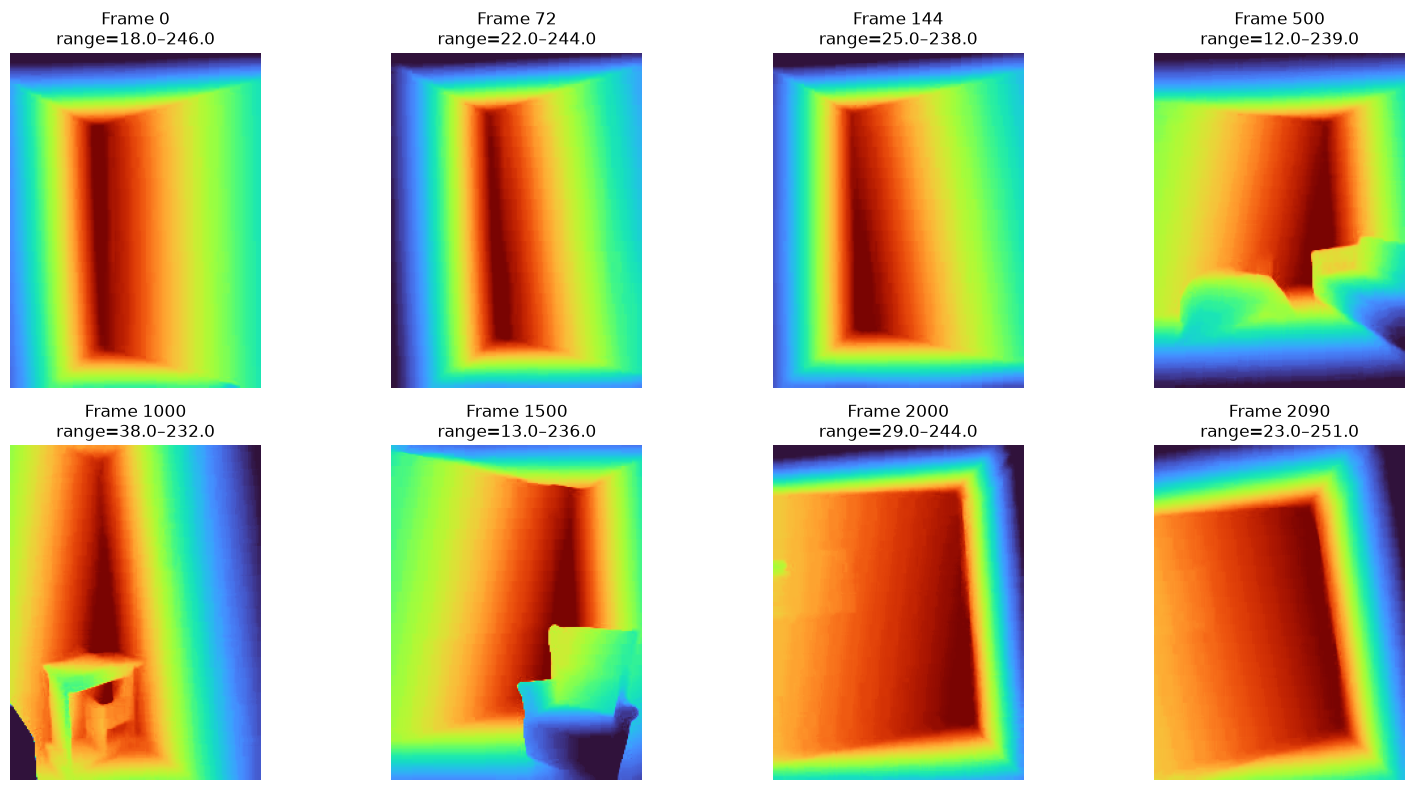

In [46]:
import numpy as np
import os
import matplotlib.pyplot as plt

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")

indices = [0, 72, 144, 500, 1000, 1500, 2000, 2090]

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8)
)

for ax, idx in zip(axes.flat, indices):

    depth = np.load(
        os.path.join(
            DEPTH_DIR,
            f"{idx:06d}.npy"
        )
    ).astype(np.float32)

    # Ignore zero
    valid = depth > 0

    # Percentile normalization instead of assuming metric units
    lo = np.percentile(depth[valid], 2)
    hi = np.percentile(depth[valid], 98)

    display = np.clip(
        (depth - lo) / (hi - lo),
        0,
        1
    )

    display[~valid] = 0

    ax.imshow(
        display,
        cmap="turbo"
    )

    ax.set_title(
        f"Frame {idx}\n"
        f"range={lo:.1f}–{hi:.1f}"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()


In [47]:
import numpy as np
import os

BASE = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
DEPTH_DIR = os.path.join(BASE, "depth")

for idx in [0, 500, 1000, 1500, 2090]:

    d = np.load(
        os.path.join(
            DEPTH_DIR,
            f"{idx:06d}.npy"
        )
    ).astype(np.float32)

    valid = d > 0

    print(f"\nFrame {idx}")

    print("Center:",
          d[d.shape[0]//2-10:d.shape[0]//2+10,
            d.shape[1]//2-10:d.shape[1]//2+10].mean())

    print("Top:",
          d[:30][d[:30] > 0].mean())

    print("Bottom:",
          d[-30:][d[-30:] > 0].mean())

    print("Left:",
          d[:, :30][d[:, :30] > 0].mean())

    print("Right:",
          d[:, -30:][d[:, -30:] > 0].mean())



Frame 0
Center: 209.795
Top: 49.60164
Bottom: 132.23941
Left: 82.24811
Right: 103.004166

Frame 500
Center: 210.7275
Top: 42.76684
Bottom: 31.642708
Left: 105.19701
Right: 86.85716

Frame 1000
Center: 187.865
Top: 131.10226
Bottom: 125.17205
Left: 143.65195
Right: 60.752995

Frame 1500
Center: 198.8325
Top: 99.66511
Bottom: 58.831814
Left: 114.90404
Right: 96.5038

Frame 2090
Center: 233.5825
Top: 65.40872
Bottom: 163.292
Left: 163.744
Right: 68.743256


RGB frames: 2091
Depth frames: 2091
Pose shape: (2091, 7)
First pose: [ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
  0.77898699]
Last pose: [ 0.83689678  0.13889173  0.09456147  0.01609126 -0.24859226 -0.08068334
  0.9651078 ]

Image sizes:
RGB: (960, 720)
Depth: (256, 192)

Provisional depth intrinsics:
fx, fy, cx, cy = 200.0 200.0 96.0 127.712

Raw depth percentiles:
[ 12.  31.  94. 146. 193. 231. 245.]

Depth-unit decision:
The notebook shows raw depth values from approximately 0 to 255.
The default below interprets them as normalized 8-bit-like depth and
maps 255 units to 5 metres.

This is only a provisional conversion. If you know the real sensor
scale, replace DEPTH_MAX_RAW and ROOM_MAX_METERS below.

Using provisional depth scale:
raw depth / 51.0 = metres

Frames selected: 210
Frame range: 0 to 2090
Processed frame 0000 | points: 48,840 | camera: [ 0.05893505  0.12546577 -0.89114189]


Processed frame 0200 | points: 48,971 | camera: [-0.35580382  0.15011652 -0.94076014]


Processed frame 0400 | points: 48,796 | camera: [-0.66846758  0.15119903 -0.97816992]


Processed frame 0600 | points: 48,848 | camera: [-0.89080703  0.14973596 -1.35309875]


Processed frame 0800 | points: 49,013 | camera: [-0.96077818  0.14324503 -0.89944601]


...

World range: [11.85876102  5.34349525 11.93431972]



After robust spatial filtering:
Points: 9,976,065


Min: [-5.26271717 -1.48856194 -5.6741181 ]


Max: [4.88806401 2.55745049 4.73172951]



Final point cloud:
Points: 5,441,387
Saved: D:/VLM-maps/outputs/reconstruction_outputs\fused_world_pointcloud_2cm.ply


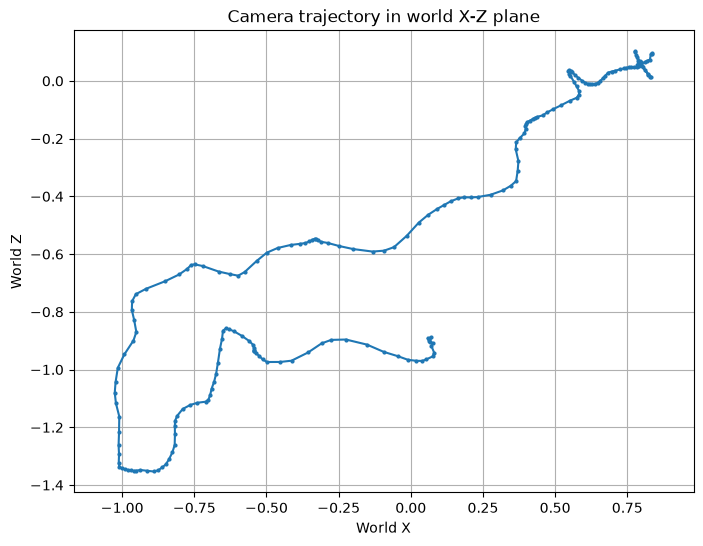

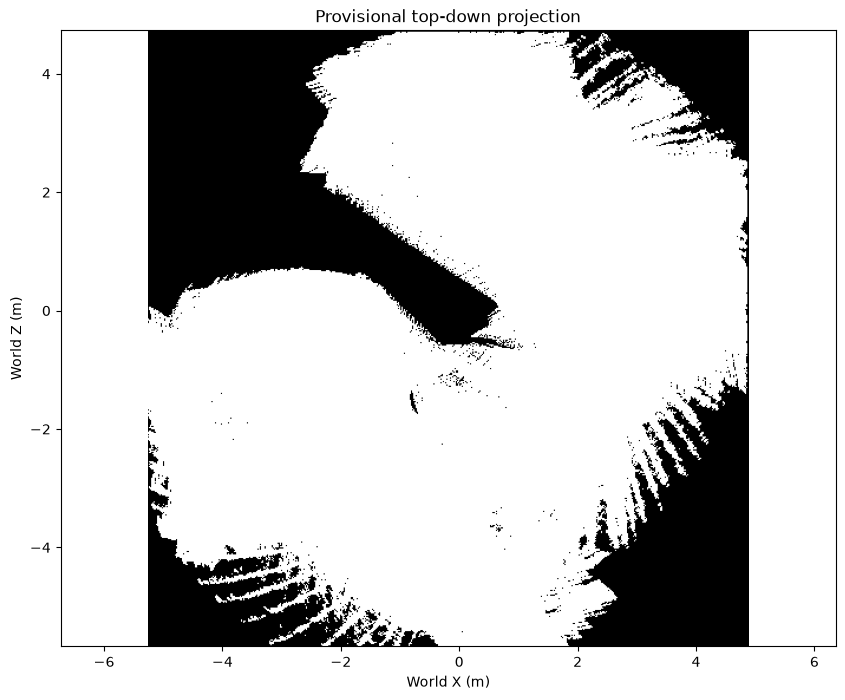

Top-down image saved: D:/VLM-maps/outputs/reconstruction_outputs\provisional_topdown.png
Metadata saved: D:/VLM-maps/outputs/reconstruction_outputs\reconstruction_metadata.json


In [2]:
# ============================================================
# COMPLETE RGB-D POINT-CLOUD FUSION + TOP-DOWN MAP
# ============================================================

import os
import json
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from PIL import Image
from scipy.spatial.transform import Rotation


# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

OUTPUT_DIR = "D:/VLM-maps/outputs/reconstruction_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Load and sort files
# ------------------------------------------------------------

def numeric_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    digits = "".join(ch for ch in stem if ch.isdigit())
    return int(digits) if digits else -1


rgb_files = sorted(
    [
        os.path.join(RGB_DIR, f)
        for f in os.listdir(RGB_DIR)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ],
    key=numeric_stem
)

depth_files = sorted(
    [
        os.path.join(DEPTH_DIR, f)
        for f in os.listdir(DEPTH_DIR)
        if f.lower().endswith(".npy")
    ],
    key=numeric_stem
)

poses = np.loadtxt(POSES_FILE, dtype=np.float64)

assert len(rgb_files) == len(depth_files), (
    f"RGB/depth count mismatch: {len(rgb_files)} vs {len(depth_files)}"
)

assert poses.ndim == 2 and poses.shape[1] == 7, (
    f"Expected poses with shape (N, 7), received {poses.shape}"
)

assert len(poses) == len(rgb_files), (
    f"Pose/frame mismatch: {len(poses)} poses vs {len(rgb_files)} frames"
)

print("RGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))
print("Pose shape:", poses.shape)
print("First pose:", poses[0])
print("Last pose:", poses[-1])


# ------------------------------------------------------------
# 3. Camera parameters
# ------------------------------------------------------------

# These are the values currently present in your notebook.
# They are treated as provisional RGB calibration values.
FX_RGB = 750.0
FY_RGB = 750.0
CX_RGB = 360.0
CY_RGB = 478.92

# Your depth arrays are 256 x 192, according to the notebook.
sample_depth = np.load(depth_files[0])
DEPTH_H, DEPTH_W = sample_depth.shape

sample_rgb = np.asarray(Image.open(rgb_files[0]))
RGB_H, RGB_W = sample_rgb.shape[:2]

# Provisional scaled intrinsics.
# These are valid only if the supplied calibration corresponds to
# the full RGB image and the depth projection has the same geometry.
FX = FX_RGB * DEPTH_W / RGB_W
FY = FY_RGB * DEPTH_H / RGB_H
CX = CX_RGB * DEPTH_W / RGB_W
CY = CY_RGB * DEPTH_H / RGB_H

print("\nImage sizes:")
print("RGB:", (RGB_H, RGB_W))
print("Depth:", (DEPTH_H, DEPTH_W))

print("\nProvisional depth intrinsics:")
print("fx, fy, cx, cy =", FX, FY, CX, CY)


# ------------------------------------------------------------
# 4. Depth-unit diagnostics
# ------------------------------------------------------------

raw_depth_values = []

for path in depth_files[::max(1, len(depth_files) // 30)]:
    d = np.asarray(np.load(path), dtype=np.float32)
    finite = d[np.isfinite(d) & (d > 0)]
    if finite.size:
        raw_depth_values.append(finite)

raw_depth_values = np.concatenate(raw_depth_values)

depth_percentiles = np.percentile(
    raw_depth_values,
    [1, 5, 25, 50, 75, 95, 99]
)

print("\nRaw depth percentiles:")
print(depth_percentiles)

print(
    """
Depth-unit decision:
The notebook shows raw depth values from approximately 0 to 255.
The default below interprets them as normalized 8-bit-like depth and
maps 255 units to 5 metres.

This is only a provisional conversion. If you know the real sensor
scale, replace DEPTH_MAX_RAW and ROOM_MAX_METERS below.
"""
)

DEPTH_MAX_RAW = 255.0
ROOM_MAX_METERS = 5.0

DEPTH_SCALE = DEPTH_MAX_RAW / ROOM_MAX_METERS

print("Using provisional depth scale:")
print("raw depth /", DEPTH_SCALE, "= metres")


# ------------------------------------------------------------
# 5. Pose conversion
# ------------------------------------------------------------

def pose_to_matrix_camera_to_world(pose_row):
    """
    Expected pose format:
        tx ty tz qx qy qz qw

    Assumption:
        quaternion gives camera orientation in world coordinates,
        therefore R maps camera-frame points to world-frame points.
    """
    tx, ty, tz, qx, qy, qz, qw = pose_row

    quaternion = np.array([qx, qy, qz, qw], dtype=np.float64)
    R_camera_to_world = Rotation.from_quat(quaternion).as_matrix()

    T_camera_to_world = np.eye(4, dtype=np.float64)
    T_camera_to_world[:3, :3] = R_camera_to_world
    T_camera_to_world[:3, 3] = [tx, ty, tz]

    return T_camera_to_world


def transform_points(points_camera, T_camera_to_world):
    points_h = np.column_stack(
        [
            points_camera,
            np.ones(len(points_camera), dtype=np.float64)
        ]
    )

    points_world_h = (T_camera_to_world @ points_h.T).T
    return points_world_h[:, :3]


# ------------------------------------------------------------
# 6. Back-project depth into camera coordinates
# ------------------------------------------------------------

def depth_to_camera_points(depth_raw):
    depth_raw = np.asarray(depth_raw, dtype=np.float32)

    # Convert provisional raw depth representation to metres.
    depth_m = depth_raw / DEPTH_SCALE

    valid = (
        np.isfinite(depth_m)
        & (depth_m > 0.15)
        & (depth_m < 6.0)
    )

    v, u = np.indices(depth_m.shape)
    z = depth_m[valid]

    x = (u[valid] - CX) * z / FX
    y = (v[valid] - CY) * z / FY

    points_camera = np.column_stack([x, y, z])

    return points_camera, valid, depth_m


# ------------------------------------------------------------
# 7. RGB handling
# ------------------------------------------------------------

def load_colors(rgb_path, valid_mask):
    """
    This resize is only for provisional visualization.
    It is not true RGB-depth registration.
    """
    rgb = np.asarray(Image.open(rgb_path).convert("RGB"))

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR
        )
    )

    colors = rgb_small[valid_mask].astype(np.float32) / 255.0
    return colors


# ------------------------------------------------------------
# 8. Select frames
# ------------------------------------------------------------

# Start with a manageable sequence.
# After diagnostics pass, change this to np.arange(len(rgb_files)).
FRAME_STEP = 10
frame_indices = np.arange(0, len(rgb_files), FRAME_STEP)

print("\nFrames selected:", len(frame_indices))
print("Frame range:", frame_indices[0], "to", frame_indices[-1])


# ------------------------------------------------------------
# 9. Fuse all frames into world coordinates
# ------------------------------------------------------------

all_world_points = []
all_colors = []
camera_centers = []

for count, frame_idx in enumerate(frame_indices):
    depth_raw = np.load(depth_files[frame_idx]).astype(np.float32)

    points_camera, valid_mask, depth_m = depth_to_camera_points(
        depth_raw
    )

    if len(points_camera) == 0:
        print("Skipping frame", frame_idx, "- no valid depth")
        continue

    T_camera_to_world = pose_to_matrix_camera_to_world(
        poses[frame_idx]
    )

    points_world = transform_points(
        points_camera,
        T_camera_to_world
    )

    colors = load_colors(
        rgb_files[frame_idx],
        valid_mask
    )

    all_world_points.append(points_world)
    all_colors.append(colors)

    camera_centers.append(T_camera_to_world[:3, 3])

    if count % 20 == 0:
        print(
            f"Processed frame {frame_idx:04d} | "
            f"points: {len(points_world):,} | "
            f"camera: {T_camera_to_world[:3, 3]}"
        )


if not all_world_points:
    raise RuntimeError("No valid world points were generated.")

all_world_points = np.vstack(all_world_points)
all_colors = np.vstack(all_colors)
camera_centers = np.vstack(camera_centers)

print("\nRaw fused points:", f"{len(all_world_points):,}")
print("World min:", all_world_points.min(axis=0))
print("World max:", all_world_points.max(axis=0))
print("World range:", np.ptp(all_world_points, axis=0))


# ------------------------------------------------------------
# 10. Remove obvious world-coordinate outliers
# ------------------------------------------------------------

finite_world = np.isfinite(all_world_points).all(axis=1)

all_world_points = all_world_points[finite_world]
all_colors = all_colors[finite_world]

# Robust spatial filtering using percentiles.
# This removes extreme pose/depth failures without deleting normal walls.
low = np.percentile(all_world_points, 0.5, axis=0)
high = np.percentile(all_world_points, 99.5, axis=0)

inside = np.all(
    (all_world_points >= low)
    & (all_world_points <= high),
    axis=1
)

all_world_points = all_world_points[inside]
all_colors = all_colors[inside]

print("\nAfter robust spatial filtering:")
print("Points:", f"{len(all_world_points):,}")
print("Min:", all_world_points.min(axis=0))
print("Max:", all_world_points.max(axis=0))


# ------------------------------------------------------------
# 11. Open3D point cloud
# ------------------------------------------------------------

pcd = o3d.geometry.PointCloud()
pcd.points = o3d.utility.Vector3dVector(all_world_points)
pcd.colors = o3d.utility.Vector3dVector(all_colors)

# Statistical outlier removal.
# Reduce this if the room is sparse.
pcd, keep_indices = pcd.remove_statistical_outlier(
    nb_neighbors=20,
    std_ratio=2.0
)

# Indoor reconstruction voxel size: 2 cm.
pcd = pcd.voxel_down_sample(voxel_size=0.02)

pcd_path = os.path.join(
    OUTPUT_DIR,
    "fused_world_pointcloud_2cm.ply"
)

o3d.io.write_point_cloud(pcd_path, pcd)

print("\nFinal point cloud:")
print("Points:", f"{len(pcd.points):,}")
print("Saved:", pcd_path)


# ------------------------------------------------------------
# 12. Save camera trajectory
# ------------------------------------------------------------

trajectory_path = os.path.join(
    OUTPUT_DIR,
    "camera_centers.npy"
)

np.save(trajectory_path, camera_centers)


# ------------------------------------------------------------
# 13. Diagnose pose trajectory
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))
plt.plot(
    camera_centers[:, 0],
    camera_centers[:, 2],
    "-o",
    markersize=2
)
plt.xlabel("World X")
plt.ylabel("World Z")
plt.title("Camera trajectory in world X-Z plane")
plt.axis("equal")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 14. Create provisional top-down projection
# ------------------------------------------------------------

points = np.asarray(pcd.points)

# Assumes world Y is vertical and X-Z is the floor plane.
# If your trajectory plot is incorrect, this axis assumption must be changed.
x = points[:, 0]
z = points[:, 2]

TOPDOWN_RESOLUTION = 0.02  # metres per pixel

xmin, xmax = x.min(), x.max()
zmin, zmax = z.min(), z.max()

width = int(np.ceil((xmax - xmin) / TOPDOWN_RESOLUTION)) + 1
height = int(np.ceil((zmax - zmin) / TOPDOWN_RESOLUTION)) + 1

ix = np.floor(
    (x - xmin) / TOPDOWN_RESOLUTION
).astype(np.int32)

iz = np.floor(
    (z - zmin) / TOPDOWN_RESOLUTION
).astype(np.int32)

valid_grid = (
    (ix >= 0) & (ix < width)
    & (iz >= 0) & (iz < height)
)

ix = ix[valid_grid]
iz = iz[valid_grid]

topdown = np.zeros((height, width), dtype=np.uint8)
topdown[height - 1 - iz, ix] = 255

topdown_path = os.path.join(
    OUTPUT_DIR,
    "provisional_topdown.png"
)

Image.fromarray(topdown).save(topdown_path)

plt.figure(figsize=(10, 8))
plt.imshow(
    topdown,
    cmap="gray",
    origin="upper",
    extent=[xmin, xmax, zmin, zmax]
)
plt.xlabel("World X (m)")
plt.ylabel("World Z (m)")
plt.title("Provisional top-down projection")
plt.axis("equal")
plt.show()

print("Top-down image saved:", topdown_path)


# ------------------------------------------------------------
# 15. Save reconstruction metadata
# ------------------------------------------------------------

metadata = {
    "num_rgb_frames": len(rgb_files),
    "num_depth_frames": len(depth_files),
    "num_poses": len(poses),
    "selected_frames": len(frame_indices),
    "frame_step": int(FRAME_STEP),
    "depth_raw_percentiles": depth_percentiles.tolist(),
    "depth_max_raw": float(DEPTH_MAX_RAW),
    "room_max_meters": float(ROOM_MAX_METERS),
    "depth_scale_raw_units_per_meter": float(DEPTH_SCALE),
    "depth_intrinsics": {
        "fx": float(FX),
        "fy": float(FY),
        "cx": float(CX),
        "cy": float(CY),
    },
    "voxel_size_m": 0.02,
    "topdown_resolution_m": TOPDOWN_RESOLUTION,
    "pose_format": "tx ty tz qx qy qz qw",
    "pose_assumption": "camera-to-world",
    "vertical_axis_assumption": "world Y",
    "topdown_axes": "world X-Z",
    "rgb_depth_alignment": "provisional resize only",
}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "reconstruction_metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Metadata saved:", metadata_path)

In [49]:
# Dependencies installed locally before execution.
pass

In [50]:
# Dependencies installed locally before execution.
pass

In [51]:
import sys
import open3d as o3d

print("Python:", sys.version)
print("Open3D:", o3d.__version__)

Python: 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
Open3D: 0.20.0


In [52]:
import open3d as o3d
import scipy

print("Open3D:", o3d.__version__)
print("SciPy:", scipy.__version__)

Open3D: 0.20.0
SciPy: 1.18.0


In [53]:
import os

DATASET = "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

OUTPUT_DIR = "D:/VLM-maps/outputs/reconstruction_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("DATASET exists:", os.path.exists(DATASET))
print("RGB exists:", os.path.exists(RGB_DIR))
print("DEPTH exists:", os.path.exists(DEPTH_DIR))
print("POSES exists:", os.path.exists(POSES_FILE))

if os.path.exists(DATASET):
    print("Dataset contents:")
    print(os.listdir(DATASET))

DATASET exists: True
RGB exists: True
DEPTH exists: True
POSES exists: True
Dataset contents:
['depth', 'poses.txt', 'rgb']


In [54]:
required_paths = {
    "dataset": DATASET,
    "rgb": RGB_DIR,
    "depth": DEPTH_DIR,
    "poses": POSES_FILE,
}

missing = [
    f"{name}: {path}"
    for name, path in required_paths.items()
    if not os.path.exists(path)
]

if missing:
    raise FileNotFoundError(
        "The following required paths are missing:\n" +
        "\n".join(missing)
    )

Dataset path: D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene
RGB directory: D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene\rgb
Depth directory: D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene\depth
Poses file: D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene\poses.txt

RGB frames: 2091
Depth frames: 2091
Pose shape: (2091, 7)
First pose: [ 0.05893505  0.12546577 -0.89114189  0.01234622 -0.62671208 -0.01608825
  0.77898699]
Last pose: [ 0.83689678  0.13889173  0.09456147  0.01609126 -0.24859226 -0.08068334
  0.9651078 ]

Image sizes:
RGB: (960, 720)
Depth: (256, 192)

Provisional depth intrinsics:
fx: 200.0
fy: 200.0
cx: 96.0
cy: 127.712

Raw depth percentiles:
[ 12.  31.  94. 146. 193. 231. 245.]

Provisional depth conversion:
raw depth / 51.0 = metres

Frames selected: 210
Frame range: 0 to 2090


Processed frame 0000 | points: 48,840 | camera: [ 0.05893505  0.12546577 -0.89114189]


Processed frame 0200 | points: 48,971 | camera: [-0.35580382  0.15011652 -0.94076014]


Processed frame 0400 | points: 48,796 | camera: [-0.66846758  0.15119903 -0.97816992]


Processed frame 0600 | points: 48,848 | camera: [-0.89080703  0.14973596 -1.35309875]


...


Raw fused points:
10,280,513
World minimum:
[-6.04868646 -2.07814321 -6.59972108]
World maximum:
[5.81007456 3.26535204 5.33459864]
World range:
[11.85876102  5.34349525 11.93431972]



After robust spatial filtering:
Points: 9,976,065


Minimum: [-5.26271717 -1.48856194 -5.6741181 ]


Maximum: [4.88806401 2.55745049 4.73172951]



Final point cloud:
Points: 5,441,387
Saved: D:/VLM-maps/outputs/reconstruction_outputs\fused_world_pointcloud_2cm.ply


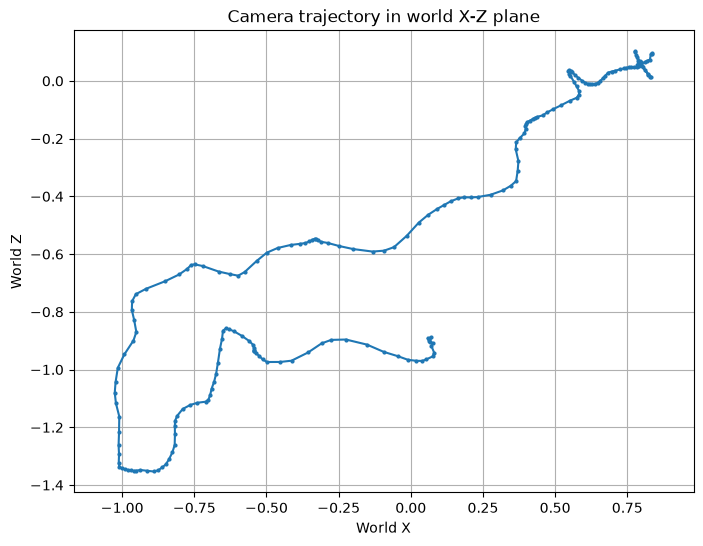

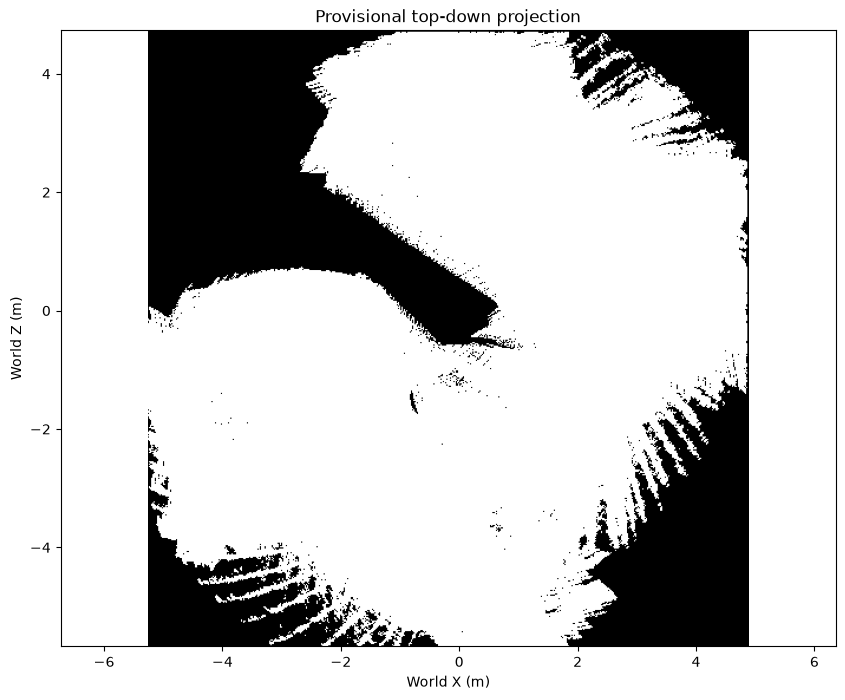

Top-down image saved: D:/VLM-maps/outputs/reconstruction_outputs\provisional_topdown.png
Metadata saved: D:/VLM-maps/outputs/reconstruction_outputs\reconstruction_metadata.json


In [55]:
# ============================================================
# COMPLETE RGB-D POINT-CLOUD FUSION + TOP-DOWN MAP
# ============================================================

import os
import json
import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt

from PIL import Image
from scipy.spatial.transform import Rotation


# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------

DATASET = (
    "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
)

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

OUTPUT_DIR = "D:/VLM-maps/outputs/reconstruction_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. Validate dataset paths
# ------------------------------------------------------------

required_paths = {
    "dataset": DATASET,
    "rgb directory": RGB_DIR,
    "depth directory": DEPTH_DIR,
    "poses file": POSES_FILE,
}

missing_paths = [
    f"{name}: {path}"
    for name, path in required_paths.items()
    if not os.path.exists(path)
]

if missing_paths:
    print("Missing paths:")
    print("\n".join(missing_paths))

    if os.path.exists("D:/VLM-maps/dataset"):
        print("\nAvailable Kaggle input directories:")
        for root, dirs, files in os.walk("D:/VLM-maps/dataset"):
            level = root.replace("D:/VLM-maps/dataset", "").count(os.sep)
            if level <= 4:
                print(root)

    raise FileNotFoundError(
        "Dataset path is incorrect. Check the printed directories above."
    )

print("Dataset path:", DATASET)
print("RGB directory:", RGB_DIR)
print("Depth directory:", DEPTH_DIR)
print("Poses file:", POSES_FILE)


# ------------------------------------------------------------
# 3. Load and numerically sort files
# ------------------------------------------------------------

def numeric_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0]
    digits = "".join(ch for ch in stem if ch.isdigit())
    return int(digits) if digits else -1


rgb_files = sorted(
    [
        os.path.join(RGB_DIR, f)
        for f in os.listdir(RGB_DIR)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ],
    key=numeric_stem,
)

depth_files = sorted(
    [
        os.path.join(DEPTH_DIR, f)
        for f in os.listdir(DEPTH_DIR)
        if f.lower().endswith(".npy")
    ],
    key=numeric_stem,
)

if len(rgb_files) == 0:
    raise RuntimeError(f"No RGB files found in {RGB_DIR}")

if len(depth_files) == 0:
    raise RuntimeError(f"No depth files found in {DEPTH_DIR}")

poses = np.loadtxt(POSES_FILE, dtype=np.float64)

if poses.ndim == 1:
    poses = poses.reshape(1, -1)

assert len(rgb_files) == len(depth_files), (
    f"RGB/depth count mismatch: "
    f"{len(rgb_files)} vs {len(depth_files)}"
)

assert poses.shape[1] == 7, (
    f"Expected poses with shape (N, 7), received {poses.shape}"
)

assert len(poses) == len(rgb_files), (
    f"Pose/frame mismatch: "
    f"{len(poses)} poses vs {len(rgb_files)} frames"
)

print("\nRGB frames:", len(rgb_files))
print("Depth frames:", len(depth_files))
print("Pose shape:", poses.shape)
print("First pose:", poses[0])
print("Last pose:", poses[-1])


# ------------------------------------------------------------
# 4. Camera parameters
# ------------------------------------------------------------

# These values are from the original notebook.
# They remain provisional until the true depth-camera calibration
# is available.
FX_RGB = 750.0
FY_RGB = 750.0
CX_RGB = 360.0
CY_RGB = 478.92

sample_depth = np.asarray(np.load(depth_files[0]))
sample_rgb = np.asarray(Image.open(rgb_files[0]).convert("RGB"))

if sample_depth.ndim != 2:
    raise ValueError(
        f"Expected depth to be 2D, received shape {sample_depth.shape}"
    )

DEPTH_H, DEPTH_W = sample_depth.shape
RGB_H, RGB_W = sample_rgb.shape[:2]

# Provisional scaling from RGB calibration resolution to depth resolution.
FX = FX_RGB * DEPTH_W / RGB_W
FY = FY_RGB * DEPTH_H / RGB_H
CX = CX_RGB * DEPTH_W / RGB_W
CY = CY_RGB * DEPTH_H / RGB_H

print("\nImage sizes:")
print("RGB:", (RGB_H, RGB_W))
print("Depth:", (DEPTH_H, DEPTH_W))

print("\nProvisional depth intrinsics:")
print("fx:", FX)
print("fy:", FY)
print("cx:", CX)
print("cy:", CY)


# ------------------------------------------------------------
# 5. Depth diagnostics and provisional conversion
# ------------------------------------------------------------

raw_depth_values = []

sample_stride = max(1, len(depth_files) // 30)

for path in depth_files[::sample_stride]:
    depth_sample = np.asarray(
        np.load(path),
        dtype=np.float32,
    )

    finite_values = depth_sample[
        np.isfinite(depth_sample) & (depth_sample > 0)
    ]

    if finite_values.size:
        raw_depth_values.append(finite_values)

if not raw_depth_values:
    raise RuntimeError("No positive finite depth values were found.")

raw_depth_values = np.concatenate(raw_depth_values)

depth_percentiles = np.percentile(
    raw_depth_values,
    [1, 5, 25, 50, 75, 95, 99],
)

print("\nRaw depth percentiles:")
print(depth_percentiles)

# IMPORTANT:
# This is provisional because the original depth encoding is not
# documented in the notebook.
#
# The notebook shows raw values approximately in the range 0–255.
# This maps raw depth 255 to 5 metres.
DEPTH_MAX_RAW = 255.0
ROOM_MAX_METERS = 5.0
DEPTH_SCALE = DEPTH_MAX_RAW / ROOM_MAX_METERS

print("\nProvisional depth conversion:")
print("raw depth /", DEPTH_SCALE, "= metres")


# ------------------------------------------------------------
# 6. Pose conversion
# ------------------------------------------------------------

def pose_to_matrix_camera_to_world(pose_row):
    """
    Expected pose format:
        tx ty tz qx qy qz qw

    Assumption:
        The quaternion maps camera-frame orientation to world-frame
        orientation, and the translation is the camera position in
        world coordinates.
    """

    tx, ty, tz, qx, qy, qz, qw = pose_row

    quaternion = np.array(
        [qx, qy, qz, qw],
        dtype=np.float64,
    )

    quaternion_norm = np.linalg.norm(quaternion)

    if quaternion_norm < 1e-12:
        raise ValueError("Encountered a zero-length quaternion.")

    quaternion = quaternion / quaternion_norm

    rotation_camera_to_world = Rotation.from_quat(
        quaternion
    ).as_matrix()

    transform_camera_to_world = np.eye(4, dtype=np.float64)

    transform_camera_to_world[:3, :3] = (
        rotation_camera_to_world
    )

    transform_camera_to_world[:3, 3] = [
        tx,
        ty,
        tz,
    ]

    return transform_camera_to_world


def transform_points(
    points_camera,
    transform_camera_to_world,
):
    points_homogeneous = np.column_stack(
        [
            points_camera,
            np.ones(
                len(points_camera),
                dtype=np.float64,
            ),
        ]
    )

    points_world_homogeneous = (
        transform_camera_to_world
        @ points_homogeneous.T
    ).T

    return points_world_homogeneous[:, :3]


# ------------------------------------------------------------
# 7. Back-project depth into camera coordinates
# ------------------------------------------------------------

def depth_to_camera_points(depth_raw):
    depth_raw = np.asarray(
        depth_raw,
        dtype=np.float32,
    )

    if depth_raw.shape != (DEPTH_H, DEPTH_W):
        raise ValueError(
            f"Unexpected depth shape: {depth_raw.shape}; "
            f"expected {(DEPTH_H, DEPTH_W)}"
        )

    depth_meters = depth_raw / DEPTH_SCALE

    valid = (
        np.isfinite(depth_meters)
        & (depth_meters > 0.15)
        & (depth_meters < 6.0)
    )

    v, u = np.indices(depth_meters.shape)

    z = depth_meters[valid]

    x = (u[valid] - CX) * z / FX
    y = (v[valid] - CY) * z / FY

    points_camera = np.column_stack(
        [
            x,
            y,
            z,
        ]
    )

    return points_camera, valid, depth_meters


# ------------------------------------------------------------
# 8. RGB color loading
# ------------------------------------------------------------

def load_colors(rgb_path, valid_mask):
    """
    This resize is only provisional RGB coloring.
    It is not true RGB-depth calibration or registration.
    """

    rgb = np.asarray(
        Image.open(rgb_path).convert("RGB")
    )

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR,
        )
    )

    colors = (
        rgb_small[valid_mask]
        .astype(np.float32)
        / 255.0
    )

    return colors


# ------------------------------------------------------------
# 9. Select frames
# ------------------------------------------------------------

# Use every 10th frame initially to reduce memory use.
# After the geometry is validated, change to:
# frame_indices = np.arange(len(rgb_files))
FRAME_STEP = 10

frame_indices = np.arange(
    0,
    len(rgb_files),
    FRAME_STEP,
    dtype=np.int32,
)

print("\nFrames selected:", len(frame_indices))
print(
    "Frame range:",
    int(frame_indices[0]),
    "to",
    int(frame_indices[-1]),
)


# ------------------------------------------------------------
# 10. Fuse frames into world coordinates
# ------------------------------------------------------------

all_world_points = []
all_colors = []
camera_centers = []

for count, frame_idx in enumerate(frame_indices):

    depth_raw = np.asarray(
        np.load(depth_files[frame_idx]),
        dtype=np.float32,
    )

    points_camera, valid_mask, depth_meters = (
        depth_to_camera_points(depth_raw)
    )

    if len(points_camera) == 0:
        print(
            "Skipping frame",
            int(frame_idx),
            "- no valid depth",
        )
        continue

    transform_camera_to_world = (
        pose_to_matrix_camera_to_world(
            poses[frame_idx]
        )
    )

    points_world = transform_points(
        points_camera,
        transform_camera_to_world,
    )

    colors = load_colors(
        rgb_files[frame_idx],
        valid_mask,
    )

    all_world_points.append(points_world)
    all_colors.append(colors)

    camera_centers.append(
        transform_camera_to_world[:3, 3]
    )

    if count % 20 == 0:
        print(
            f"Processed frame {frame_idx:04d} | "
            f"points: {len(points_world):,} | "
            f"camera: "
            f"{transform_camera_to_world[:3, 3]}"
        )


if not all_world_points:
    raise RuntimeError(
        "No valid world points were generated."
    )

all_world_points = np.vstack(all_world_points)
all_colors = np.vstack(all_colors)
camera_centers = np.vstack(camera_centers)

print("\nRaw fused points:")
print(f"{len(all_world_points):,}")

print("World minimum:")
print(all_world_points.min(axis=0))

print("World maximum:")
print(all_world_points.max(axis=0))

print("World range:")
print(np.ptp(all_world_points, axis=0))


# ------------------------------------------------------------
# 11. Remove invalid and extreme world-coordinate points
# ------------------------------------------------------------

finite_world = np.isfinite(
    all_world_points
).all(axis=1)

all_world_points = all_world_points[finite_world]
all_colors = all_colors[finite_world]

low = np.percentile(
    all_world_points,
    0.5,
    axis=0,
)

high = np.percentile(
    all_world_points,
    99.5,
    axis=0,
)

inside = np.all(
    (all_world_points >= low)
    & (all_world_points <= high),
    axis=1,
)

all_world_points = all_world_points[inside]
all_colors = all_colors[inside]

print("\nAfter robust spatial filtering:")
print("Points:", f"{len(all_world_points):,}")
print("Minimum:", all_world_points.min(axis=0))
print("Maximum:", all_world_points.max(axis=0))


# ------------------------------------------------------------
# 12. Create and clean Open3D point cloud
# ------------------------------------------------------------

pcd = o3d.geometry.PointCloud()

pcd.points = o3d.utility.Vector3dVector(
    all_world_points
)

pcd.colors = o3d.utility.Vector3dVector(
    all_colors
)

pcd, keep_indices = (
    pcd.remove_statistical_outlier(
        nb_neighbors=20,
        std_ratio=2.0,
    )
)

pcd = pcd.voxel_down_sample(
    voxel_size=0.02
)

pcd_path = os.path.join(
    OUTPUT_DIR,
    "fused_world_pointcloud_2cm.ply",
)

write_success = o3d.io.write_point_cloud(
    pcd_path,
    pcd,
)

if not write_success:
    raise RuntimeError(
        f"Failed to save point cloud: {pcd_path}"
    )

print("\nFinal point cloud:")
print("Points:", f"{len(pcd.points):,}")
print("Saved:", pcd_path)


# ------------------------------------------------------------
# 13. Save camera trajectory
# ------------------------------------------------------------

trajectory_path = os.path.join(
    OUTPUT_DIR,
    "camera_centers.npy",
)

np.save(
    trajectory_path,
    camera_centers,
)


# ------------------------------------------------------------
# 14. Plot camera trajectory
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    camera_centers[:, 0],
    camera_centers[:, 2],
    "-o",
    markersize=2,
)

plt.xlabel("World X")
plt.ylabel("World Z")
plt.title("Camera trajectory in world X-Z plane")
plt.axis("equal")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 15. Provisional top-down projection
# ------------------------------------------------------------

points = np.asarray(pcd.points)

if len(points) == 0:
    raise RuntimeError(
        "The point cloud is empty after filtering."
    )

# Assumption:
# world Y is vertical, so world X-Z is the floor plane.
x = points[:, 0]
z = points[:, 2]

TOPDOWN_RESOLUTION = 0.02

xmin, xmax = x.min(), x.max()
zmin, zmax = z.min(), z.max()

width = int(
    np.ceil(
        (xmax - xmin)
        / TOPDOWN_RESOLUTION
    )
) + 1

height = int(
    np.ceil(
        (zmax - zmin)
        / TOPDOWN_RESOLUTION
    )
) + 1

ix = np.floor(
    (x - xmin)
    / TOPDOWN_RESOLUTION
).astype(np.int32)

iz = np.floor(
    (z - zmin)
    / TOPDOWN_RESOLUTION
).astype(np.int32)

valid_grid = (
    (ix >= 0)
    & (ix < width)
    & (iz >= 0)
    & (iz < height)
)

ix = ix[valid_grid]
iz = iz[valid_grid]

topdown = np.zeros(
    (height, width),
    dtype=np.uint8,
)

topdown[
    height - 1 - iz,
    ix,
] = 255

topdown_path = os.path.join(
    OUTPUT_DIR,
    "provisional_topdown.png",
)

Image.fromarray(topdown).save(
    topdown_path
)

plt.figure(figsize=(10, 8))

plt.imshow(
    topdown,
    cmap="gray",
    origin="upper",
    extent=[
        xmin,
        xmax,
        zmin,
        zmax,
    ],
)

plt.xlabel("World X (m)")
plt.ylabel("World Z (m)")
plt.title("Provisional top-down projection")
plt.axis("equal")
plt.show()

print("Top-down image saved:", topdown_path)


# ------------------------------------------------------------
# 16. Save metadata
# ------------------------------------------------------------

metadata = {
    "num_rgb_frames": int(len(rgb_files)),
    "num_depth_frames": int(len(depth_files)),
    "num_poses": int(len(poses)),
    "selected_frames": int(len(frame_indices)),
    "frame_step": int(FRAME_STEP),
    "depth_raw_percentiles": [
        float(v)
        for v in depth_percentiles
    ],
    "depth_max_raw": float(DEPTH_MAX_RAW),
    "room_max_meters": float(ROOM_MAX_METERS),
    "depth_scale_raw_units_per_meter": float(
        DEPTH_SCALE
    ),
    "depth_intrinsics": {
        "fx": float(FX),
        "fy": float(FY),
        "cx": float(CX),
        "cy": float(CY),
    },
    "voxel_size_m": 0.02,
    "topdown_resolution_m": float(
        TOPDOWN_RESOLUTION
    ),
    "pose_format": "tx ty tz qx qy qz qw",
    "pose_assumption": "camera-to-world",
    "vertical_axis_assumption": "world Y",
    "topdown_axes": "world X-Z",
    "rgb_depth_alignment": "provisional resize only",
}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "reconstruction_metadata.json",
)

with open(metadata_path, "w") as f:
    json.dump(
        metadata,
        f,
        indent=2,
    )

print("Metadata saved:", metadata_path)

Pose translation min:
[-1.02564287  0.11377442 -1.35338497]
Pose translation max:
[0.83824354 0.17513077 0.10371996]
Pose translation range:
[1.86388642 0.06135635 1.45710494]


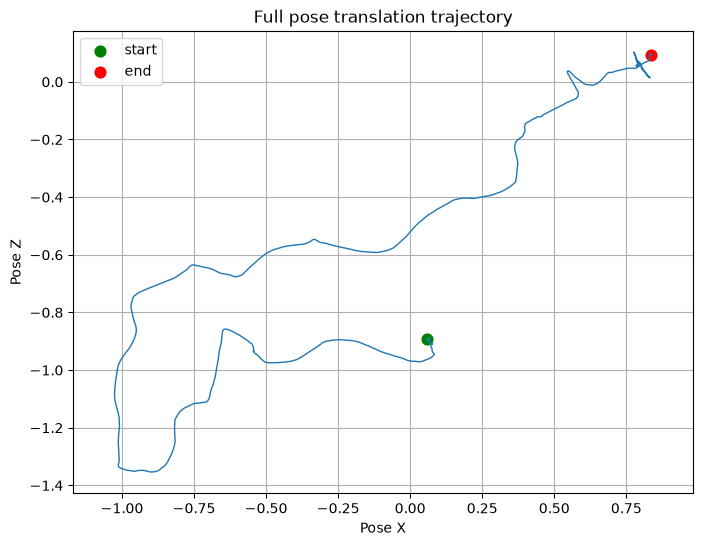

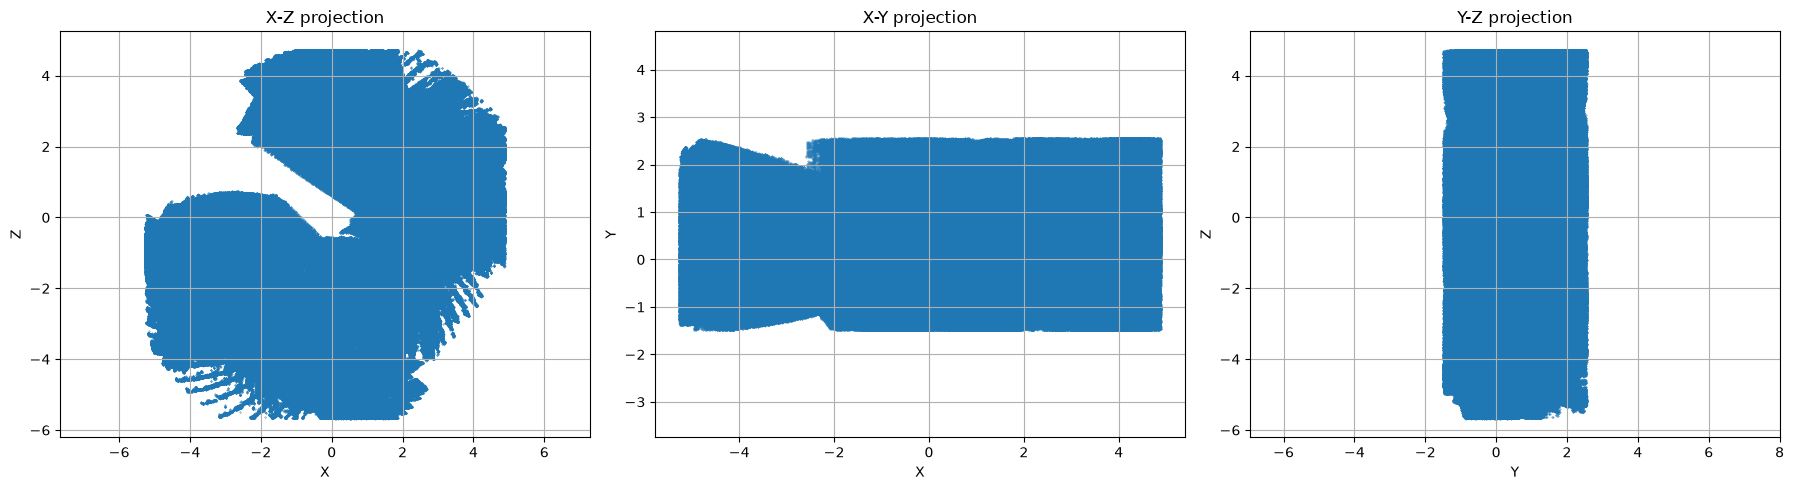

Point-cloud Y percentiles:
[-1.34173039 -1.07484556 -0.88120514 -0.41081772  0.42872797  1.19060349
  1.77894255  2.06262708  2.37855552]


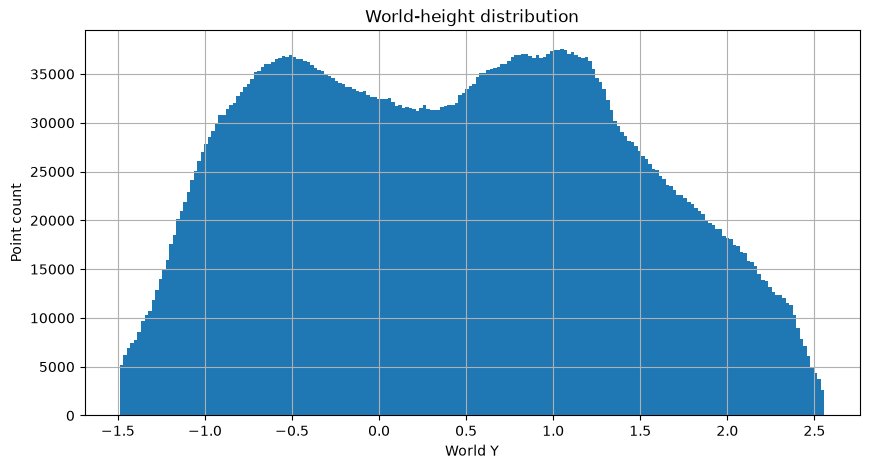

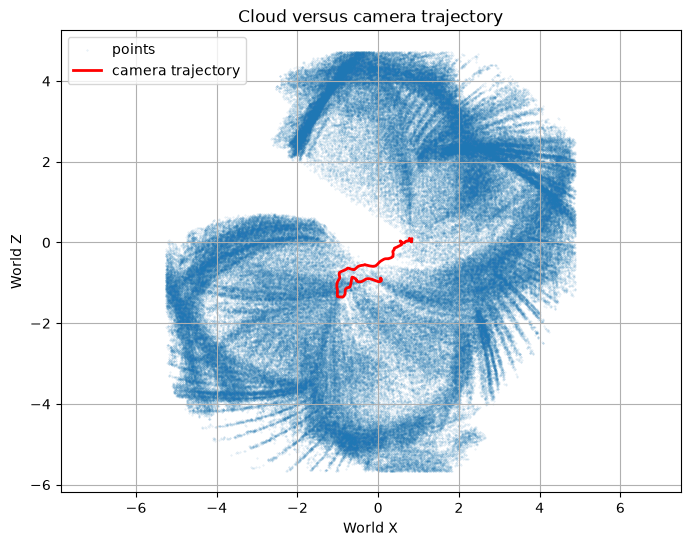

In [56]:
# ============================================================
# RECONSTRUCTION DIAGNOSTICS
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import open3d as o3d


# ------------------------------------------------------------
# 1. Inspect pose translation trajectory
# ------------------------------------------------------------

translation_positions = poses[:, :3]

print("Pose translation min:")
print(translation_positions.min(axis=0))

print("Pose translation max:")
print(translation_positions.max(axis=0))

print("Pose translation range:")
print(np.ptp(translation_positions, axis=0))

plt.figure(figsize=(8, 6))
plt.plot(
    translation_positions[:, 0],
    translation_positions[:, 2],
    linewidth=1,
)
plt.scatter(
    translation_positions[0, 0],
    translation_positions[0, 2],
    c="green",
    s=60,
    label="start",
)
plt.scatter(
    translation_positions[-1, 0],
    translation_positions[-1, 2],
    c="red",
    s=60,
    label="end",
)
plt.xlabel("Pose X")
plt.ylabel("Pose Z")
plt.title("Full pose translation trajectory")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()


# ------------------------------------------------------------
# 2. Inspect fused cloud using three orthographic projections
# ------------------------------------------------------------

cloud_points = np.asarray(pcd.points)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(
    cloud_points[:, 0],
    cloud_points[:, 2],
    s=0.1,
)
axes[0].set_title("X-Z projection")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Z")
axes[0].axis("equal")
axes[0].grid(True)

axes[1].scatter(
    cloud_points[:, 0],
    cloud_points[:, 1],
    s=0.1,
)
axes[1].set_title("X-Y projection")
axes[1].set_xlabel("X")
axes[1].set_ylabel("Y")
axes[1].axis("equal")
axes[1].grid(True)

axes[2].scatter(
    cloud_points[:, 1],
    cloud_points[:, 2],
    s=0.1,
)
axes[2].set_title("Y-Z projection")
axes[2].set_xlabel("Y")
axes[2].set_ylabel("Z")
axes[2].axis("equal")
axes[2].grid(True)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Inspect point height distribution
# ------------------------------------------------------------

world_y = cloud_points[:, 1]

print("Point-cloud Y percentiles:")
print(
    np.percentile(
        world_y,
        [1, 5, 10, 25, 50, 75, 90, 95, 99],
    )
)

plt.figure(figsize=(10, 5))
plt.hist(
    world_y,
    bins=200,
)
plt.xlabel("World Y")
plt.ylabel("Point count")
plt.title("World-height distribution")
plt.grid(True)
plt.show()


# ------------------------------------------------------------
# 4. Check whether all frames align near the trajectory
# ------------------------------------------------------------

camera_centers_array = np.asarray(camera_centers)

plt.figure(figsize=(8, 6))
plt.scatter(
    cloud_points[::20, 0],
    cloud_points[::20, 2],
    s=0.1,
    alpha=0.2,
    label="points",
)
plt.plot(
    camera_centers_array[:, 0],
    camera_centers_array[:, 2],
    "r-",
    linewidth=2,
    label="camera trajectory",
)
plt.xlabel("World X")
plt.ylabel("World Z")
plt.title("Cloud versus camera trajectory")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

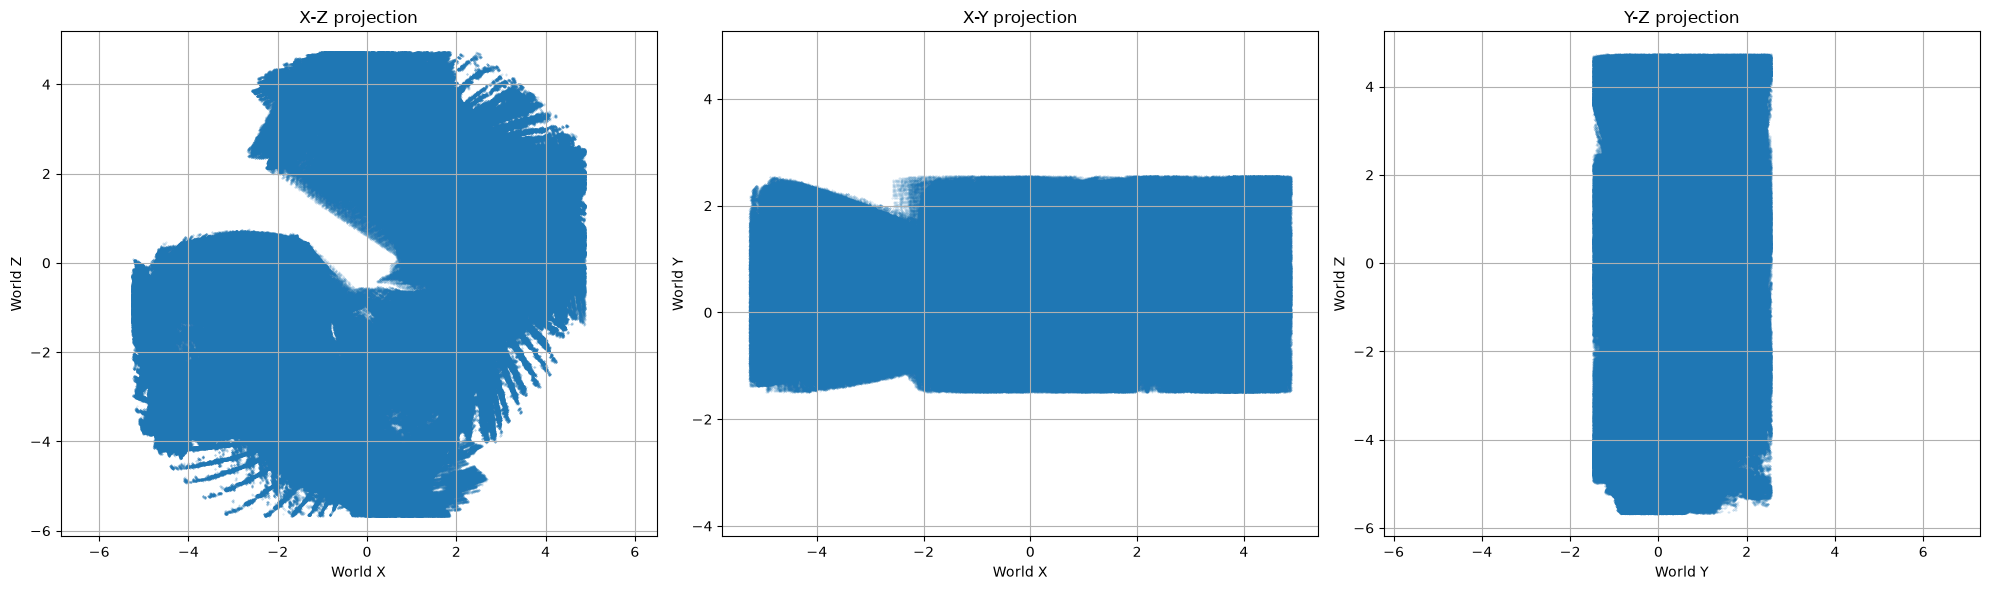

In [57]:
# ============================================================
# DIAGNOSTIC: ORTHOGRAPHIC CLOUD PROJECTIONS
# ============================================================

cloud_points = np.asarray(pcd.points)

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# X-Z: expected horizontal/top-down plane
axes[0].scatter(
    cloud_points[:, 0],
    cloud_points[:, 2],
    s=0.1,
    alpha=0.25,
)
axes[0].set_title("X-Z projection")
axes[0].set_xlabel("World X")
axes[0].set_ylabel("World Z")
axes[0].axis("equal")
axes[0].grid(True)

# X-Y: should show vertical structure
axes[1].scatter(
    cloud_points[:, 0],
    cloud_points[:, 1],
    s=0.1,
    alpha=0.25,
)
axes[1].set_title("X-Y projection")
axes[1].set_xlabel("World X")
axes[1].set_ylabel("World Y")
axes[1].axis("equal")
axes[1].grid(True)

# Y-Z: should show vertical structure
axes[2].scatter(
    cloud_points[:, 1],
    cloud_points[:, 2],
    s=0.1,
    alpha=0.25,
)
axes[2].set_title("Y-Z projection")
axes[2].set_xlabel("World Y")
axes[2].set_ylabel("World Z")
axes[2].axis("equal")
axes[2].grid(True)

plt.tight_layout()
plt.show()

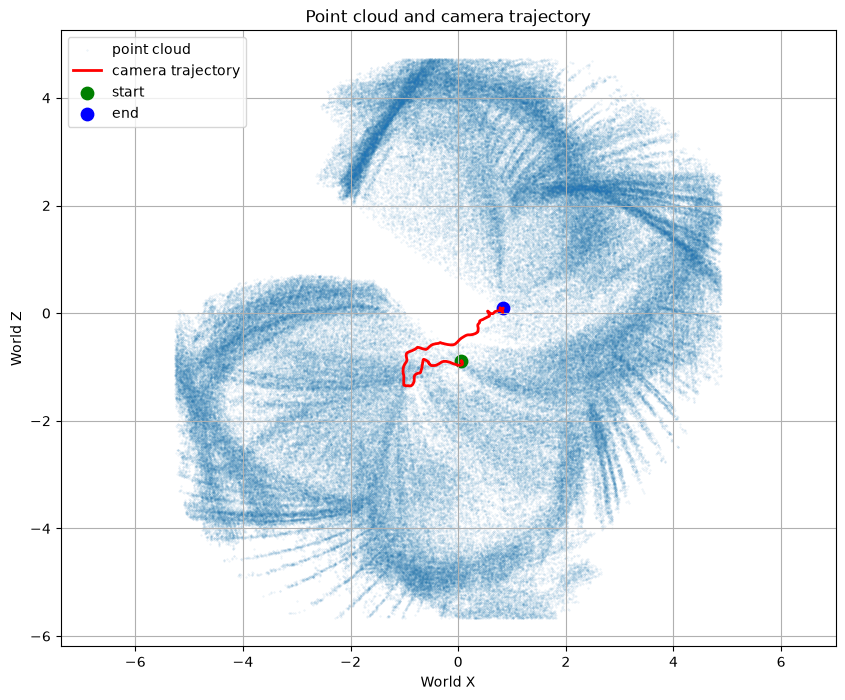

In [58]:
# ============================================================
# CLOUD AND CAMERA TRAJECTORY
# ============================================================

camera_centers_array = np.asarray(camera_centers)

plt.figure(figsize=(10, 8))

plt.scatter(
    cloud_points[::20, 0],
    cloud_points[::20, 2],
    s=0.1,
    alpha=0.15,
    label="point cloud",
)

plt.plot(
    camera_centers_array[:, 0],
    camera_centers_array[:, 2],
    "r-",
    linewidth=2,
    label="camera trajectory",
)

plt.scatter(
    camera_centers_array[0, 0],
    camera_centers_array[0, 2],
    c="green",
    s=80,
    label="start",
)

plt.scatter(
    camera_centers_array[-1, 0],
    camera_centers_array[-1, 2],
    c="blue",
    s=80,
    label="end",
)

plt.xlabel("World X")
plt.ylabel("World Z")
plt.title("Point cloud and camera trajectory")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

In [59]:
# ============================================================
# DEPTH QUANTIZATION CHECK
# ============================================================

for frame_idx in [0, 500, 1000, 1500, 2090]:

    depth = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    finite = depth[
        np.isfinite(depth)
        & (depth > 0)
    ]

    unique_values = np.unique(depth)

    print(f"\nFrame {frame_idx}")
    print("min:", finite.min())
    print("max:", finite.max())
    print("median:", np.median(finite))
    print("unique count:", len(unique_values))
    print("unique first:", unique_values[:10])
    print("unique last:", unique_values[-10:])


Frame 0
min: 1.0
max: 255.0
median: 135.0
unique count: 220
unique first: [ 0.  1.  2.  3.  4.  5.  6.  8.  9. 10.]
unique last: [244. 245. 246. 248. 249. 250. 251. 252. 253. 255.]

Frame 500
min: 3.0
max: 255.0
median: 125.0
unique count: 217
unique first: [ 3.  4.  5.  6.  8.  9. 10. 11. 12. 13.]
unique last: [244. 245. 246. 248. 249. 250. 251. 252. 253. 255.]

Frame 1000
min: 3.0
max: 255.0
median: 150.0
unique count: 216
unique first: [ 3.  4.  5.  6.  8.  9. 10. 11. 12. 13.]
unique last: [243. 244. 245. 246. 248. 249. 250. 251. 253. 255.]

Frame 1500
min: 1.0
max: 255.0
median: 132.0
unique count: 220
unique first: [ 0.  1.  2.  3.  4.  5.  6.  8.  9. 10.]
unique last: [244. 245. 246. 248. 249. 250. 251. 252. 253. 255.]

Frame 2090
min: 1.0
max: 255.0
median: 187.0
unique count: 220
unique first: [ 0.  1.  2.  3.  4.  5.  6.  8.  9. 10.]
unique last: [244. 245. 246. 248. 249. 250. 251. 252. 253. 255.]


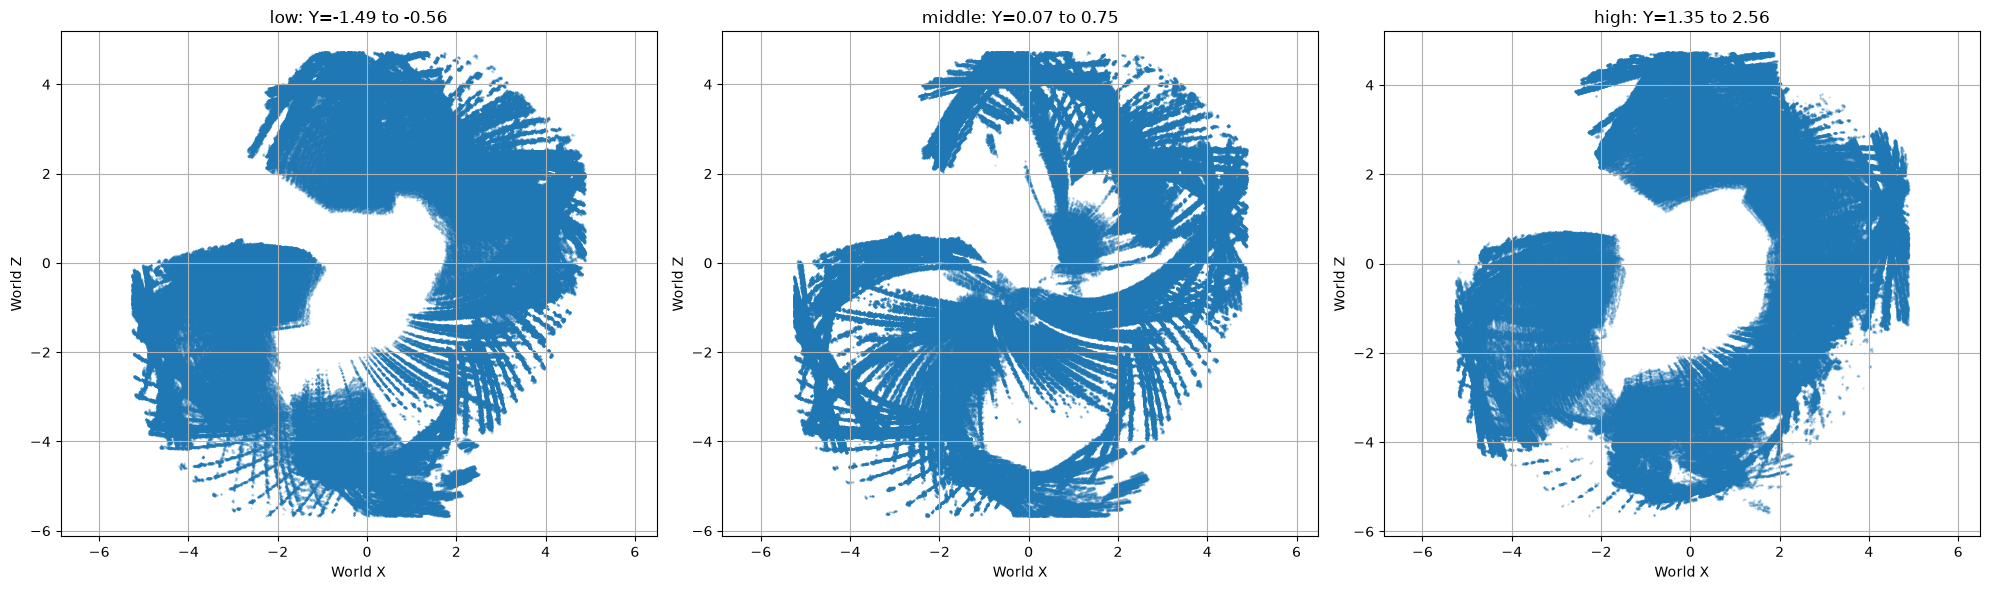

In [60]:
# ============================================================
# HEIGHT-BAND PROJECTIONS
# ============================================================

y = cloud_points[:, 1]

bands = {
    "low": (np.percentile(y, 0), np.percentile(y, 20)),
    "middle": (np.percentile(y, 40), np.percentile(y, 60)),
    "high": (np.percentile(y, 80), np.percentile(y, 100)),
}

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (name, (ymin_band, ymax_band)) in zip(
    axes,
    bands.items(),
):
    mask = (y >= ymin_band) & (y <= ymax_band)

    ax.scatter(
        cloud_points[mask, 0],
        cloud_points[mask, 2],
        s=0.2,
        alpha=0.3,
    )

    ax.set_title(
        f"{name}: Y={ymin_band:.2f} to {ymax_band:.2f}"
    )
    ax.set_xlabel("World X")
    ax.set_ylabel("World Z")
    ax.axis("equal")
    ax.grid(True)

plt.tight_layout()
plt.show()

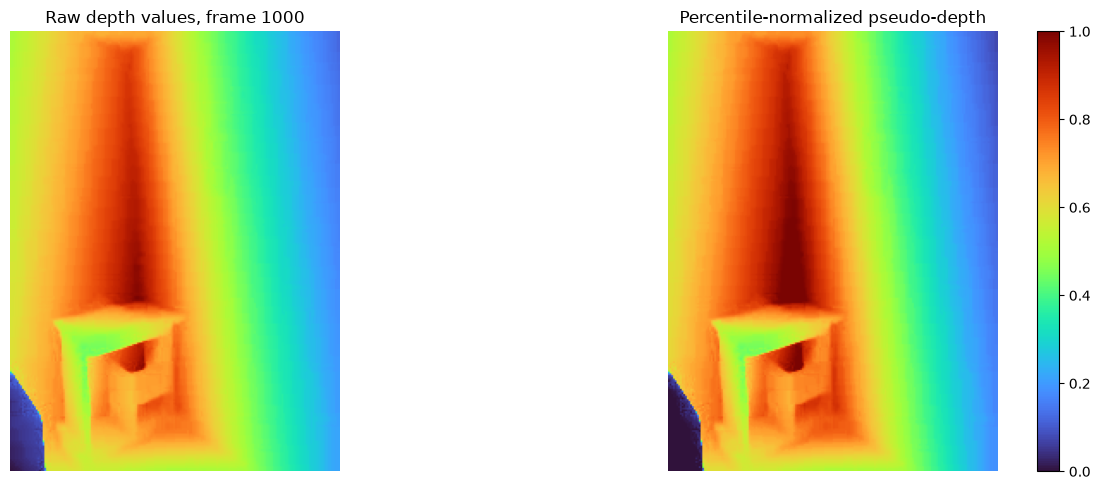

In [61]:
# ============================================================
# PSEUDO-DEPTH DIAGNOSTIC
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


def normalize_depth_for_visualization(depth):
    depth = depth.astype(np.float32)

    valid = np.isfinite(depth) & (depth > 0)

    output = np.zeros_like(depth, dtype=np.float32)

    if valid.sum() == 0:
        return output

    low, high = np.percentile(
        depth[valid],
        [1, 99],
    )

    clipped = np.clip(depth, low, high)

    output[valid] = (
        (clipped[valid] - low)
        / max(high - low, 1e-6)
    )

    return output


frame_idx = 1000

depth_raw = np.load(
    depth_files[frame_idx]
).astype(np.float32)

depth_vis = normalize_depth_for_visualization(
    depth_raw
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5),
)

axes[0].imshow(
    depth_raw,
    cmap="turbo",
)

axes[0].set_title(
    f"Raw depth values, frame {frame_idx}"
)

axes[0].axis("off")

im = axes[1].imshow(
    depth_vis,
    cmap="turbo",
    vmin=0,
    vmax=1,
)

axes[1].set_title(
    "Percentile-normalized pseudo-depth"
)

axes[1].axis("off")

plt.colorbar(
    im,
    ax=axes[1],
)

plt.tight_layout()
plt.show()

In [62]:
# ============================================================
# DEPTH ORDER TEST
# ============================================================

frame_idx = 1000
depth = np.load(
    depth_files[frame_idx]
).astype(np.float32)

h, w = depth.shape

regions = {
    "top_left": depth[:h // 3, :w // 3],
    "top_center": depth[:h // 3, w // 3:2 * w // 3],
    "top_right": depth[:h // 3, 2 * w // 3:],
    "center": depth[h // 3:2 * h // 3, w // 3:2 * w // 3],
    "bottom_left": depth[2 * h // 3:, :w // 3],
    "bottom_center": depth[2 * h // 3:, w // 3:2 * w // 3],
    "bottom_right": depth[2 * h // 3:, 2 * w // 3:],
}

for name, region in regions.items():
    valid = region[
        np.isfinite(region) & (region > 0)
    ]

    print(
        name,
        "median =",
        float(np.median(valid)) if len(valid) else None,
        "mean =",
        float(np.mean(valid)) if len(valid) else None,
    )

top_left median = 171.0 mean = 171.8413543701172
top_center median = 164.0 mean = 165.90496826171875
top_right median = 68.0 mean = 70.28897094726562
center median = 182.0 mean = 184.82977294921875
bottom_left median = 157.0 mean = 138.19876098632812
bottom_center median = 174.0 mean = 172.72511291503906
bottom_right median = 90.0 mean = 92.3001480102539


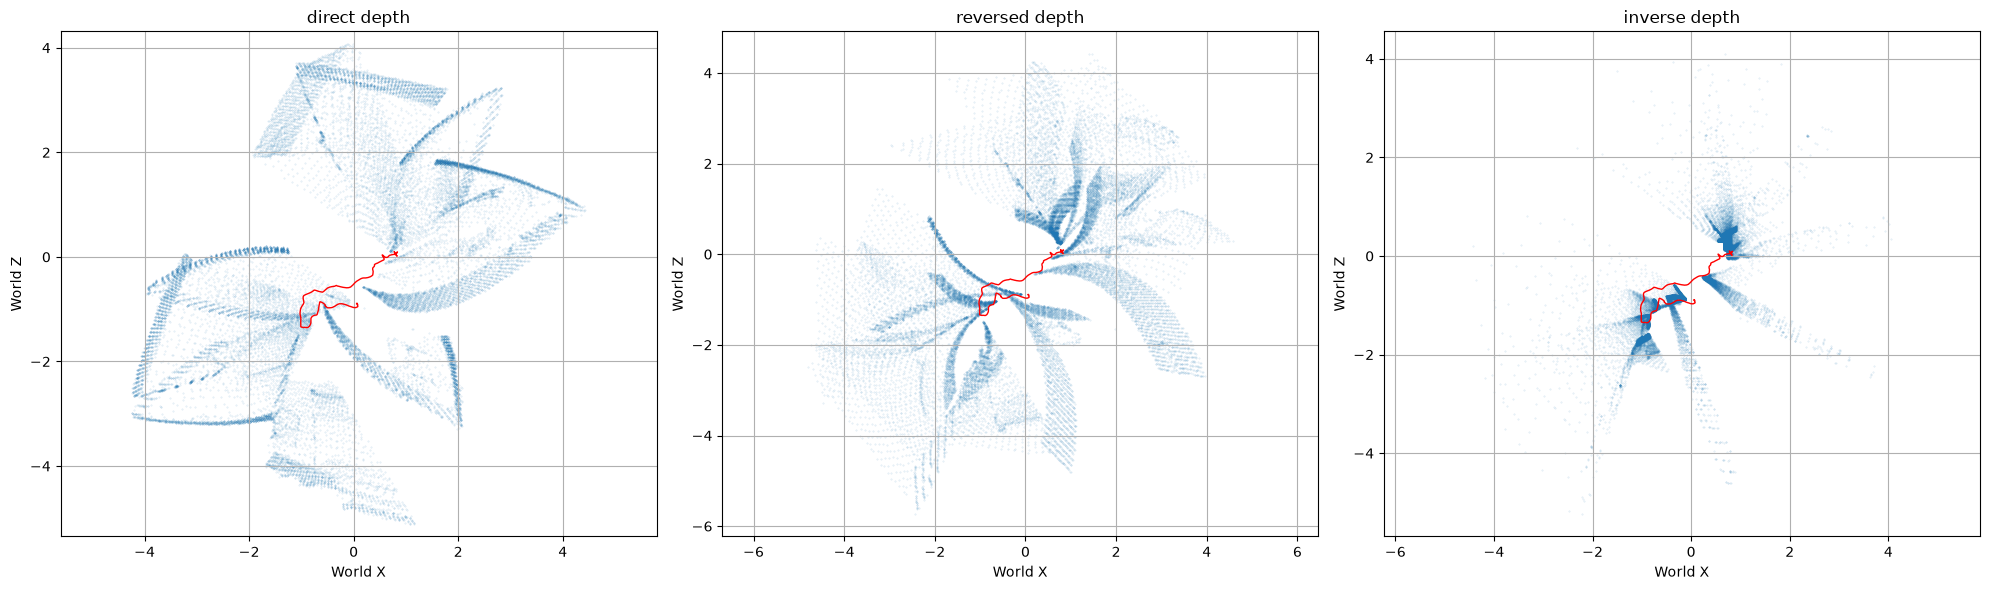

In [63]:
# ============================================================
# TEST DEPTH INTERPRETATIONS
# ============================================================

import numpy as np
import open3d as o3d
import matplotlib.pyplot as plt


def create_camera_points_from_depth(
    depth_raw,
    interpretation,
    max_depth_m=4.0,
):
    depth_raw = depth_raw.astype(np.float32)

    valid_raw = (
        np.isfinite(depth_raw)
        & (depth_raw > 0)
    )

    if interpretation == "direct":
        z = depth_raw / 255.0 * max_depth_m

    elif interpretation == "reversed":
        z = (255.0 - depth_raw) / 255.0 * max_depth_m

    elif interpretation == "inverse":
        normalized = depth_raw / 255.0
        z = 1.0 / np.maximum(normalized, 1e-3)
        z = z / np.percentile(z[valid_raw], 99) * max_depth_m

    else:
        raise ValueError(
            f"Unknown interpretation: {interpretation}"
        )

    valid = (
        valid_raw
        & np.isfinite(z)
        & (z > 0.15)
        & (z < max_depth_m)
    )

    v, u = np.indices(depth_raw.shape)

    x = (u[valid] - CX) * z[valid] / FX
    y = (v[valid] - CY) * z[valid] / FY

    points_camera = np.column_stack(
        [x, y, z[valid]]
    )

    return points_camera


def make_world_points_for_test(
    interpretation,
    frame_ids,
    max_depth_m=4.0,
):
    output = []

    for frame_idx in frame_ids:
        depth = np.load(
            depth_files[frame_idx]
        ).astype(np.float32)

        points_camera = create_camera_points_from_depth(
            depth,
            interpretation,
            max_depth_m=max_depth_m,
        )

        T_camera_to_world = (
            pose_to_matrix_camera_to_world(
                poses[frame_idx]
            )
        )

        points_world = transform_points(
            points_camera,
            T_camera_to_world
        )

        output.append(points_world)

    return np.vstack(output)


test_frame_ids = np.linspace(
    0,
    len(depth_files) - 1,
    10,
    dtype=np.int32,
)

interpretations = [
    "direct",
    "reversed",
    "inverse",
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 6),
)

for ax, interpretation in zip(
    axes,
    interpretations,
):
    test_points = make_world_points_for_test(
        interpretation,
        test_frame_ids,
        max_depth_m=4.0,
    )

    ax.scatter(
        test_points[::20, 0],
        test_points[::20, 2],
        s=0.1,
        alpha=0.2,
    )

    ax.plot(
        camera_centers[:, 0],
        camera_centers[:, 2],
        "r-",
        linewidth=1,
    )

    ax.set_title(
        f"{interpretation} depth"
    )
    ax.set_xlabel("World X")
    ax.set_ylabel("World Z")
    ax.axis("equal")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [64]:
# ============================================================
# CHECK DEPTH REPRESENTATION
# ============================================================

for frame_idx in [0, 1000, 2090]:
    depth = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    rounded = np.round(depth)

    print(
        f"Frame {frame_idx}:"
    )
    print(
        "all values integer-like:",
        np.allclose(depth, rounded)
    )
    print(
        "fractional values:",
        np.sum(np.abs(depth - rounded) > 1e-6)
    )
    print(
        "unique values:",
        len(np.unique(depth))
    )
    print(
        "range:",
        depth.min(),
        depth.max()
    )

Frame 0:
all values integer-like: True
fractional values: 0
unique values: 220
range: 0.0 255.0
Frame 1000:
all values integer-like: True
fractional values: 0
unique values: 216
range: 3.0 255.0
Frame 2090:
all values integer-like: True
fractional values: 0
unique values: 220
range: 0.0 255.0


Map width: 395
Map height: 374
Map physical width: 7.8638864159584045
Map physical height: 7.457104936242104
Processed frame 0000
Processed frame 0250


Processed frame 0500
Processed frame 0750


Processed frame 1000
Processed frame 1250


Processed frame 1500
Processed frame 1750


Processed frame 2000


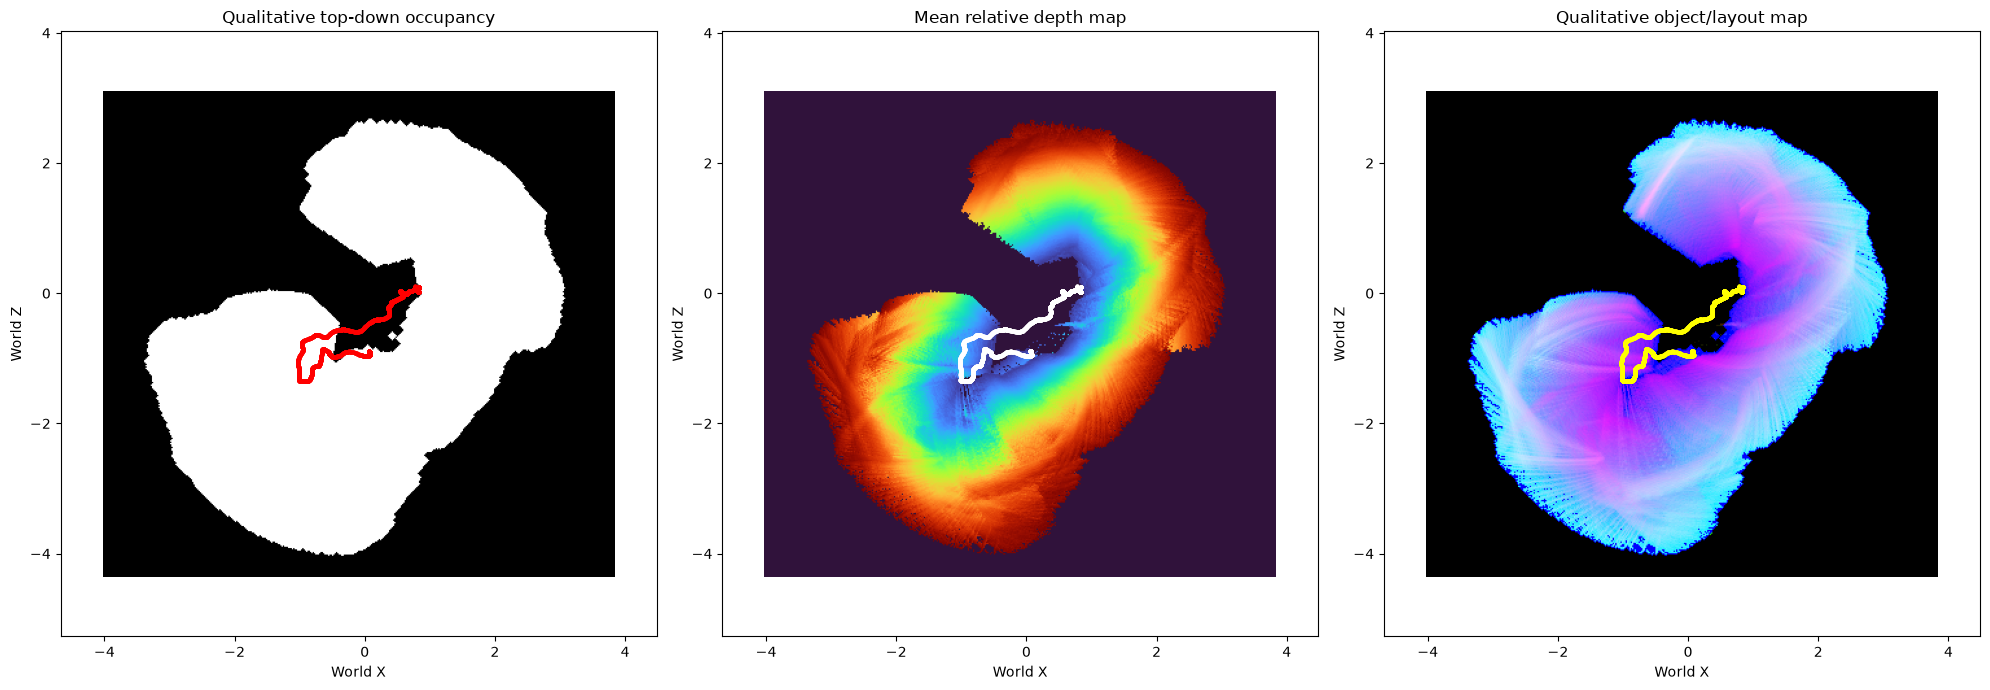

Saved:
D:/VLM-maps/outputs/reconstruction_outputs\qualitative_topdown_occupancy.png
D:/VLM-maps/outputs/reconstruction_outputs\qualitative_object_map.png


D:/VLM-maps/outputs/reconstruction_outputs\camera_position_rgb_map.png


In [65]:
# ============================================================
# QUALITATIVE TOP-DOWN ROOM MAP FROM 8-BIT DEPTH + POSES
# ============================================================

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from scipy.ndimage import (
    binary_closing,
    binary_opening,
    binary_dilation,
    gaussian_filter,
)


# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

MAP_RESOLUTION = 0.02

# The camera trajectory is approximately 1.86 m x 1.46 m.
# Use a larger map around it to contain visible surfaces.
MAP_MARGIN = 3.0

# Number of frames used for the map.
FRAME_STEP = 5

# Use every Nth depth pixel to reduce memory.
PIXEL_STEP = 2

# Relative-depth assumptions.
# These are not metres.
NEAR_PERCENTILE = 5
FAR_PERCENTILE = 98

# Height bands are relative depth bands, not real-world heights.
# Start with points in front of the camera but reject extreme values.
MIN_RELATIVE_DEPTH = 0.05
MAX_RELATIVE_DEPTH = 0.95

# Outputs
TOPDOWN_PATH = os.path.join(
    OUTPUT_DIR,
    "qualitative_topdown_occupancy.png",
)

OBJECT_MAP_PATH = os.path.join(
    OUTPUT_DIR,
    "qualitative_object_map.png",
)

RGB_MAP_PATH = os.path.join(
    OUTPUT_DIR,
    "camera_position_rgb_map.png",
)


# ------------------------------------------------------------
# 2. Build a fixed map coordinate system from poses
# ------------------------------------------------------------

pose_positions = poses[:, :3].copy()

# We assume world Y is approximately vertical.
# Use world X-Z as the top-down plane.
pose_x = pose_positions[:, 0]
pose_z = pose_positions[:, 2]

map_x_min = pose_x.min() - MAP_MARGIN
map_x_max = pose_x.max() + MAP_MARGIN
map_z_min = pose_z.min() - MAP_MARGIN
map_z_max = pose_z.max() + MAP_MARGIN

map_width = int(
    np.ceil(
        (map_x_max - map_x_min)
        / MAP_RESOLUTION
    )
) + 1

map_height = int(
    np.ceil(
        (map_z_max - map_z_min)
        / MAP_RESOLUTION
    )
) + 1

print("Map width:", map_width)
print("Map height:", map_height)
print("Map physical width:", map_x_max - map_x_min)
print("Map physical height:", map_z_max - map_z_min)


def world_to_grid(x, z):
    gx = np.floor(
        (x - map_x_min)
        / MAP_RESOLUTION
    ).astype(np.int32)

    gz = np.floor(
        (z - map_z_min)
        / MAP_RESOLUTION
    ).astype(np.int32)

    valid = (
        (gx >= 0)
        & (gx < map_width)
        & (gz >= 0)
        & (gz < map_height)
    )

    return gx, gz, valid


def grid_to_world(gx, gz):
    x = gx * MAP_RESOLUTION + map_x_min
    z = gz * MAP_RESOLUTION + map_z_min
    return x, z


# ------------------------------------------------------------
# 3. Relative-depth conversion
# ------------------------------------------------------------

def relative_depth(depth_raw):
    """
    Converts 8-bit-like depth into a normalized relative depth.

    This preserves ordering only.
    It does not produce metres.
    """

    depth_raw = depth_raw.astype(np.float32)

    valid = (
        np.isfinite(depth_raw)
        & (depth_raw > 0)
    )

    output = np.zeros_like(
        depth_raw,
        dtype=np.float32,
    )

    if valid.sum() == 0:
        return output, valid

    low, high = np.percentile(
        depth_raw[valid],
        [NEAR_PERCENTILE, FAR_PERCENTILE],
    )

    clipped = np.clip(
        depth_raw,
        low,
        high,
    )

    output[valid] = (
        clipped[valid] - low
    ) / max(high - low, 1e-6)

    return output, valid


# ------------------------------------------------------------
# 4. Camera-ray projection
# ------------------------------------------------------------

# Provisional depth intrinsics from the current notebook.
# These affect horizontal spread but do not determine metric scale.
FX = 200.0
FY = 200.0
CX = 96.0
CY = 127.712

depth_sample = np.load(depth_files[0])
DEPTH_H, DEPTH_W = depth_sample.shape


def project_relative_depth_to_world(
    depth_raw,
    transform_camera_to_world,
):
    relative, valid = relative_depth(depth_raw)

    v, u = np.indices(
        depth_raw.shape
    )

    pixel_keep = (
        valid
        & (relative >= MIN_RELATIVE_DEPTH)
        & (relative <= MAX_RELATIVE_DEPTH)
        & ((u % PIXEL_STEP) == 0)
        & ((v % PIXEL_STEP) == 0)
    )

    v_sel = v[pixel_keep]
    u_sel = u[pixel_keep]
    d_sel = relative[pixel_keep]

    # Pseudo-distance. This is deliberately normalized.
    # It only creates a qualitative spatial arrangement.
    pseudo_z = (
        0.5
        + 2.0 * d_sel
    )

    pseudo_x = (
        (u_sel - CX)
        * pseudo_z
        / FX
    )

    pseudo_y = (
        (v_sel - CY)
        * pseudo_z
        / FY
    )

    points_camera = np.column_stack(
        [
            pseudo_x,
            pseudo_y,
            pseudo_z,
        ]
    )

    points_h = np.column_stack(
        [
            points_camera,
            np.ones(
                len(points_camera),
                dtype=np.float32,
            ),
        ]
    )

    points_world = (
        transform_camera_to_world
        @ points_h.T
    ).T[:, :3]

    return points_world, d_sel


# ------------------------------------------------------------
# 5. Accumulate relative occupancy
# ------------------------------------------------------------

occupancy_count = np.zeros(
    (map_height, map_width),
    dtype=np.float32,
)

depth_sum = np.zeros_like(
    occupancy_count
)

depth_count = np.zeros_like(
    occupancy_count
)

camera_grid_x = []
camera_grid_z = []

frame_indices = np.arange(
    0,
    len(depth_files),
    FRAME_STEP,
    dtype=np.int32,
)

for count, frame_idx in enumerate(frame_indices):

    depth_raw = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    T_camera_to_world = (
        pose_to_matrix_camera_to_world(
            poses[frame_idx]
        )
    )

    points_world, relative_values = (
        project_relative_depth_to_world(
            depth_raw,
            T_camera_to_world,
        )
    )

    x = points_world[:, 0]
    z = points_world[:, 2]

    gx, gz, valid_grid = world_to_grid(
        x,
        z,
    )

    gx = gx[valid_grid]
    gz = gz[valid_grid]
    relative_values = relative_values[valid_grid]

    np.add.at(
        occupancy_count,
        (gz, gx),
        1,
    )

    np.add.at(
        depth_sum,
        (gz, gx),
        relative_values,
    )

    np.add.at(
        depth_count,
        (gz, gx),
        1,
    )

    cam_x, cam_z, cam_valid = world_to_grid(
        np.array([poses[frame_idx, 0]]),
        np.array([poses[frame_idx, 2]]),
    )

    if cam_valid[0]:
        camera_grid_x.append(cam_x[0])
        camera_grid_z.append(cam_z[0])

    if count % 50 == 0:
        print(
            f"Processed frame {frame_idx:04d}"
        )


# ------------------------------------------------------------
# 6. Convert counts into an occupancy image
# ------------------------------------------------------------

occupancy_log = np.log1p(
    occupancy_count
)

if occupancy_log.max() > 0:
    occupancy_norm = (
        occupancy_log
        / occupancy_log.max()
    )
else:
    occupancy_norm = occupancy_log

# Remove isolated noise and close small gaps.
occupancy_binary = occupancy_norm > 0.08

occupancy_binary = binary_closing(
    occupancy_binary,
    iterations=3,
)

occupancy_binary = binary_opening(
    occupancy_binary,
    iterations=2,
)

occupancy_binary = binary_dilation(
    occupancy_binary,
    iterations=1,
)

occupancy_image = (
    occupancy_binary.astype(np.uint8)
    * 255
)

Image.fromarray(
    occupancy_image
).save(
    TOPDOWN_PATH
)


# ------------------------------------------------------------
# 7. Create object/layout map
# ------------------------------------------------------------

mean_relative_depth = np.zeros_like(
    depth_sum
)

has_depth = depth_count > 0

mean_relative_depth[has_depth] = (
    depth_sum[has_depth]
    / depth_count[has_depth]
)

# Occupancy strength represents repeated observations.
# Mean relative depth adds qualitative depth information.
object_map = np.zeros(
    (map_height, map_width, 3),
    dtype=np.uint8,
)

strength = occupancy_norm

# Red channel: frequently observed structure.
object_map[:, :, 0] = (
    np.clip(strength * 255, 0, 255)
    .astype(np.uint8)
)

# Green channel: relative depth.
object_map[:, :, 1] = (
    np.clip(mean_relative_depth * 255, 0, 255)
    .astype(np.uint8)
)

# Blue channel: cleaned occupancy.
object_map[:, :, 2] = occupancy_image

Image.fromarray(
    object_map
).save(
    OBJECT_MAP_PATH
)


# ------------------------------------------------------------
# 8. Plot qualitative top-down map
# ------------------------------------------------------------

extent = [
    map_x_min,
    map_x_max,
    map_z_min,
    map_z_max,
]

fig, axes = plt.subplots(
    1,
    3,
    figsize=(20, 7),
)

axes[0].imshow(
    occupancy_image,
    cmap="gray",
    origin="lower",
    extent=extent,
)

axes[0].scatter(
    pose_x,
    pose_z,
    s=4,
    c="red",
)

axes[0].set_title(
    "Qualitative top-down occupancy"
)

axes[0].set_xlabel("World X")
axes[0].set_ylabel("World Z")
axes[0].axis("equal")

axes[1].imshow(
    mean_relative_depth,
    cmap="turbo",
    origin="lower",
    extent=extent,
)

axes[1].scatter(
    pose_x,
    pose_z,
    s=4,
    c="white",
)

axes[1].set_title(
    "Mean relative depth map"
)

axes[1].set_xlabel("World X")
axes[1].set_ylabel("World Z")
axes[1].axis("equal")

axes[2].imshow(
    object_map,
    origin="lower",
    extent=extent,
)

axes[2].scatter(
    pose_x,
    pose_z,
    s=4,
    c="yellow",
)

axes[2].set_title(
    "Qualitative object/layout map"
)

axes[2].set_xlabel("World X")
axes[2].set_ylabel("World Z")
axes[2].axis("equal")

plt.tight_layout()
plt.show()

print("Saved:")
print(TOPDOWN_PATH)
print(OBJECT_MAP_PATH)


# ------------------------------------------------------------
# 9. Optional: create an RGB camera-position mosaic
# ------------------------------------------------------------

rgb_map = np.zeros(
    (map_height, map_width, 3),
    dtype=np.float32,
)

rgb_weight = np.zeros(
    (map_height, map_width),
    dtype=np.float32,
)

for count, frame_idx in enumerate(frame_indices):

    rgb = np.asarray(
        Image.open(
            rgb_files[frame_idx]
        ).convert("RGB")
    )

    # Use the average color as a coarse frame descriptor.
    frame_color = rgb.mean(
        axis=(0, 1)
    ) / 255.0

    gx, gz, valid = world_to_grid(
        np.array([poses[frame_idx, 0]]),
        np.array([poses[frame_idx, 2]]),
    )

    if not valid[0]:
        continue

    x0 = max(0, gx[0] - 3)
    x1 = min(map_width, gx[0] + 4)
    z0 = max(0, gz[0] - 3)
    z1 = min(map_height, gz[0] + 4)

    rgb_map[z0:z1, x0:x1] += frame_color
    rgb_weight[z0:z1, x0:x1] += 1.0

rgb_weight_safe = np.maximum(
    rgb_weight[:, :, None],
    1e-6,
)

rgb_map = rgb_map / rgb_weight_safe
rgb_map = np.clip(
    rgb_map * 255,
    0,
    255,
).astype(np.uint8)

Image.fromarray(
    rgb_map
).save(
    RGB_MAP_PATH
)

print(RGB_MAP_PATH)

In [66]:
# ============================================================
# RGB OBJECT DETECTION + QUALITATIVE TOP-DOWN OBJECT MAP
# ============================================================

from ultralytics import YOLO
from collections import defaultdict
import pandas as pd


# ------------------------------------------------------------
# 1. Load detector
# ------------------------------------------------------------

model = YOLO("yolo11n.pt")


# ------------------------------------------------------------
# 2. RGB-to-depth coordinate conversion
# ------------------------------------------------------------

sample_rgb = np.asarray(
    Image.open(rgb_files[0]).convert("RGB")
)

RGB_H, RGB_W = sample_rgb.shape[:2]

scale_x = DEPTH_W / RGB_W
scale_y = DEPTH_H / RGB_H


# ------------------------------------------------------------
# 3. Detection configuration
# ------------------------------------------------------------

DETECTION_FRAME_STEP = 10
CONFIDENCE_THRESHOLD = 0.35

detections = []
object_positions = defaultdict(list)


# ------------------------------------------------------------
# 4. Convert relative depth to pseudo camera point
# ------------------------------------------------------------

def relative_depth_at_rgb_point(
    depth_raw,
    x_rgb,
    y_rgb,
):
    x_depth = int(
        np.clip(
            x_rgb * scale_x,
            0,
            DEPTH_W - 1,
        )
    )

    y_depth = int(
        np.clip(
            y_rgb * scale_y,
            0,
            DEPTH_H - 1,
        )
    )

    radius = 3

    x0 = max(0, x_depth - radius)
    x1 = min(DEPTH_W, x_depth + radius + 1)
    y0 = max(0, y_depth - radius)
    y1 = min(DEPTH_H, y_depth + radius + 1)

    patch = depth_raw[y0:y1, x0:x1]

    values = patch[
        np.isfinite(patch)
        & (patch > 0)
    ]

    if len(values) == 0:
        return None

    low, high = np.percentile(
        depth_raw[
            np.isfinite(depth_raw)
            & (depth_raw > 0)
        ],
        [NEAR_PERCENTILE, FAR_PERCENTILE],
    )

    value = np.median(values)

    relative = (
        np.clip(value, low, high) - low
    ) / max(high - low, 1e-6)

    return float(relative)


def detection_to_world_position(
    frame_idx,
    x_rgb,
    y_rgb,
    depth_raw,
):
    relative = relative_depth_at_rgb_point(
        depth_raw,
        x_rgb,
        y_rgb,
    )

    if relative is None:
        return None, None

    pseudo_z = 0.5 + 2.0 * relative

    pseudo_x = (
        (x_rgb * scale_x - CX)
        * pseudo_z
        / FX
    )

    pseudo_y = (
        (y_rgb * scale_y - CY)
        * pseudo_z
        / FY
    )

    point_camera = np.array(
        [
            [pseudo_x, pseudo_y, pseudo_z]
        ],
        dtype=np.float64,
    )

    T_camera_to_world = (
        pose_to_matrix_camera_to_world(
            poses[frame_idx]
        )
    )

    point_world = transform_points(
        point_camera,
        T_camera_to_world,
    )[0]

    return point_world, relative


# ------------------------------------------------------------
# 5. Run object detection
# ------------------------------------------------------------

detection_frame_indices = np.arange(
    0,
    len(rgb_files),
    DETECTION_FRAME_STEP,
    dtype=np.int32,
)

for count, frame_idx in enumerate(
    detection_frame_indices
):

    results = model.predict(
        source=rgb_files[frame_idx],
        conf=CONFIDENCE_THRESHOLD,
        verbose=False,
    )

    result = results[0]

    if result.boxes is None:
        continue

    boxes = result.boxes.xyxy.cpu().numpy()
    scores = result.boxes.conf.cpu().numpy()
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    depth_raw = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    for box, score, class_id in zip(
        boxes,
        scores,
        class_ids,
    ):

        x1, y1, x2, y2 = box

        center_x = (x1 + x2) / 2.0
        center_y = (y1 + y2) / 2.0

        point_world, relative_depth_value = (
            detection_to_world_position(
                frame_idx,
                center_x,
                center_y,
                depth_raw,
            )
        )

        if point_world is None:
            continue

        class_name = model.names[int(class_id)]

        detections.append(
            {
                "frame_idx": int(frame_idx),
                "class_id": int(class_id),
                "class_name": class_name,
                "confidence": float(score),
                "x1": float(x1),
                "y1": float(y1),
                "x2": float(x2),
                "y2": float(y2),
                "center_x": float(center_x),
                "center_y": float(center_y),
                "relative_depth": float(
                    relative_depth_value
                ),
                "world_x": float(point_world[0]),
                "world_y": float(point_world[1]),
                "world_z": float(point_world[2]),
            }
        )

        object_positions[class_name].append(
            [
                point_world[0],
                point_world[2],
            ]
        )

    if count % 20 == 0:
        print(
            f"Detection frame {frame_idx:04d}"
        )


detections_df = pd.DataFrame(detections)

detections_csv = os.path.join(
    OUTPUT_DIR,
    "object_detections.csv",
)

detections_df.to_csv(
    detections_csv,
    index=False,
)

print("Detections:", len(detections_df))
print("Saved:", detections_csv)

WARNING user config directory 'D:\VLM-maps\.yolo\Ultralytics' is not writable, using 'D:\VLM-maps\Ultralytics'. Set YOLO_CONFIG_DIR to override.


Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'D:\VLM-maps\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


Detection frame 0000


Detection frame 0200


Detection frame 0400


...

Detection frame 1400


Detection frame 1600


Detection frame 1800


Detection frame 2000


Detections: 145
Saved: D:/VLM-maps/outputs/reconstruction_outputs\object_detections.csv


In [67]:
# Dependencies installed locally before execution.
pass

In [68]:
import ultralytics

print("Ultralytics version:", ultralytics.__version__)

Ultralytics version: 8.4.174


In [69]:
# ============================================================
# CLUSTER REPEATED OBJECT DETECTIONS
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN


detections_csv = os.path.join(
    OUTPUT_DIR,
    "object_detections.csv",
)

detections_df = pd.read_csv(
    detections_csv
)

print("Loaded detections:", len(detections_df))

if len(detections_df) == 0:
    raise RuntimeError(
        "No detections found in object_detections.csv"
    )


# ------------------------------------------------------------
# Cluster by object class in world X-Z coordinates
# ------------------------------------------------------------

clustered_objects = []

for class_name, group in detections_df.groupby(
    "class_name"
):

    coordinates = group[
        ["world_x", "world_z"]
    ].to_numpy(
        dtype=np.float64
    )

    if len(coordinates) == 1:
        labels = np.array([0], dtype=np.int32)
    else:
        labels = DBSCAN(
            eps=0.30,
            min_samples=2,
        ).fit_predict(coordinates)

    for cluster_id in sorted(
        set(labels)
    ):

        # DBSCAN label -1 means noise.
        if cluster_id == -1:
            continue

        mask = labels == cluster_id
        cluster_points = coordinates[mask]
        cluster_rows = group.iloc[
            np.where(mask)[0]
        ]

        clustered_objects.append(
            {
                "class_name": class_name,
                "cluster_id": int(cluster_id),
                "world_x": float(
                    cluster_points[:, 0].mean()
                ),
                "world_z": float(
                    cluster_points[:, 1].mean()
                ),
                "observations": int(
                    len(cluster_points)
                ),
                "mean_confidence": float(
                    cluster_rows[
                        "confidence"
                    ].mean()
                ),
            }
        )

clustered_df = pd.DataFrame(
    clustered_objects
)

clustered_csv = os.path.join(
    OUTPUT_DIR,
    "clustered_topdown_objects.csv",
)

clustered_df.to_csv(
    clustered_csv,
    index=False,
)

print(
    "Stable object clusters:",
    len(clustered_df),
)

print(clustered_df)

print(
    "Saved:",
    clustered_csv,
)

Loaded detections: 145
Stable object clusters: 7
  class_name  cluster_id   world_x   world_z  observations  mean_confidence
0        bed           0 -1.532187 -1.609911            38         0.731463
1      chair           0  0.944280 -0.131179             5         0.555723
2      chair           1  1.184765  0.838680            40         0.858254
3      couch           0 -1.096978 -1.976346            40         0.841071
4      couch           1 -0.483824 -1.237068             6         0.774475
5      couch           2  1.494226  0.252952             6         0.691229
6     person           0 -0.712671 -0.570629             3         0.496808
Saved: D:/VLM-maps/outputs/reconstruction_outputs\clustered_topdown_objects.csv


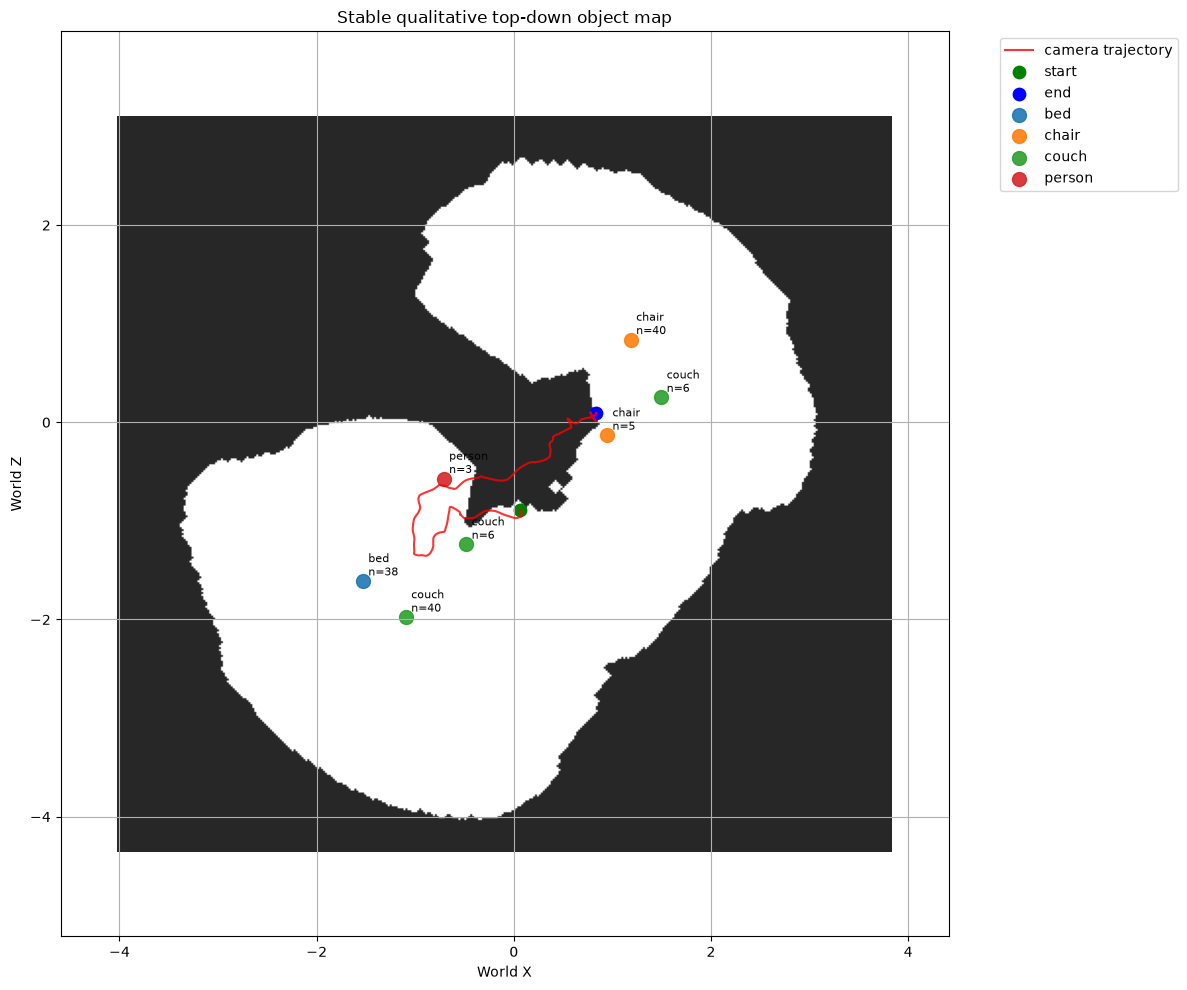

Saved: D:/VLM-maps/outputs/reconstruction_outputs\stable_topdown_object_map.png


In [70]:
# ============================================================
# PLOT STABLE OBJECT LOCATIONS
# ============================================================

plt.figure(figsize=(12, 10))

plt.imshow(
    occupancy_image,
    cmap="gray",
    origin="lower",
    extent=[
        map_x_min,
        map_x_max,
        map_z_min,
        map_z_max,
    ],
    alpha=0.85,
)

# Camera trajectory
plt.plot(
    pose_x,
    pose_z,
    color="red",
    linewidth=1.5,
    alpha=0.8,
    label="camera trajectory",
)

# Start and end
plt.scatter(
    pose_x[0],
    pose_z[0],
    color="green",
    s=80,
    label="start",
)

plt.scatter(
    pose_x[-1],
    pose_z[-1],
    color="blue",
    s=80,
    label="end",
)

# Stable object clusters
for class_name, group in clustered_df.groupby(
    "class_name"
):

    plt.scatter(
        group["world_x"],
        group["world_z"],
        s=100,
        alpha=0.9,
        label=class_name,
    )

    for _, row in group.iterrows():
        plt.annotate(
            f"{row['class_name']}\n"
            f"n={int(row['observations'])}",
            (
                row["world_x"],
                row["world_z"],
            ),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
        )

plt.xlabel("World X")
plt.ylabel("World Z")
plt.title(
    "Stable qualitative top-down object map"
)
plt.axis("equal")
plt.grid(True)
plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

stable_map_path = os.path.join(
    OUTPUT_DIR,
    "stable_topdown_object_map.png",
)

plt.tight_layout()
plt.savefig(
    stable_map_path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    stable_map_path,
)

In [71]:
print(
    detections_df["class_name"]
    .value_counts()
)

class_name
couch           53
chair           47
bed             38
person           3
refrigerator     2
book             2
Name: count, dtype: int64


In [72]:
reliable_detections = detections_df[
    detections_df["confidence"] >= 0.60
]

print(
    reliable_detections[
        "class_name"
    ].value_counts()
)

class_name
couch    49
chair    41
bed      35
Name: count, dtype: int64


In [73]:
# ============================================================
# FILTER RELIABLE STATIC OBJECT CLUSTERS
# ============================================================

MIN_OBSERVATIONS = 10
MIN_MEAN_CONFIDENCE = 0.65

reliable_objects = clustered_df[
    (
        clustered_df["observations"]
        >= MIN_OBSERVATIONS
    )
    & (
        clustered_df["mean_confidence"]
        >= MIN_MEAN_CONFIDENCE
    )
].copy()

# Remove dynamic person detections.
reliable_objects = reliable_objects[
    reliable_objects["class_name"]
    != "person"
].copy()

reliable_objects = reliable_objects.sort_values(
    [
        "class_name",
        "observations",
    ],
    ascending=[
        True,
        False,
    ],
)

reliable_objects_path = os.path.join(
    OUTPUT_DIR,
    "reliable_static_objects.csv",
)

reliable_objects.to_csv(
    reliable_objects_path,
    index=False,
)

print(reliable_objects)
print(
    "Saved:",
    reliable_objects_path,
)

  class_name  cluster_id   world_x   world_z  observations  mean_confidence
0        bed           0 -1.532187 -1.609911            38         0.731463
2      chair           1  1.184765  0.838680            40         0.858254
3      couch           0 -1.096978 -1.976346            40         0.841071
Saved: D:/VLM-maps/outputs/reconstruction_outputs\reliable_static_objects.csv


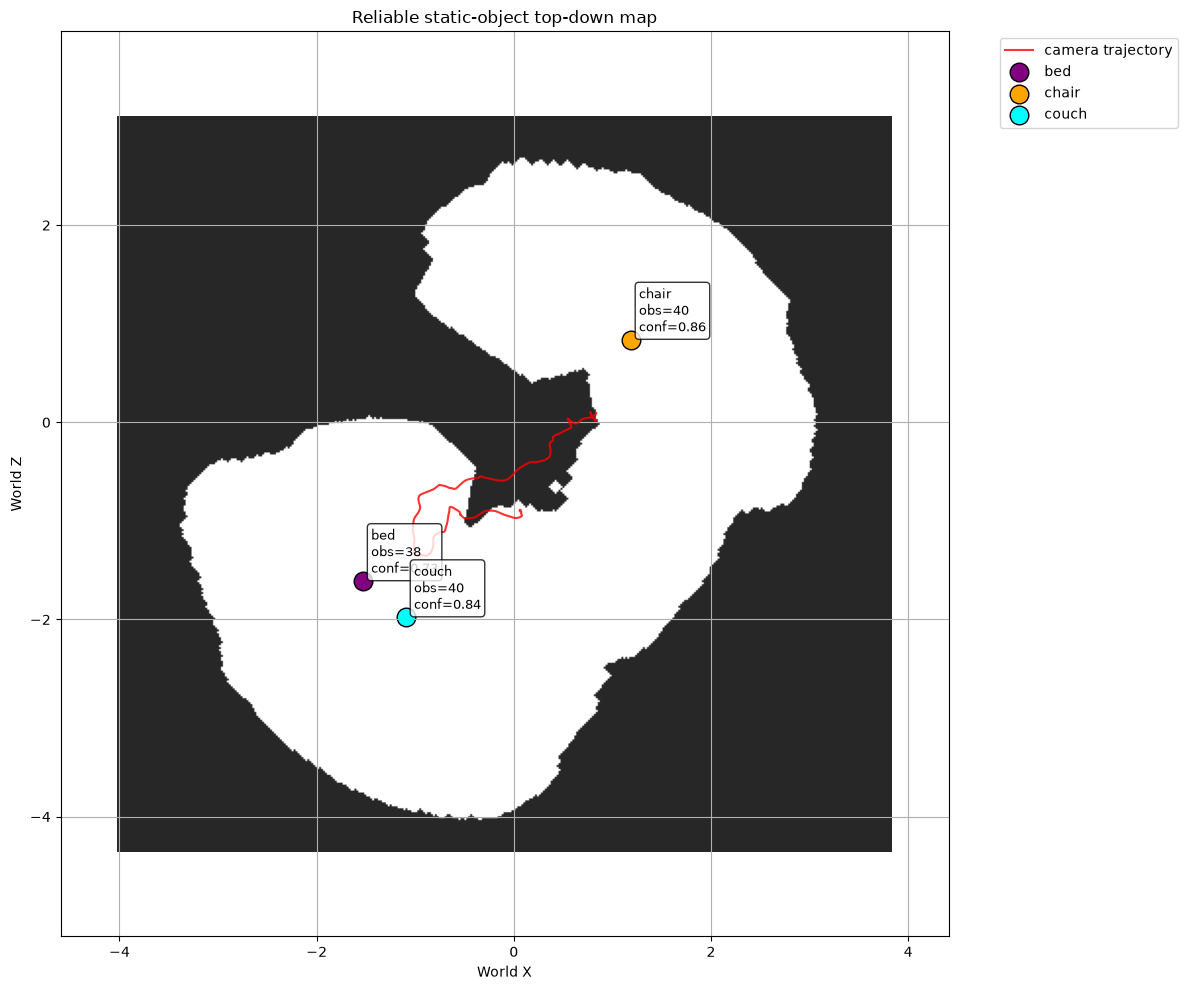

Saved: D:/VLM-maps/outputs/reconstruction_outputs\reliable_static_object_map.png


In [74]:
# ============================================================
# RELIABLE STATIC OBJECT MAP
# ============================================================

plt.figure(figsize=(12, 10))

plt.imshow(
    occupancy_image,
    cmap="gray",
    origin="lower",
    extent=[
        map_x_min,
        map_x_max,
        map_z_min,
        map_z_max,
    ],
    alpha=0.85,
)

plt.plot(
    pose_x,
    pose_z,
    color="red",
    linewidth=1.5,
    alpha=0.8,
    label="camera trajectory",
)

colors = {
    "bed": "purple",
    "chair": "orange",
    "couch": "cyan",
    "refrigerator": "blue",
    "book": "green",
}

for _, row in reliable_objects.iterrows():

    color = colors.get(
        row["class_name"],
        "yellow",
    )

    plt.scatter(
        row["world_x"],
        row["world_z"],
        s=180,
        color=color,
        edgecolors="black",
        linewidths=1,
        label=row["class_name"],
    )

    plt.annotate(
        (
            f"{row['class_name']}\n"
            f"obs={int(row['observations'])}\n"
            f"conf={row['mean_confidence']:.2f}"
        ),
        (
            row["world_x"],
            row["world_z"],
        ),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=9,
        bbox=dict(
            boxstyle="round,pad=0.3",
            facecolor="white",
            alpha=0.8,
        ),
    )

plt.xlabel("World X")
plt.ylabel("World Z")
plt.title(
    "Reliable static-object top-down map"
)
plt.axis("equal")
plt.grid(True)

# Remove duplicate legend labels.
handles, labels = plt.gca().get_legend_handles_labels()
unique = dict(zip(labels, handles))

plt.legend(
    unique.values(),
    unique.keys(),
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

reliable_map_path = os.path.join(
    OUTPUT_DIR,
    "reliable_static_object_map.png",
)

plt.tight_layout()
plt.savefig(
    reliable_map_path,
    dpi=200,
)

plt.show()

print(
    "Saved:",
    reliable_map_path,
)

In [75]:
for eps_value in [0.20, 0.30, 0.40, 0.50]:
    print("Testing eps:", eps_value)

    for class_name, group in detections_df.groupby(
        "class_name"
    ):
        coordinates = group[
            ["world_x", "world_z"]
        ].to_numpy()

        if len(coordinates) < 2:
            continue

        labels = DBSCAN(
            eps=eps_value,
            min_samples=3,
        ).fit_predict(coordinates)

        valid_labels = set(labels)
        valid_labels.discard(-1)

        print(
            class_name,
            "clusters:",
            len(valid_labels),
        )

Testing eps: 0.2
bed clusters: 1
book clusters: 0
chair clusters: 2
couch clusters: 3
person clusters: 1
refrigerator clusters: 0
Testing eps: 0.3
bed clusters: 1
book clusters: 0
chair clusters: 2
couch clusters: 3
person clusters: 1
refrigerator clusters: 0
Testing eps: 0.4
bed clusters: 1


book clusters: 0
chair clusters: 1
couch clusters: 3
person clusters: 1
refrigerator clusters: 0
Testing eps: 0.5
bed clusters: 1
book clusters: 0
chair clusters: 1
couch clusters: 3
person clusters: 1


refrigerator clusters: 0


In [76]:
# ============================================================
# CREATE FINAL DOWNLOADABLE POINT-CLOUD FILES
# ============================================================

import os
import numpy as np
import open3d as o3d


# ------------------------------------------------------------
# 1. Confirm the current cloud
# ------------------------------------------------------------

if "pcd" not in globals():
    raise RuntimeError(
        "Variable 'pcd' does not exist. "
        "Run the point-cloud fusion cell first."
    )

if len(pcd.points) == 0:
    raise RuntimeError(
        "The current point cloud is empty."
    )

print(
    "Current point count:",
    f"{len(pcd.points):,}",
)


# ------------------------------------------------------------
# 2. Make a copy and clean it
# ------------------------------------------------------------

final_pcd = o3d.geometry.PointCloud(pcd)

# Remove statistical outliers.
# Skip this if the cloud becomes too sparse.
if len(final_pcd.points) > 100:
    final_pcd, inlier_indices = (
        final_pcd.remove_statistical_outlier(
            nb_neighbors=20,
            std_ratio=2.0,
        )
    )

# Use 2 cm voxels for a detailed output.
final_pcd_2cm = final_pcd.voxel_down_sample(
    voxel_size=0.02
)

# Use 5 cm voxels for a lighter online-viewer output.
final_pcd_5cm = final_pcd.voxel_down_sample(
    voxel_size=0.05
)


# ------------------------------------------------------------
# 3. Save PLY files
# ------------------------------------------------------------

ply_2cm_path = os.path.join(
    OUTPUT_DIR,
    "complete_room_pointcloud_2cm.ply",
)

ply_5cm_path = os.path.join(
    OUTPUT_DIR,
    "complete_room_pointcloud_5cm_online.ply",
)

success_2cm = o3d.io.write_point_cloud(
    ply_2cm_path,
    final_pcd_2cm,
    write_ascii=False,
)

success_5cm = o3d.io.write_point_cloud(
    ply_5cm_path,
    final_pcd_5cm,
    write_ascii=False,
)

if not success_2cm:
    raise RuntimeError(
        f"Could not save {ply_2cm_path}"
    )

if not success_5cm:
    raise RuntimeError(
        f"Could not save {ply_5cm_path}"
    )


# ------------------------------------------------------------
# 4. Save XYZ backup
# ------------------------------------------------------------

xyz_path = os.path.join(
    OUTPUT_DIR,
    "complete_room_pointcloud_5cm.xyz",
)

points_5cm = np.asarray(
    final_pcd_5cm.points
)

colors_5cm = np.asarray(
    final_pcd_5cm.colors
)

if len(colors_5cm) == len(points_5cm):
    xyzrgb = np.column_stack(
        [
            points_5cm,
            np.clip(colors_5cm * 255, 0, 255)
            .astype(np.uint8),
        ]
    )

    np.savetxt(
        xyz_path,
        xyzrgb,
        fmt=[
            "%.6f",
            "%.6f",
            "%.6f",
            "%d",
            "%d",
            "%d",
        ],
        header="x y z red green blue",
        comments="",
    )
else:
    np.savetxt(
        xyz_path,
        points_5cm,
        fmt="%.6f",
        header="x y z",
        comments="",
    )


# ------------------------------------------------------------
# 5. Print file information
# ------------------------------------------------------------

for path in [
    ply_2cm_path,
    ply_5cm_path,
    xyz_path,
]:
    print(
        os.path.basename(path),
        "| exists:",
        os.path.exists(path),
        "| size MB:",
        round(
            os.path.getsize(path) / (1024 ** 2),
            2,
        )
        if os.path.exists(path)
        else None,
    )

print("\n2 cm points:", f"{len(final_pcd_2cm.points):,}")
print("5 cm points:", f"{len(final_pcd_5cm.points):,}")

Current point count: 5,441,387


complete_room_pointcloud_2cm.ply | exists: True | size MB: 134.86
complete_room_pointcloud_5cm_online.ply | exists: True | size MB: 23.46
complete_room_pointcloud_5cm.xyz | exists: True | size MB: 35.45

2 cm points: 5,237,484
5 cm points: 911,180


In [77]:
# ============================================================
# BUILD DOWNLOADABLE QUALITATIVE POINT CLOUD
# FROM 8-BIT RELATIVE DEPTH + CAMERA POSES
# ============================================================

import os
import numpy as np
import open3d as o3d
from PIL import Image


# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required_variables = [
    "rgb_files",
    "depth_files",
    "poses",
    "OUTPUT_DIR",
    "pose_to_matrix_camera_to_world",
    "transform_points",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Missing variables/functions:\n"
        + "\n".join(missing_variables)
        + "\n\nRun the setup and qualitative-map cells first."
    )


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

FRAME_STEP = 5
PIXEL_STEP = 2

# Provisional camera intrinsics.
# These are used only to create qualitative geometry.
FX = 200.0
FY = 200.0
CX = 96.0
CY = 127.712

# Relative-depth pseudo-distance.
PSEUDO_NEAR = 0.5
PSEUDO_FAR = 2.5

# Voxel sizes.
ONLINE_VOXEL_SIZE = 0.05
HIGH_DETAIL_VOXEL_SIZE = 0.02


# ------------------------------------------------------------
# 3. Load image dimensions
# ------------------------------------------------------------

sample_depth = np.load(
    depth_files[0]
).astype(np.float32)

DEPTH_H, DEPTH_W = sample_depth.shape


# ------------------------------------------------------------
# 4. Relative-depth conversion
# ------------------------------------------------------------

def convert_to_relative_depth(depth_raw):
    depth_raw = depth_raw.astype(np.float32)

    valid = (
        np.isfinite(depth_raw)
        & (depth_raw > 0)
    )

    relative = np.zeros_like(
        depth_raw,
        dtype=np.float32,
    )

    if valid.sum() == 0:
        return relative, valid

    low, high = np.percentile(
        depth_raw[valid],
        [5, 98],
    )

    clipped = np.clip(
        depth_raw,
        low,
        high,
    )

    relative[valid] = (
        clipped[valid] - low
    ) / max(high - low, 1e-6)

    return relative, valid


# ------------------------------------------------------------
# 5. Load colors
# ------------------------------------------------------------

def load_resized_rgb(rgb_path):
    rgb = np.asarray(
        Image.open(rgb_path).convert("RGB")
    )

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR,
        )
    )

    return rgb_small.astype(np.float32) / 255.0


# ------------------------------------------------------------
# 6. Create qualitative world point cloud
# ------------------------------------------------------------

world_points = []
world_colors = []

frame_indices = np.arange(
    0,
    len(depth_files),
    FRAME_STEP,
    dtype=np.int32,
)

print(
    "Processing frames:",
    len(frame_indices),
)

for count, frame_idx in enumerate(frame_indices):

    depth_raw = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    relative, valid = convert_to_relative_depth(
        depth_raw
    )

    v, u = np.indices(
        depth_raw.shape
    )

    keep = (
        valid
        & ((u % PIXEL_STEP) == 0)
        & ((v % PIXEL_STEP) == 0)
    )

    v_sel = v[keep]
    u_sel = u[keep]
    relative_sel = relative[keep]

    # Convert relative depth to pseudo-distance.
    pseudo_z = (
        PSEUDO_NEAR
        + relative_sel
        * (PSEUDO_FAR - PSEUDO_NEAR)
    )

    x_camera = (
        (u_sel - CX)
        * pseudo_z
        / FX
    )

    y_camera = (
        (v_sel - CY)
        * pseudo_z
        / FY
    )

    points_camera = np.column_stack(
        [
            x_camera,
            y_camera,
            pseudo_z,
        ]
    )

    T_camera_to_world = (
        pose_to_matrix_camera_to_world(
            poses[frame_idx]
        )
    )

    points_world = transform_points(
        points_camera,
        T_camera_to_world,
    )

    rgb_small = load_resized_rgb(
        rgb_files[frame_idx]
    )

    colors = rgb_small[keep]

    finite = np.isfinite(
        points_world
    ).all(axis=1)

    world_points.append(
        points_world[finite]
    )

    world_colors.append(
        colors[finite]
    )

    if count % 50 == 0:
        print(
            f"Processed frame {frame_idx:04d}"
        )


if not world_points:
    raise RuntimeError(
        "No world points were generated."
    )

world_points = np.vstack(world_points)
world_colors = np.vstack(world_colors)

print(
    "Raw qualitative points:",
    f"{len(world_points):,}",
)


# ------------------------------------------------------------
# 7. Remove extreme outliers
# ------------------------------------------------------------

finite = np.isfinite(
    world_points
).all(axis=1)

world_points = world_points[finite]
world_colors = world_colors[finite]

low = np.percentile(
    world_points,
    0.5,
    axis=0,
)

high = np.percentile(
    world_points,
    99.5,
    axis=0,
)

inside = np.all(
    (world_points >= low)
    & (world_points <= high),
    axis=1,
)

world_points = world_points[inside]
world_colors = world_colors[inside]

print(
    "After outlier filtering:",
    f"{len(world_points):,}",
)


# ------------------------------------------------------------
# 8. Create Open3D cloud
# ------------------------------------------------------------

qualitative_pcd = o3d.geometry.PointCloud()

qualitative_pcd.points = (
    o3d.utility.Vector3dVector(
        world_points
    )
)

qualitative_pcd.colors = (
    o3d.utility.Vector3dVector(
        world_colors
    )
)


# ------------------------------------------------------------
# 9. Remove statistical outliers
# ------------------------------------------------------------

if len(qualitative_pcd.points) > 100:
    qualitative_pcd, _ = (
        qualitative_pcd.remove_statistical_outlier(
            nb_neighbors=20,
            std_ratio=2.5,
        )
    )


# ------------------------------------------------------------
# 10. Create two PLY resolutions
# ------------------------------------------------------------

online_pcd = qualitative_pcd.voxel_down_sample(
    voxel_size=ONLINE_VOXEL_SIZE
)

high_detail_pcd = qualitative_pcd.voxel_down_sample(
    voxel_size=HIGH_DETAIL_VOXEL_SIZE
)


# ------------------------------------------------------------
# 11. Save files
# ------------------------------------------------------------

online_ply_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_room_pointcloud_online_5cm.ply",
)

high_detail_ply_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_room_pointcloud_detail_2cm.ply",
)

o3d.io.write_point_cloud(
    online_ply_path,
    online_pcd,
    write_ascii=False,
)

o3d.io.write_point_cloud(
    high_detail_ply_path,
    high_detail_pcd,
    write_ascii=False,
)


# Keep this variable for later cells.
pcd = online_pcd


# ------------------------------------------------------------
# 12. Verify output
# ------------------------------------------------------------

for path, cloud in [
    (online_ply_path, online_pcd),
    (high_detail_ply_path, high_detail_pcd),
]:

    print(
        "\nFile:",
        path,
    )
    print(
        "Exists:",
        os.path.exists(path),
    )
    print(
        "Size MB:",
        round(
            os.path.getsize(path) / (1024 ** 2),
            2,
        )
        if os.path.exists(path)
        else None,
    )
    print(
        "Points:",
        f"{len(cloud.points):,}",
    )

Processing frames: 419
Processed frame 0000


Processed frame 0250


Processed frame 0500


Processed frame 0750


Processed frame 1000


...

Processed frame 1750


Processed frame 2000


Raw qualitative points: 5,147,924


After outlier filtering: 4,994,369



File: D:/VLM-maps/outputs/reconstruction_outputs\qualitative_room_pointcloud_online_5cm.ply
Exists: True
Size MB: 6.08
Points: 235,987

File: D:/VLM-maps/outputs/reconstruction_outputs\qualitative_room_pointcloud_detail_2cm.ply
Exists: True
Size MB: 50.9
Points: 1,976,603


In [78]:
# ============================================================
# BUILD DOWNLOADABLE QUALITATIVE POINT CLOUD
# FROM 8-BIT RELATIVE DEPTH + CAMERA POSES
# ============================================================

import os
import numpy as np
import open3d as o3d
from PIL import Image


# ------------------------------------------------------------
# 1. Check required variables
# ------------------------------------------------------------

required_variables = [
    "rgb_files",
    "depth_files",
    "poses",
    "OUTPUT_DIR",
    "pose_to_matrix_camera_to_world",
    "transform_points",
]

missing_variables = [
    name
    for name in required_variables
    if name not in globals()
]

if missing_variables:
    raise RuntimeError(
        "Missing variables/functions:\n"
        + "\n".join(missing_variables)
        + "\n\nRun the setup and qualitative-map cells first."
    )


# ------------------------------------------------------------
# 2. Configuration
# ------------------------------------------------------------

FRAME_STEP = 5
PIXEL_STEP = 2

# Provisional camera intrinsics.
# These are used only to create qualitative geometry.
FX = 200.0
FY = 200.0
CX = 96.0
CY = 127.712

# Relative-depth pseudo-distance.
PSEUDO_NEAR = 0.5
PSEUDO_FAR = 2.5

# Voxel sizes.
ONLINE_VOXEL_SIZE = 0.05
HIGH_DETAIL_VOXEL_SIZE = 0.02


# ------------------------------------------------------------
# 3. Load image dimensions
# ------------------------------------------------------------

sample_depth = np.load(
    depth_files[0]
).astype(np.float32)

DEPTH_H, DEPTH_W = sample_depth.shape


# ------------------------------------------------------------
# 4. Relative-depth conversion
# ------------------------------------------------------------

def convert_to_relative_depth(depth_raw):
    depth_raw = depth_raw.astype(np.float32)

    valid = (
        np.isfinite(depth_raw)
        & (depth_raw > 0)
    )

    relative = np.zeros_like(
        depth_raw,
        dtype=np.float32,
    )

    if valid.sum() == 0:
        return relative, valid

    low, high = np.percentile(
        depth_raw[valid],
        [5, 98],
    )

    clipped = np.clip(
        depth_raw,
        low,
        high,
    )

    relative[valid] = (
        clipped[valid] - low
    ) / max(high - low, 1e-6)

    return relative, valid


# ------------------------------------------------------------
# 5. Load colors
# ------------------------------------------------------------

def load_resized_rgb(rgb_path):
    rgb = np.asarray(
        Image.open(rgb_path).convert("RGB")
    )

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR,
        )
    )

    return rgb_small.astype(np.float32) / 255.0


# ------------------------------------------------------------
# 6. Create qualitative world point cloud
# ------------------------------------------------------------

world_points = []
world_colors = []

frame_indices = np.arange(
    0,
    len(depth_files),
    FRAME_STEP,
    dtype=np.int32,
)

print(
    "Processing frames:",
    len(frame_indices),
)

for count, frame_idx in enumerate(frame_indices):

    depth_raw = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    relative, valid = convert_to_relative_depth(
        depth_raw
    )

    v, u = np.indices(
        depth_raw.shape
    )

    keep = (
        valid
        & ((u % PIXEL_STEP) == 0)
        & ((v % PIXEL_STEP) == 0)
    )

    v_sel = v[keep]
    u_sel = u[keep]
    relative_sel = relative[keep]

    # Convert relative depth to pseudo-distance.
    pseudo_z = (
        PSEUDO_NEAR
        + relative_sel
        * (PSEUDO_FAR - PSEUDO_NEAR)
    )

    x_camera = (
        (u_sel - CX)
        * pseudo_z
        / FX
    )

    y_camera = (
        (v_sel - CY)
        * pseudo_z
        / FY
    )

    points_camera = np.column_stack(
        [
            x_camera,
            y_camera,
            pseudo_z,
        ]
    )

    T_camera_to_world = (
        pose_to_matrix_camera_to_world(
            poses[frame_idx]
        )
    )

    points_world = transform_points(
        points_camera,
        T_camera_to_world,
    )

    rgb_small = load_resized_rgb(
        rgb_files[frame_idx]
    )

    colors = rgb_small[keep]

    finite = np.isfinite(
        points_world
    ).all(axis=1)

    world_points.append(
        points_world[finite]
    )

    world_colors.append(
        colors[finite]
    )

    if count % 50 == 0:
        print(
            f"Processed frame {frame_idx:04d}"
        )


if not world_points:
    raise RuntimeError(
        "No world points were generated."
    )

world_points = np.vstack(world_points)
world_colors = np.vstack(world_colors)

print(
    "Raw qualitative points:",
    f"{len(world_points):,}",
)


# ------------------------------------------------------------
# 7. Remove extreme outliers
# ------------------------------------------------------------

finite = np.isfinite(
    world_points
).all(axis=1)

world_points = world_points[finite]
world_colors = world_colors[finite]

low = np.percentile(
    world_points,
    0.5,
    axis=0,
)

high = np.percentile(
    world_points,
    99.5,
    axis=0,
)

inside = np.all(
    (world_points >= low)
    & (world_points <= high),
    axis=1,
)

world_points = world_points[inside]
world_colors = world_colors[inside]

print(
    "After outlier filtering:",
    f"{len(world_points):,}",
)


# ------------------------------------------------------------
# 8. Create Open3D cloud
# ------------------------------------------------------------

qualitative_pcd = o3d.geometry.PointCloud()

qualitative_pcd.points = (
    o3d.utility.Vector3dVector(
        world_points
    )
)

qualitative_pcd.colors = (
    o3d.utility.Vector3dVector(
        world_colors
    )
)


# ------------------------------------------------------------
# 9. Remove statistical outliers
# ------------------------------------------------------------

if len(qualitative_pcd.points) > 100:
    qualitative_pcd, _ = (
        qualitative_pcd.remove_statistical_outlier(
            nb_neighbors=20,
            std_ratio=2.5,
        )
    )


# ------------------------------------------------------------
# 10. Create two PLY resolutions
# ------------------------------------------------------------

online_pcd = qualitative_pcd.voxel_down_sample(
    voxel_size=ONLINE_VOXEL_SIZE
)

high_detail_pcd = qualitative_pcd.voxel_down_sample(
    voxel_size=HIGH_DETAIL_VOXEL_SIZE
)


# ------------------------------------------------------------
# 11. Save files
# ------------------------------------------------------------

online_ply_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_room_pointcloud_online_5cm.ply",
)

high_detail_ply_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_room_pointcloud_detail_2cm.ply",
)

o3d.io.write_point_cloud(
    online_ply_path,
    online_pcd,
    write_ascii=False,
)

o3d.io.write_point_cloud(
    high_detail_ply_path,
    high_detail_pcd,
    write_ascii=False,
)


# Keep this variable for later cells.
pcd = online_pcd


# ------------------------------------------------------------
# 12. Verify output
# ------------------------------------------------------------

for path, cloud in [
    (online_ply_path, online_pcd),
    (high_detail_ply_path, high_detail_pcd),
]:

    print(
        "\nFile:",
        path,
    )
    print(
        "Exists:",
        os.path.exists(path),
    )
    print(
        "Size MB:",
        round(
            os.path.getsize(path) / (1024 ** 2),
            2,
        )
        if os.path.exists(path)
        else None,
    )
    print(
        "Points:",
        f"{len(cloud.points):,}",
    )

Processing frames: 419
Processed frame 0000


Processed frame 0250


Processed frame 0500


Processed frame 0750


Processed frame 1000


...

Processed frame 1750


Processed frame 2000


Raw qualitative points: 5,147,924


After outlier filtering: 4,994,369



File: D:/VLM-maps/outputs/reconstruction_outputs\qualitative_room_pointcloud_online_5cm.ply
Exists: True
Size MB: 6.08
Points: 235,987

File: D:/VLM-maps/outputs/reconstruction_outputs\qualitative_room_pointcloud_detail_2cm.ply
Exists: True
Size MB: 50.9
Points: 1,976,603


In [79]:
def pose_to_matrix_camera_to_world(pose_row):
    tx, ty, tz, qx, qy, qz, qw = pose_row

    quaternion = np.array(
        [qx, qy, qz, qw],
        dtype=np.float64,
    )

    quaternion = quaternion / np.linalg.norm(
        quaternion
    )

    R_camera_to_world = (
        Rotation.from_quat(
            quaternion
        ).as_matrix()
    )

    T_camera_to_world = np.eye(
        4,
        dtype=np.float64,
    )

    T_camera_to_world[:3, :3] = (
        R_camera_to_world
    )

    T_camera_to_world[:3, 3] = [
        tx,
        ty,
        tz,
    ]

    return T_camera_to_world


def transform_points(
    points_camera,
    T_camera_to_world,
):
    points_h = np.column_stack(
        [
            points_camera,
            np.ones(
                len(points_camera)
            ),
        ]
    )

    return (
        T_camera_to_world
        @ points_h.T
    ).T[:, :3]

In [80]:
# ============================================================
# FINAL QUALITATIVE ROOM MAP + ANIMATION + PLY
# ============================================================

import os
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import open3d as o3d

from PIL import Image
from scipy.spatial.transform import Rotation


# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

DATASET = (
    "D:/VLM-maps/dataset/content/vlmaps_dataset/my_custom_scene"
)

RGB_DIR = os.path.join(DATASET, "rgb")
DEPTH_DIR = os.path.join(DATASET, "depth")
POSES_FILE = os.path.join(DATASET, "poses.txt")

OUTPUT_DIR = "D:/VLM-maps/outputs/final_vlmaps_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


# ------------------------------------------------------------
# 2. File loading
# ------------------------------------------------------------

def numeric_stem(path):
    stem = os.path.splitext(
        os.path.basename(path)
    )[0]

    digits = "".join(
        c for c in stem
        if c.isdigit()
    )

    return int(digits) if digits else -1


rgb_files = sorted(
    [
        os.path.join(RGB_DIR, f)
        for f in os.listdir(RGB_DIR)
        if f.lower().endswith(
            (".png", ".jpg", ".jpeg")
        )
    ],
    key=numeric_stem,
)

depth_files = sorted(
    [
        os.path.join(DEPTH_DIR, f)
        for f in os.listdir(DEPTH_DIR)
        if f.lower().endswith(".npy")
    ],
    key=numeric_stem,
)

poses = np.loadtxt(
    POSES_FILE,
    dtype=np.float64,
)

if poses.ndim == 1:
    poses = poses.reshape(1, -1)

assert len(rgb_files) == len(depth_files)
assert len(poses) == len(rgb_files)
assert poses.shape[1] == 7

print("RGB:", len(rgb_files))
print("Depth:", len(depth_files))
print("Poses:", poses.shape)


# ------------------------------------------------------------
# 3. Image dimensions and provisional intrinsics
# ------------------------------------------------------------

sample_depth = np.load(
    depth_files[0]
).astype(np.float32)

sample_rgb = np.asarray(
    Image.open(
        rgb_files[0]
    ).convert("RGB")
)

DEPTH_H, DEPTH_W = sample_depth.shape
RGB_H, RGB_W = sample_rgb.shape[:2]

FX_RGB = 750.0
FY_RGB = 750.0
CX_RGB = 360.0
CY_RGB = 478.92

FX = FX_RGB * DEPTH_W / RGB_W
FY = FY_RGB * DEPTH_H / RGB_H
CX = CX_RGB * DEPTH_W / RGB_W
CY = CY_RGB * DEPTH_H / RGB_H

print("RGB size:", RGB_H, RGB_W)
print("Depth size:", DEPTH_H, DEPTH_W)
print("Provisional intrinsics:", FX, FY, CX, CY)


# ------------------------------------------------------------
# 4. Pose functions
# ------------------------------------------------------------

def pose_to_matrix(pose_row):
    tx, ty, tz, qx, qy, qz, qw = pose_row

    quaternion = np.array(
        [qx, qy, qz, qw],
        dtype=np.float64,
    )

    quaternion /= np.linalg.norm(
        quaternion
    )

    R = Rotation.from_quat(
        quaternion
    ).as_matrix()

    T = np.eye(4)

    T[:3, :3] = R
    T[:3, 3] = [
        tx,
        ty,
        tz,
    ]

    return T


def transform_points(points, T):
    points_h = np.column_stack(
        [
            points,
            np.ones(len(points)),
        ]
    )

    return (
        T @ points_h.T
    ).T[:, :3]


# ------------------------------------------------------------
# 5. Relative depth
# ------------------------------------------------------------

def normalized_relative_depth(depth):
    depth = depth.astype(np.float32)

    valid = (
        np.isfinite(depth)
        & (depth > 0)
    )

    relative = np.zeros_like(
        depth,
        dtype=np.float32,
    )

    if valid.sum() == 0:
        return relative, valid

    low, high = np.percentile(
        depth[valid],
        [5, 98],
    )

    relative[valid] = (
        np.clip(
            depth[valid],
            low,
            high,
        ) - low
    ) / max(high - low, 1e-6)

    return relative, valid


# ------------------------------------------------------------
# 6. Pseudo-depth point generation
# ------------------------------------------------------------

PSEUDO_NEAR = 0.5
PSEUDO_FAR = 2.5
PIXEL_STEP = 3


def frame_to_world_points(
    frame_idx,
):
    depth = np.load(
        depth_files[frame_idx]
    ).astype(np.float32)

    rgb = np.asarray(
        Image.open(
            rgb_files[frame_idx]
        ).convert("RGB")
    )

    rgb_small = np.asarray(
        Image.fromarray(rgb).resize(
            (DEPTH_W, DEPTH_H),
            Image.Resampling.BILINEAR,
        )
    ).astype(np.float32) / 255.0

    relative, valid = (
        normalized_relative_depth(
            depth
        )
    )

    v_grid, u_grid = np.indices(
        depth.shape
    )

    keep = (
        valid
        & ((u_grid % PIXEL_STEP) == 0)
        & ((v_grid % PIXEL_STEP) == 0)
    )

    u = u_grid[keep]
    v = v_grid[keep]
    d = relative[keep]

    z = (
        PSEUDO_NEAR
        + d
        * (PSEUDO_FAR - PSEUDO_NEAR)
    )

    x = (
        (u - CX)
        * z
        / FX
    )

    y = (
        (v - CY)
        * z
        / FY
    )

    points_camera = np.column_stack(
        [
            x,
            y,
            z,
        ]
    )

    T = pose_to_matrix(
        poses[frame_idx]
    )

    points_world = transform_points(
        points_camera,
        T,
    )

    colors = rgb_small[keep]

    return points_world, colors


# ------------------------------------------------------------
# 7. Define fixed top-down map bounds
# ------------------------------------------------------------

pose_x = poses[:, 0]
pose_z = poses[:, 2]

MARGIN = 3.0
RESOLUTION = 0.02

xmin = pose_x.min() - MARGIN
xmax = pose_x.max() + MARGIN
zmin = pose_z.min() - MARGIN
zmax = pose_z.max() + MARGIN

MAP_W = int(
    np.ceil(
        (xmax - xmin)
        / RESOLUTION
    )
) + 1

MAP_H = int(
    np.ceil(
        (zmax - zmin)
        / RESOLUTION
    )
) + 1

print("Map:", MAP_W, MAP_H)


def world_to_grid(x, z):
    gx = np.floor(
        (x - xmin)
        / RESOLUTION
    ).astype(np.int32)

    gz = np.floor(
        (z - zmin)
        / RESOLUTION
    ).astype(np.int32)

    valid = (
        (gx >= 0)
        & (gx < MAP_W)
        & (gz >= 0)
        & (gz < MAP_H)
    )

    return gx, gz, valid


# ------------------------------------------------------------
# 8. Build the final qualitative PLY
# ------------------------------------------------------------

FRAME_STEP = 5

all_points = []
all_colors = []

for count, frame_idx in enumerate(
    range(0, len(rgb_files), FRAME_STEP)
):

    points_world, colors = (
        frame_to_world_points(
            frame_idx
        )
    )

    finite = np.isfinite(
        points_world
    ).all(axis=1)

    all_points.append(
        points_world[finite]
    )

    all_colors.append(
        colors[finite]
    )

    if count % 50 == 0:
        print(
            f"Processed frame {frame_idx:04d}"
        )

all_points = np.vstack(all_points)
all_colors = np.vstack(all_colors)

# Robust world-coordinate filtering.
low = np.percentile(
    all_points,
    0.5,
    axis=0,
)

high = np.percentile(
    all_points,
    99.5,
    axis=0,
)

inside = np.all(
    (all_points >= low)
    & (all_points <= high),
    axis=1,
)

all_points = all_points[inside]
all_colors = all_colors[inside]

cloud = o3d.geometry.PointCloud()

cloud.points = (
    o3d.utility.Vector3dVector(
        all_points
    )
)

cloud.colors = (
    o3d.utility.Vector3dVector(
        all_colors
    )
)

cloud, _ = (
    cloud.remove_statistical_outlier(
        nb_neighbors=20,
        std_ratio=2.5,
    )
)

cloud_online = cloud.voxel_down_sample(
    voxel_size=0.05
)

ply_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_room_vlmaps_style.ply",
)

o3d.io.write_point_cloud(
    ply_path,
    cloud_online,
)

print(
    "PLY saved:",
    ply_path,
)

print(
    "PLY points:",
    len(cloud_online.points),
)


# ------------------------------------------------------------
# 9. Create top-down occupancy image
# ------------------------------------------------------------

occupancy = np.zeros(
    (MAP_H, MAP_W),
    dtype=np.float32,
)

for point in np.asarray(
    cloud_online.points
):

    gx, gz, valid = world_to_grid(
        np.array([point[0]]),
        np.array([point[2]]),
    )

    if valid[0]:
        occupancy[gz[0], gx[0]] += 1


occupancy = np.log1p(
    occupancy
)

if occupancy.max() > 0:
    occupancy /= occupancy.max()

occupancy_image = (
    occupancy * 255
).astype(np.uint8)

occupancy_path = os.path.join(
    OUTPUT_DIR,
    "qualitative_topdown_final.png",
)

Image.fromarray(
    occupancy_image
).save(
    occupancy_path
)

print(
    "Occupancy saved:",
    occupancy_path,
)


# ------------------------------------------------------------
# 10. Create VLMaps-style animation
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
)

rgb_ax, map_ax = axes

rgb_display = rgb_ax.imshow(
    np.zeros(
        (
            RGB_H,
            RGB_W,
            3,
        ),
        dtype=np.uint8,
    )
)

rgb_ax.axis("off")
rgb_ax.set_title(
    "Current RGB frame"
)

map_ax.imshow(
    occupancy_image,
    cmap="gray",
    origin="lower",
    extent=[
        xmin,
        xmax,
        zmin,
        zmax,
    ],
    alpha=0.85,
)

trajectory_line, = map_ax.plot(
    [],
    [],
    "r-",
    linewidth=2,
)

robot_marker, = map_ax.plot(
    [],
    [],
    "ro",
    markersize=8,
)

map_ax.set_xlim(
    xmin,
    xmax,
)

map_ax.set_ylim(
    zmin,
    zmax,
)

map_ax.set_xlabel("World X")
map_ax.set_ylabel("World Z")
map_ax.set_title(
    "Animated top-down room map"
)
map_ax.grid(True)
map_ax.set_aspect("equal")


animation_indices = list(
    range(
        0,
        len(rgb_files),
        10,
    )
)


def initialize():
    rgb_display.set_data(
        np.zeros(
            (
                RGB_H,
                RGB_W,
                3,
            ),
            dtype=np.uint8,
        )
    )

    trajectory_line.set_data(
        [],
        [],
    )

    robot_marker.set_data(
        [],
        [],
    )

    return (
        rgb_display,
        trajectory_line,
        robot_marker,
    )


def update(frame_idx):
    rgb = np.asarray(
        Image.open(
            rgb_files[frame_idx]
        ).convert("RGB")
    )

    rgb_display.set_data(
        rgb
    )

    trajectory_line.set_data(
        pose_x[:frame_idx + 1],
        pose_z[:frame_idx + 1],
    )

    robot_marker.set_data(
        [pose_x[frame_idx]],
        [pose_z[frame_idx]],
    )

    map_ax.set_title(
        f"Top-down map | frame {frame_idx}"
    )

    return (
        rgb_display,
        trajectory_line,
        robot_marker,
    )


ani = animation.FuncAnimation(
    fig,
    update,
    frames=animation_indices,
    init_func=initialize,
    interval=50,
    blit=True,
)

mp4_path = os.path.join(
    OUTPUT_DIR,
    "vlmaps_style_room_animation.mp4",
)

try:
    ani.save(
        mp4_path,
        writer="ffmpeg",
        fps=20,
        dpi=120,
    )

    print(
        "MP4 saved:",
        mp4_path,
    )

except Exception as exc:
    print(
        "MP4 export failed:",
        repr(exc),
    )

    gif_path = os.path.join(
        OUTPUT_DIR,
        "vlmaps_style_room_animation.gif",
    )

    ani.save(
        gif_path,
        writer="pillow",
        fps=15,
        dpi=100,
    )

    print(
        "GIF saved:",
        gif_path,
    )

plt.close(fig)


# ------------------------------------------------------------
# 11. Save metadata
# ------------------------------------------------------------

metadata = {
    "type": "qualitative_relative_depth_map",
    "depth_representation": (
        "8-bit-like relative depth; not metric"
    ),
    "pose_format": (
        "tx ty tz qx qy qz qw"
    ),
    "pose_assumption": "camera-to-world",
    "rgb_frames": len(rgb_files),
    "depth_frames": len(depth_files),
    "frame_step": FRAME_STEP,
    "pseudo_near": PSEUDO_NEAR,
    "pseudo_far": PSEUDO_FAR,
    "map_resolution": RESOLUTION,
    "map_margin": MARGIN,
    "topdown_axes": "world X-Z",
    "vertical_axis": "world Y",
    "provisional_intrinsics": {
        "fx": FX,
        "fy": FY,
        "cx": CX,
        "cy": CY,
    },
}

metadata_path = os.path.join(
    OUTPUT_DIR,
    "final_qualitative_map_metadata.json",
)

with open(metadata_path, "w") as f:
    json.dump(
        metadata,
        f,
        indent=2,
    )

print(
    "Metadata saved:",
    metadata_path,
)

RGB: 2091
Depth: 2091
Poses: (2091, 7)
RGB size: 960 720
Depth size: 256 192
Provisional intrinsics: 200.0 200.0 96.0 127.712
Map: 395 374
Processed frame 0000


Processed frame 0250


Processed frame 0500


Processed frame 0750


Processed frame 1000


...

Processed frame 1750


Processed frame 2000


PLY saved: D:/VLM-maps/outputs/final_vlmaps_outputs\qualitative_room_vlmaps_style.ply
PLY points: 222637


Occupancy saved: D:/VLM-maps/outputs/final_vlmaps_outputs\qualitative_topdown_final.png


MP4 saved: D:/VLM-maps/outputs/final_vlmaps_outputs\vlmaps_style_room_animation.mp4
Metadata saved: D:/VLM-maps/outputs/final_vlmaps_outputs\final_qualitative_map_metadata.json
